In [871]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, ScalarFormatter
import seaborn as sns
import matplotlib.dates as mdates
import locale
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [872]:
#just some aesthetical settings, please disregard
category_colors = {
    "APD": "#3267ee",
    "AL": "#D5CEB5",
    'service': '#74add1',
    'trucking': '#3891c1',
    'construction': '#11859a',
    'retail': '#027772',
    'other': '#015443',
    'agriculture': '#a3bcda',
    'AZ': '#8cb5d6',
    'TX': '#74add1',
    'NY': '#5da4cc',
    'IL': '#4b9ac6',
    'FL': '#3891c1',
    'OH': '#258bae',
    'GA': '#11859a',
    'WA': '#027f84',
    'NC': '#027772',
    'CO': '#016f5f',
    'CA': '#016350',
    'PA': '#015443'
}

sns.set_theme(
    style="whitegrid",
    rc={
        "text.color": "#A49280"
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Frutiger', 'Frutiger Next', 'Neue Frutiger', 'Segoe UI', 'Arial', 'DejaVu Sans']


locale.getlocale()

locale.setlocale(locale.LC_TIME, 'en_US')

formatter_money_ammounts = FuncFormatter(lambda y, _: f"{y*1e-3:,.0f}K")

pd.set_option('display.float_format', lambda x: '%.10f' % x)

In [873]:
df_train_auto_policies = pd.read_csv("../data/train.csv")

In [874]:
# Check categorical columns

categorical_features = ['coverage_type', 'business_type', 'state' ]

for col in categorical_features:
    print(df_train_auto_policies[col].unique())

['APD' 'AL']
['service' 'Trucking' 'Construction' 'Retail' 'Other' 'Service'
 'construction' 'other' 'trucking' 'SERVICE' 'TRUCKING' 'OTHER' 'RETAIL'
 'retail' 'CONSTRUCTION' 'Agriculture']
['AZ' 'TX' 'NY' 'IL' 'FL' 'OH' 'GA' 'WA' 'NC' 'CO' 'CA' 'PA']


In [875]:
# Convert 'business_type' to lowercase / will be part of pipeline
# we will also do this for the other categories in the pipeline
df_train_auto_policies['business_type'] = df_train_auto_policies['business_type'].str.lower()

In [876]:
df_train_auto_policies = df_train_auto_policies.drop_duplicates()
df_train_auto_policies.nunique()

policy_id                           15000
insured_id                           3702
snapshot_date                        1095
policy_effective_date                1248
policy_expiration_date               1250
coverage_type                           2
vehicle_count                          22
vehicle_avg_age                       138
driver_count                           18
driver_avg_age                        452
years_in_business                     374
prior_year_mileage_000               4326
business_type                           6
state                                  12
prior_apd_claim_count                   6
prior_al_claim_count                    5
prior_loss_amount                    7795
deductible                              5
coverage_limit_000                      4
annual_premium                      14776
payment_frequency                       3
risk_score_external                  7616
has_safety_program                      2
num_heavy_vehicles                

In [877]:
# Drop unwanted columns / will be part of cleaning pipeline
df_train_auto_policies = df_train_auto_policies.drop(columns=
['snapshot_date',
'deductible',
'coverage_limit_000',
'annual_premium',
'payment_frequency',
'late_payment_count',
'first_claim_reported_date',
'claim_paid_amount_current_period',
'claim_status_current_period',
'days_to_first_claim_report',
'insured_id'
])

In [878]:
# we will create categorical bins for some numerical columns, just for visualization purposes, not for modeling


df_train_auto_policies.describe()

,vehicle_count,vehicle_avg_age,driver_count,driver_avg_age,years_in_business,prior_year_mileage_000,prior_apd_claim_count,prior_al_claim_count,prior_loss_amount,risk_score_external,has_safety_program,num_heavy_vehicles,claim_count,total_loss_amount
count,15000.0000000000,15000.0000000000,15000.0000000000,14400.0000000000,15000.0000000000,14100.0000000000,15000.0000000000,15000.0000000000,13800.0000000000,14250.0000000000,15000.0000000000,15000.0000000000,15000.0000000000,15000.0000000000
mean,8.0128666667,5.0231000000,5.9960000000,42.1047916667,7.9896066667,203.9020212766,0.5870000000,0.3005333333,10002.9824702899,49.9687852632,0.4520000000,1.6080000000,0.1420666667,9702.9738746667
std,2.8464553283,2.4426599223,2.4257458543,8.0121999195,7.6198316321,135.2884745249,0.8032064965,0.5617538785,18363.0157771257,29.0511551934,0.4977072575,1.2634512603,0.4076290875,91831.7401081423
min,0.0000000000,0.0000000000,1.0000000000,21.0000000000,1.0000000000,6.4000000000,0.0000000000,0.0000000000,0.0000000000,0.0000000000,0.0000000000,0.0000000000,0.0000000000,0.0000000000
25%,6.0000000000,3.3000000000,4.0000000000,36.7000000000,2.3000000000,110.6000000000,0.0000000000,0.0000000000,0.0000000000,24.6300000000,0.0000000000,1.0000000000,0.0000000000,0.0000000000
50%,8.0000000000,5.0000000000,6.0000000000,42.1000000000,5.5000000000,170.6000000000,0.0000000000,0.0000000000,3821.1500000000,49.4850000000,0.0000000000,1.0000000000,0.0000000000,0.0000000000
75%,10.0000000000,6.7000000000,8.0000000000,47.5000000000,11.1000000000,259.8250000000,1.0000000000,1.0000000000,12825.3750000000,75.2650000000,1.0000000000,2.0000000000,0.0000000000,0.0000000000
max,21.0000000000,14.3000000000,18.0000000000,70.0000000000,40.0000000000,1639.1000000000,5.0000000000,4.0000000000,397270.1200000000,100.0000000000,1.0000000000,9.0000000000,7.0000000000,5871551.5499999998


In [879]:
bins_vehicle_count = [-1, 6, 8, 10, 21]
labels_vehicle_count = ['0-6', '7-8', '9-10', '11+']

df_train_auto_policies['vehicle_count_group'] = pd.cut(df_train_auto_policies['vehicle_count'], bins=bins_vehicle_count, labels=labels_vehicle_count)

bins_vehicle_avg_age = [-1, 3, 5, 7, 15]
labels_vehicle_avg_age = ['0-3', '3-5', '5-7', '7+']

df_train_auto_policies['avg_vehicle_age_group'] = pd.cut(df_train_auto_policies['vehicle_avg_age'], bins=bins_vehicle_avg_age, labels=labels_vehicle_avg_age)

bins_driver_count = [-1, 4, 6, 8, 19]
labels_driver_count = ['0-4', '5-6', '7-8', '9+']

df_train_auto_policies['driver_count_group'] = pd.cut(df_train_auto_policies['driver_count'], bins=bins_driver_count, labels=labels_driver_count)

bins_driver_avg_age = [20, 30, 40, 50, 70]
labels_driver_avg_age = ['20-30', '31-40', '41-50', '51+']

df_train_auto_policies['driver_avg_age_group'] = pd.cut(df_train_auto_policies['driver_avg_age'], bins=bins_driver_avg_age, labels=labels_driver_avg_age)

bins_years_in_business = [-1, 5, 10, 15, 50]
labels_years_in_business = ['0-5', '6-10', '11-15', '16+']

df_train_auto_policies['years_in_business_group'] = pd.cut(df_train_auto_policies['years_in_business'], bins=bins_years_in_business, labels=labels_years_in_business)

bins_prior_year_mileage_000 = [-1, 100, 200, 300, 10000]
labels_prior_year_mileage_000 = ['0-100', '101-200', '201-300', '301+']

df_train_auto_policies['prior_year_mileage_000_group'] = pd.cut(df_train_auto_policies['prior_year_mileage_000'], bins=bins_prior_year_mileage_000, labels=labels_prior_year_mileage_000)

In [880]:
# We create our aditional helper/targets

# we transform the dates to numeric values and create the had_claim target
# also during data analysis I found records from befor 2020-07 seem to be incomplete so we will clean them (only two records)
df_train_auto_policies['policy_expiration_date'] = pd.to_datetime(df_train_auto_policies['policy_expiration_date'])
df_train_auto_policies['policy_expiration_date_year_month_numeric'] = df_train_auto_policies['policy_expiration_date'].dt.year + (df_train_auto_policies['policy_expiration_date'].dt.month - 1) / 12
df_train_auto_policies['policy_expiration_date_year_month_period'] = df_train_auto_policies['policy_expiration_date'].dt.to_period('M')

df_train_auto_policies['policy_effective_date'] = pd.to_datetime(df_train_auto_policies['policy_effective_date'])
df_train_auto_policies['policy_effective_date_year_month_numeric'] = df_train_auto_policies['policy_effective_date'].dt.year + (df_train_auto_policies['policy_effective_date'].dt.month - 1) / 12
df_train_auto_policies['policy_effective_date_year_month_period'] = df_train_auto_policies['policy_effective_date'].dt.to_period('M')

df_train_auto_policies["had_claim_binary"] = (df_train_auto_policies["claim_count"] > 0).astype(int)

df_train_auto_policies = df_train_auto_policies[df_train_auto_policies["policy_expiration_date"] >= '2020-07-01']

df_train_auto_policies = df_train_auto_policies.drop(columns=["policy_expiration_date", "policy_effective_date"])

# we also create the total_loss/claim_count metric target

df_train_auto_policies['avg_loss'] = np.where(
    df_train_auto_policies['had_claim_binary'] == 0, df_train_auto_policies['total_loss_amount'],df_train_auto_policies['total_loss_amount']/df_train_auto_policies['claim_count'])

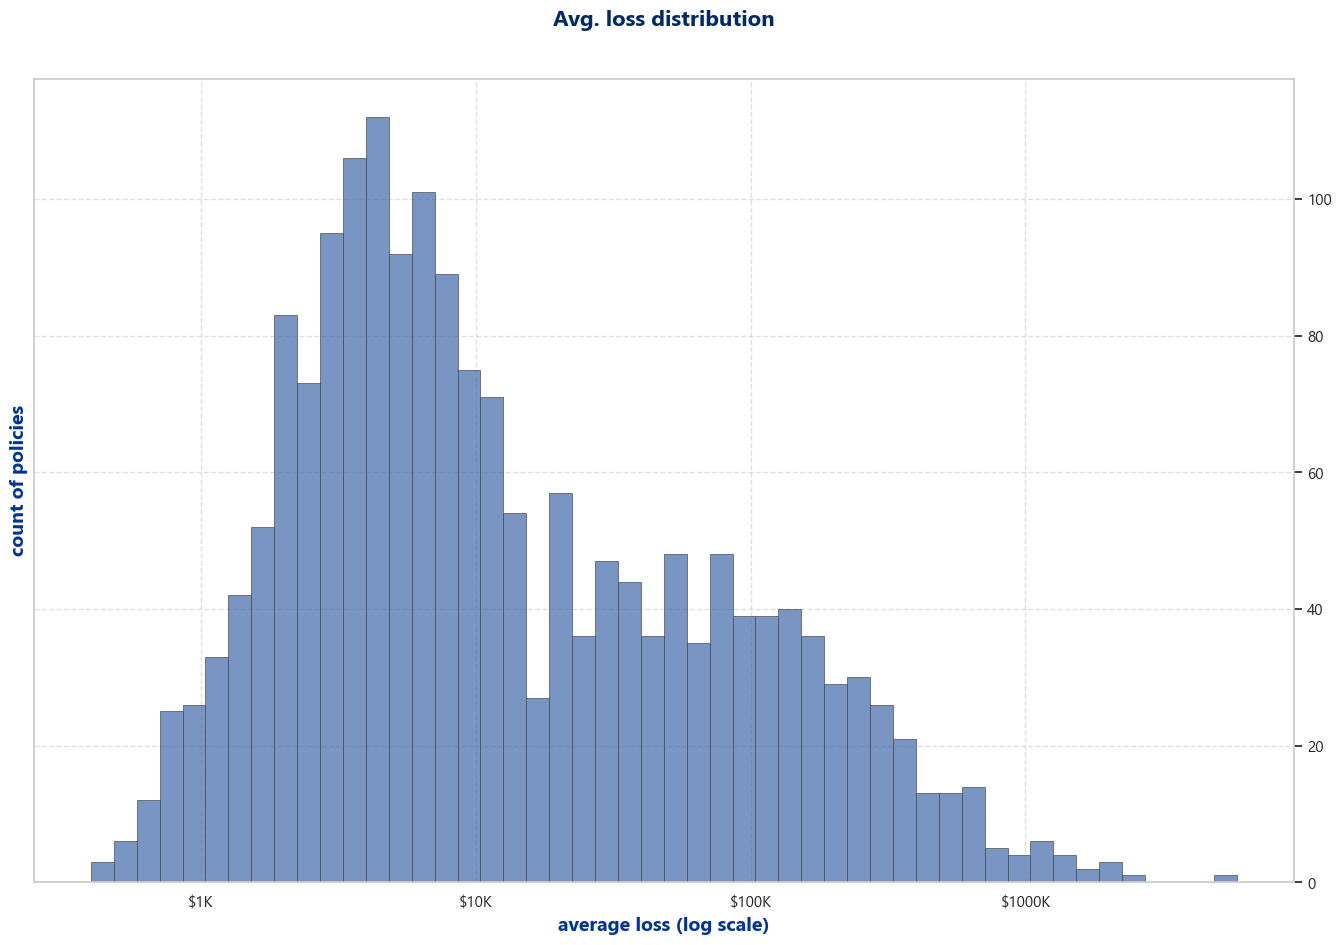

In [881]:
#now we want to check for outliers in the avg_loss target, first we will check the distribution of the avg loss against the no of policies, and then we will check for outliers using the IQR method
# we will do it in total and for both coverage types, since the loss seems very disperse we will use log scale,
# note: this won't show the zeros

fig, ax = plt.subplots(figsize=(14, 10))

sns.histplot(
    df_train_auto_policies,
    x="avg_loss",
    edgecolor=".3",
    linewidth=.5,
    log_scale=True,
    bins=50
)

ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_xticks([1000, 10000, 100000, 1000000])

#Format trick generated w/ Gemini
ax.get_xaxis().set_major_formatter(
    FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
)
ax.yaxis.tick_right()
ax.grid(True, linestyle="--", alpha = 0.6)
plt.xlabel('average loss (log scale)',fontsize=14,fontweight='bold', color='#003399')
plt.ylabel('count of policies',fontsize=14,fontweight='bold', color='#003399')
plt.title('Avg. loss distribution', y=1.04, fontsize=16, pad=15, fontweight='bold', color='#02296A')

plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
plt.show()

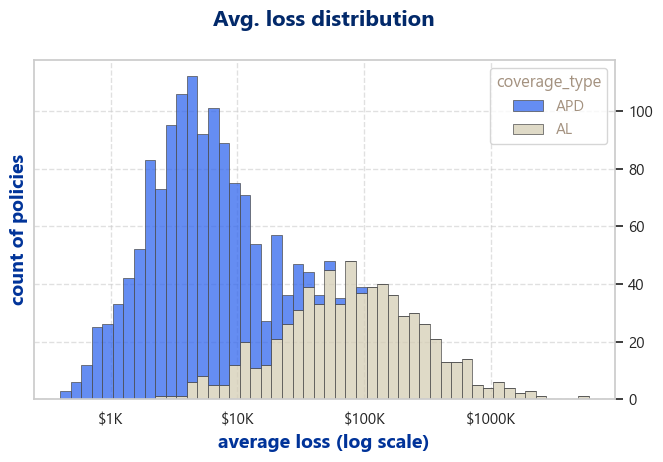

In [882]:

fig, ax = plt.subplots(figsize=(7, 5))

sns.histplot(
    df_train_auto_policies,
    x="avg_loss", hue="coverage_type",
    multiple="stack",
    palette=category_colors,
    edgecolor=".3",
    linewidth=.5,
    log_scale=True,
    bins=50
)

ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_xticks([1000, 10000, 100000, 1000000])

#Format trick generated w/ Gemini
ax.get_xaxis().set_major_formatter(
    FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
)
ax.yaxis.tick_right()
ax.grid(True, linestyle="--", alpha = 0.6)
plt.xlabel('average loss (log scale)',fontsize=14,fontweight='bold', color='#003399')
plt.ylabel('count of policies',fontsize=14,fontweight='bold', color='#003399')
plt.title('Avg. loss distribution', y=1.04, fontsize=16, pad=15, fontweight='bold', color='#02296A')

plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
plt.show()

In [883]:
#we will test for log normality on both coverage types, just for the sake of completeness
df_train_auto_policies['avg_loss_log'] = np.log(df_train_auto_policies['avg_loss'])

df_al_log = df_train_auto_policies[(df_train_auto_policies['coverage_type'] == 'AL') 
                                   & (df_train_auto_policies['avg_loss'] > 0)].copy()
df_apd_log = df_train_auto_policies[(df_train_auto_policies['coverage_type'] == 'APD') 
                                   & (df_train_auto_policies['avg_loss'] > 0)].copy()


log_normal_test_al = stats.normaltest(df_al_log['avg_loss_log'], axis=0)
print(log_normal_test_al)

log_normal_test_apd = stats.normaltest(df_apd_log['avg_loss_log'], axis=0)
print(log_normal_test_apd)

NormaltestResult(statistic=np.float64(0.031757420686428485), pvalue=np.float64(0.9842466917592982))
NormaltestResult(statistic=np.float64(3.736523311476414), pvalue=np.float64(0.15439181480183084))


c:\Users\saul1\anaconda3\envs\python_310\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [884]:
# given that the distribution of al seems to be log normal we could at use z scores for the outliers
# but we will keep with the IQR method for both coverage types, (just using log of the avg_loss) since it is more robust to outliers and we will be using it for both coverage types
# we will only do it for upper outliers, for this we will only need the rows with claims
df_claims = df_train_auto_policies[df_train_auto_policies['had_claim_binary'] == 1].copy()

df_claims['avg_loss_log'] = np.log(df_claims['avg_loss'])

percentile25 = df_claims['avg_loss_log'].quantile(0.25)
percentile75 = df_claims['avg_loss_log'].quantile(0.75)

iqr = percentile75 - percentile25

upper_limit = percentile75 + 1.5 * iqr

print("Upper limit", upper_limit)

print(percentile25, percentile75, iqr)

print("Number of outliers", df_claims[df_claims['avg_loss_log'] > upper_limit].shape[0])

Upper limit 14.68164958274484
8.12885011875298 10.749969904349724 2.6211197855967434
Number of outliers 2


In [885]:
#we will remove the outliers from both the whole and claims datasets
df_train_auto_policies = df_train_auto_policies[df_train_auto_policies['avg_loss_log'] <= upper_limit]
df_claims = df_claims[df_claims['avg_loss_log'] <= upper_limit]



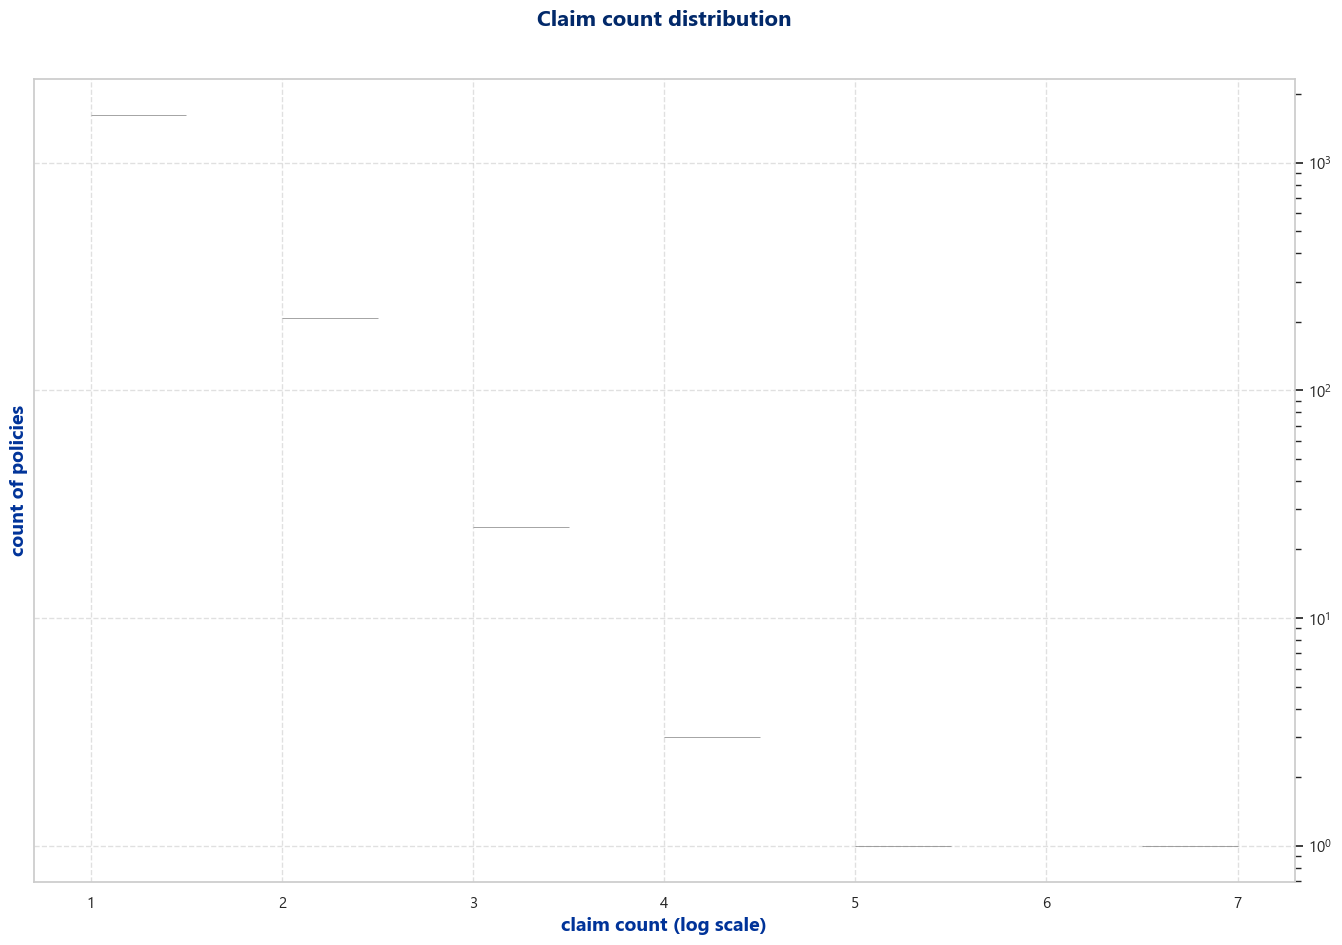

In [886]:
#now we want to quickly check the distribution of the claim_count target, only for the records with claims, since the rest are zeros, we will use log scale

fig, ax = plt.subplots(figsize=(14, 10))

sns.histplot(
    df_claims,
    x="claim_count",
    edgecolor=".5",
    linewidth=.5,
    log_scale=(False, True)
)

ax.yaxis.tick_right()
ax.grid(True, linestyle="--", alpha = 0.6)
plt.xlabel('claim count (log scale)',fontsize=14,fontweight='bold', color='#003399')
plt.ylabel('count of policies',fontsize=14,fontweight='bold', color='#003399')
plt.title('Claim count distribution', y=1.04, fontsize=16, pad=15, fontweight='bold', color='#02296A')

plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
plt.show()

#seaborn bugs out with my configs but from the outline it seems like its close to a poisson distribution, we will check for poisson distribution

In [887]:
#next we want to check the behaivor of our targets across time, we will use the end os the 
#policy as our time marker a will check it in aggregate

# crate the df for whole dataset claim ratio 
df_train_auto_policies['had_claim_binary_0'] = df_train_auto_policies['had_claim_binary'] == 0
df_train_auto_policies['had_claim_binary_1'] = df_train_auto_policies['had_claim_binary'] == 1

claims_ym = df_train_auto_policies.groupby(['policy_expiration_date_year_month_period']).agg(
    no_claim_count = ('had_claim_binary_0', 'sum'),
    had_claim_count = ('had_claim_binary_1', 'sum'),
    claim_count = ('claim_count', 'sum'),
    policies_count = ('policy_id', 'count'),
    avg_loss_1year = ('total_loss_amount', 'mean')
).reset_index()

claims_ym['had_claim_ratio'] = claims_ym['had_claim_count'] / claims_ym['no_claim_count']
claims_ym['claim_ratio'] = claims_ym['claim_count'] / claims_ym['no_claim_count']

claims_ym = claims_ym.drop(columns=['no_claim_count', 'had_claim_count'])

# crate the df for coverage claim ratio 

claims_ym_byCoverage = df_train_auto_policies.groupby(['policy_expiration_date_year_month_period','coverage_type']).agg(
    no_claim_count = ('had_claim_binary_0', 'sum'),
    had_claim_count = ('had_claim_binary_1', 'sum'),
    claim_count = ('claim_count', 'sum'),
    policies_count = ('policy_id', 'count'),
    avg_loss_1year = ('total_loss_amount', 'mean')
).reset_index()

claims_ym_byCoverage['had_claim_ratio'] = claims_ym_byCoverage['had_claim_count'] / claims_ym_byCoverage['no_claim_count']
claims_ym_byCoverage['claim_ratio'] = claims_ym_byCoverage['claim_count'] / claims_ym_byCoverage['no_claim_count']

claims_ym_byCoverage = claims_ym_byCoverage.drop(columns=['no_claim_count', 'had_claim_count'])


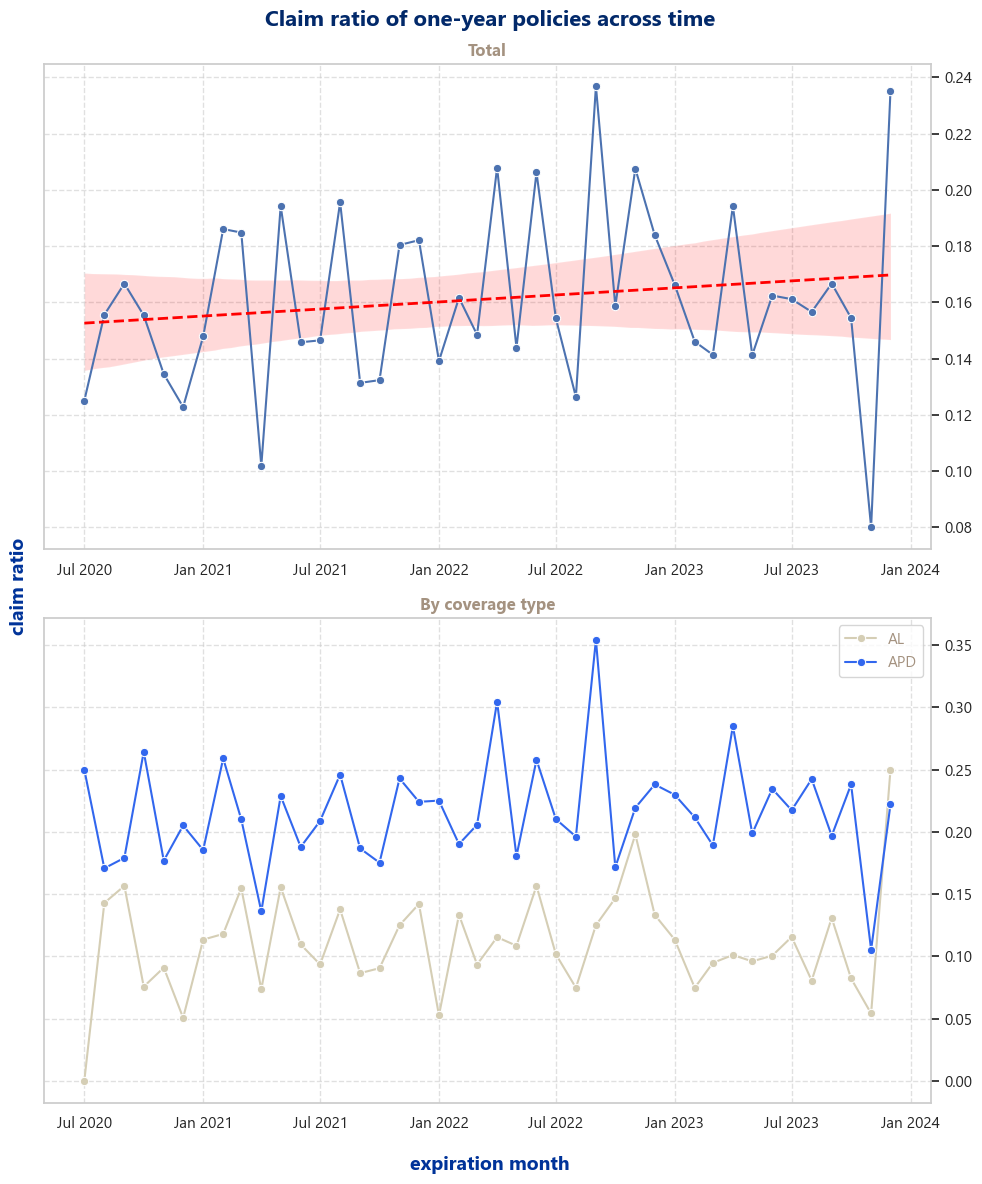

In [888]:
#first for the claim ratio
claims_ym['policy_expiration_date_year_month_period'] = claims_ym['policy_expiration_date_year_month_period'].dt.to_timestamp()

min_date_complete = claims_ym["policy_expiration_date_year_month_period"].min()
max_date_complete = claims_ym["policy_expiration_date_year_month_period"].max()

fig, ax = plt.subplots(2, 1, figsize=(10, 12))

sns.lineplot(data = claims_ym, x="policy_expiration_date_year_month_period", 
             y="claim_ratio", ax=ax[0], marker="o")
sns.regplot(
    x=mdates.date2num(claims_ym["policy_expiration_date_year_month_period"]),
    y=claims_ym["claim_ratio"],
    ax=ax[0],
    scatter=False,
    color="red",
    label="Trendline",
    line_kws={"linestyle": "--", "linewidth": 2}
)
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[0].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax[0].tick_params(axis='x', rotation=0) 
#ax[0].set_xlim(min_date_complete, max_date_complete)
ax[0].set_xlabel('')
ax[0].set_ylabel('')
ax[0].set_title("Total",fontsize=12, fontweight='bold', color = '#A49280')
ax[0].grid(True, linestyle="--", alpha = 0.6)
ax[0].yaxis.tick_right()



claims_ym_byCoverage['policy_expiration_date_year_month_period'] = claims_ym_byCoverage['policy_expiration_date_year_month_period'].dt.to_timestamp()

sns.lineplot(data = claims_ym_byCoverage, x="policy_expiration_date_year_month_period", 
             y="claim_ratio", hue="coverage_type",palette= category_colors, ax=ax[1], marker="o")

ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax[1].tick_params(axis='x', rotation=0) 
#ax[1].set_xlim(min_date_complete, max_date_complete)
ax[1].set_xlabel('')
ax[1].set_ylabel('')
ax[1].set_title("By coverage type",fontsize=12, fontweight='bold', color = '#A49280')
ax[1].grid(True, linestyle="--", alpha = 0.6)
ax[1].yaxis.tick_right()

fig.suptitle("Claim ratio of one-year policies across time", fontsize=16, fontweight='bold', color = '#02296A')
fig.supxlabel("expiration month", fontsize=14 ,fontweight='bold', color = '#003399')
fig.supylabel("claim ratio", fontsize=14, fontweight='bold', color = '#003399')


plt.legend()
plt.tight_layout()

plt.show()



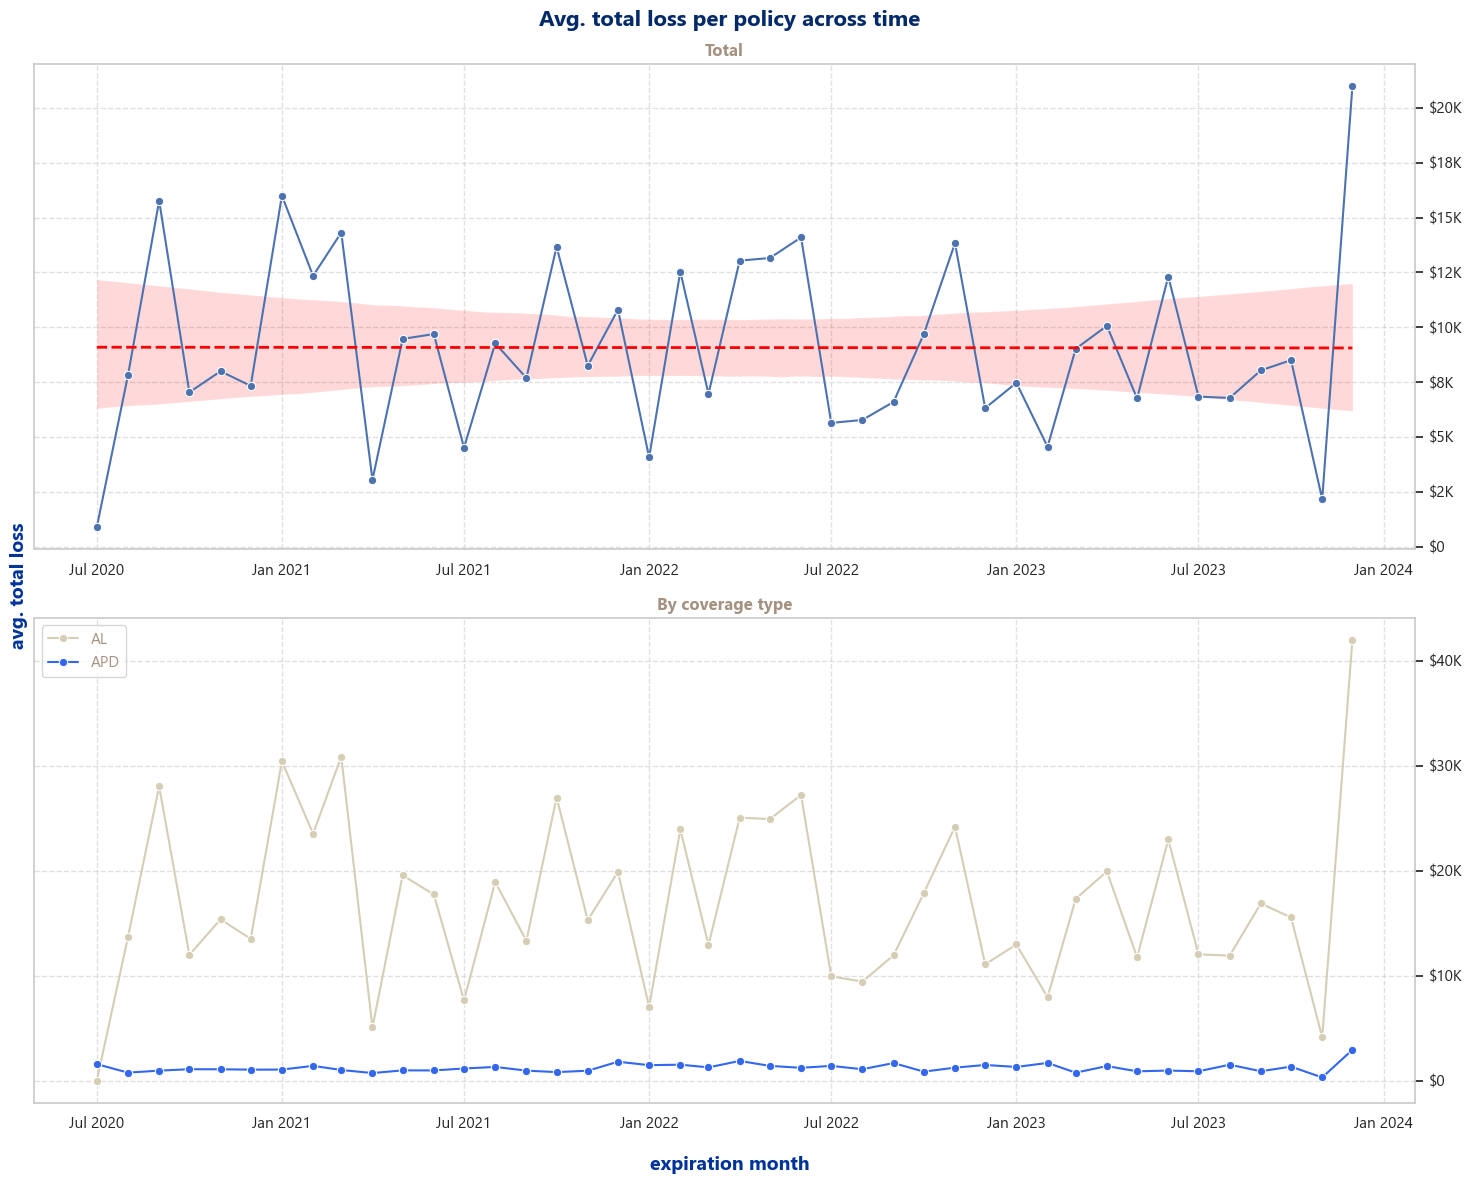

In [889]:
#now for the policy total loss

fig, ax = plt.subplots(2, 1, figsize=(15, 12))

sns.lineplot(data = claims_ym, x="policy_expiration_date_year_month_period", 
             y="avg_loss_1year", ax=ax[0], marker="o")
sns.regplot(
    x=mdates.date2num(claims_ym["policy_expiration_date_year_month_period"]),
    y=claims_ym["avg_loss_1year"],
    ax=ax[0],
    scatter=False,
    color="red",
    label="Trendline",
    line_kws={"linestyle": "--", "linewidth": 2}
)
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[0].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax[0].tick_params(axis='x', rotation=0) 
#ax[0].set_xlim(min_date_complete, max_date_complete)
ax[0].set_xlabel('')
ax[0].set_ylabel('')
ax[0].set_title("Total",fontsize=12, fontweight='bold', color = '#A49280')
ax[0].grid(True, linestyle="--", alpha = 0.6)
ax[0].yaxis.tick_right()

#Format trick generated w/ Gemini
ax[0].get_yaxis().set_major_formatter(
    FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
)


sns.lineplot(data = claims_ym_byCoverage, x="policy_expiration_date_year_month_period", 
             y="avg_loss_1year", hue="coverage_type",palette= category_colors, ax=ax[1], 
             marker="o")

ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax[1].tick_params(axis='x', rotation=0) 
#ax[1].set_xlim(min_date_complete, max_date_complete)
ax[1].set_xlabel('')
ax[1].set_ylabel('')
ax[1].set_title("By coverage type",fontsize=12, fontweight='bold', color = '#A49280')
ax[1].grid(True, linestyle="--", alpha = 0.6)
ax[1].yaxis.tick_right()
#Format trick generated w/ Gemini
ax[1].get_yaxis().set_major_formatter(
    FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
)

fig.suptitle("Avg. total loss per policy across time", fontsize=16, fontweight='bold', color = '#02296A')
fig.supxlabel("expiration month", fontsize=14 ,fontweight='bold', color = '#003399')
fig.supylabel("avg. total loss", fontsize=14, fontweight='bold', color = '#003399')


plt.legend()
plt.tight_layout()

plt.show()

#by coverage type presented in log scale due class inbalance


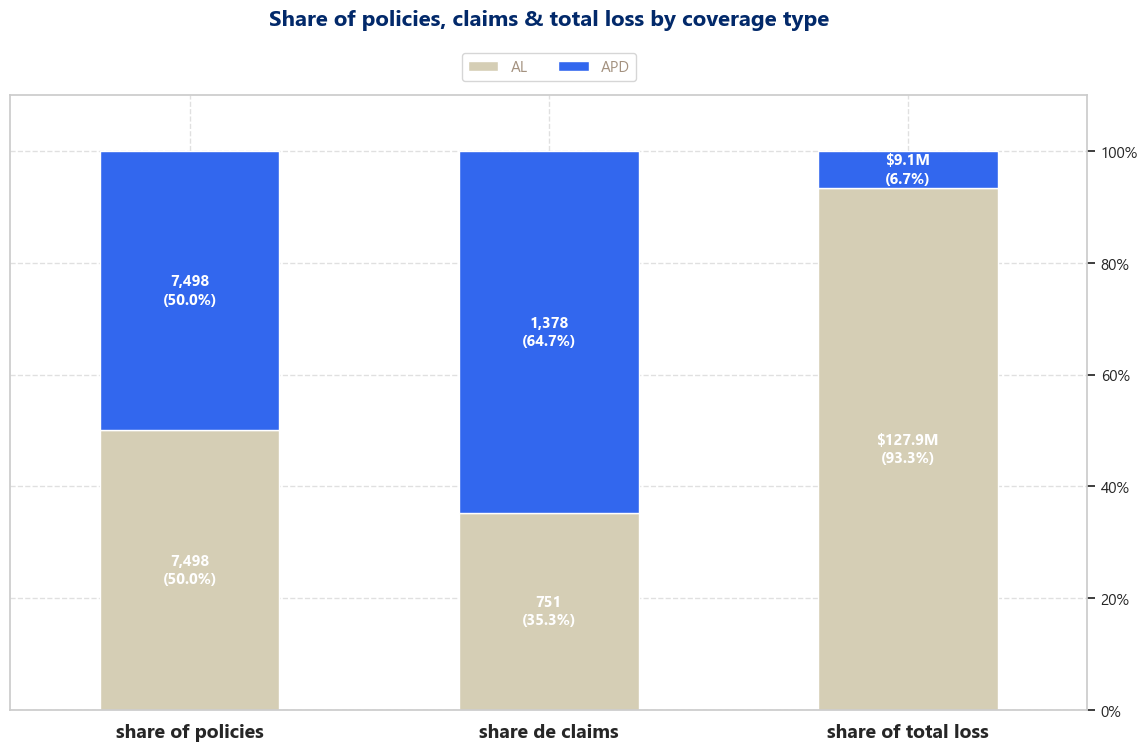

In [890]:


#generated with Gemini, modified by me to match the desing of the other plots

rows_pct = df_train_auto_policies['coverage_type'].value_counts(normalize=True) * 100
amount_sum = df_train_auto_policies.groupby('coverage_type')['total_loss_amount'].sum()
amount_pct = (amount_sum / amount_sum.sum()) * 100
claims_sum = df_train_auto_policies.groupby('coverage_type')['claim_count'].sum()
claims_pct = (claims_sum / claims_sum.sum()) * 100

summary_df = pd.DataFrame({
    'share of policies': rows_pct,
    'share de claims': claims_pct,
    'share of total loss': amount_pct
}).T 

rows_net = df_train_auto_policies['coverage_type'].value_counts()
summary_net = pd.DataFrame({
    'share of policies': rows_net,
    'share de claims': claims_sum,
    'share of total loss': amount_sum
}).T

ax = summary_df.plot(
    kind='bar', 
    stacked=True, 
    figsize=(12, 8), 
    color=category_colors,
    width=0.5
)
ax.yaxis.tick_right()

def format_net_value(value, metric_name):
    if 'loss' in metric_name:  
        if value >= 1e6: return f"${value/1e6:.1f}M"
        if value >= 1e3: return f"${value/1e3:.0f}K"
        return f"${value:.0f}"
    return f"{int(value):,}" 

categories = summary_df.columns

for i, container in enumerate(ax.containers):
    category_name = categories[i]
    labels = []
    
    for row_idx, rect in enumerate(container):
        pct_value = rect.get_height()
        if pct_value > 3:  
            metric_name = summary_df.index[row_idx]
            net_value = summary_net.loc[metric_name, category_name]
            
            formatted_net = format_net_value(net_value, metric_name)
            labels.append(f'{formatted_net}\n({pct_value:.1f}%)')
        else:
            labels.append('')
            
    ax.bar_label(container, labels=labels, label_type='center', fontsize=11, weight='bold', color='white')

ax.grid(True, linestyle="--", alpha=0.6)

plt.xlabel('')
plt.ylabel('')
plt.xticks(
    rotation=0, 
    fontsize=14,
    fontweight='bold',
)
plt.ylim(0, 110)

ax.yaxis.set_major_formatter('{x:1.0f}%')

plt.legend(bbox_to_anchor=(0.5, 1.01), loc="lower center", ncols=2)
plt.title('Share of policies, claims & total loss by coverage type', y=1.08, fontsize=16, pad=15, fontweight='bold', color='#02296A')

plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
plt.show()

<Figure size 2000x4000 with 0 Axes>

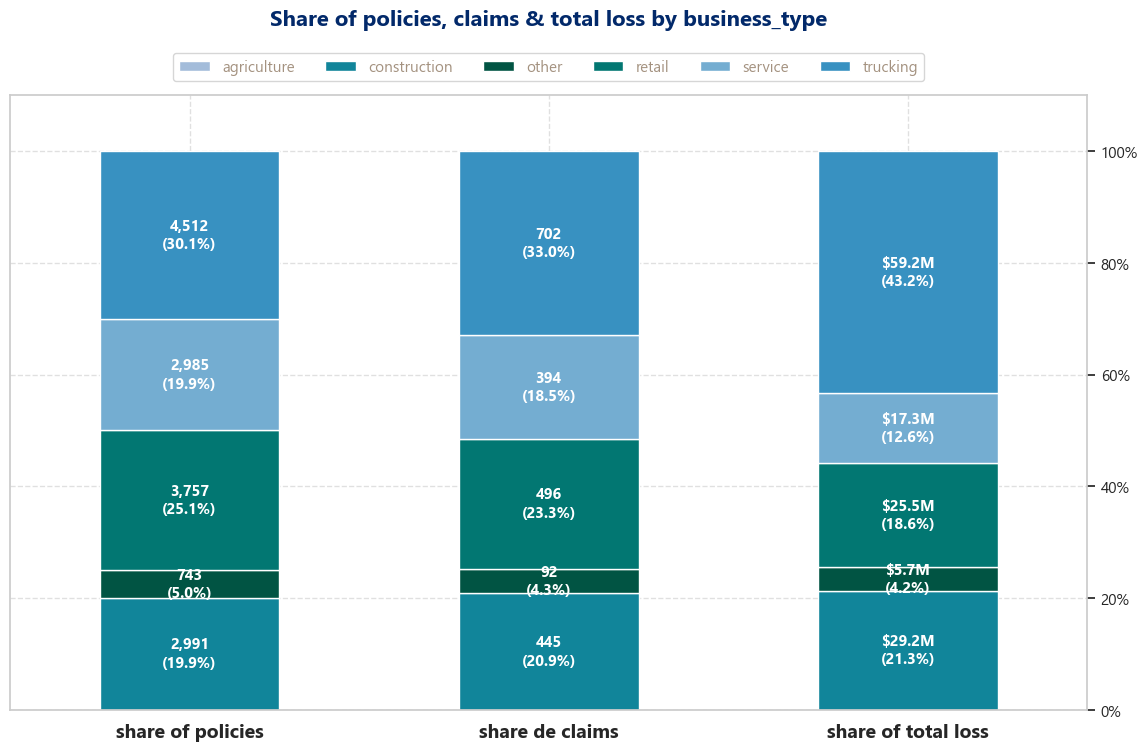

<Figure size 2000x4000 with 0 Axes>

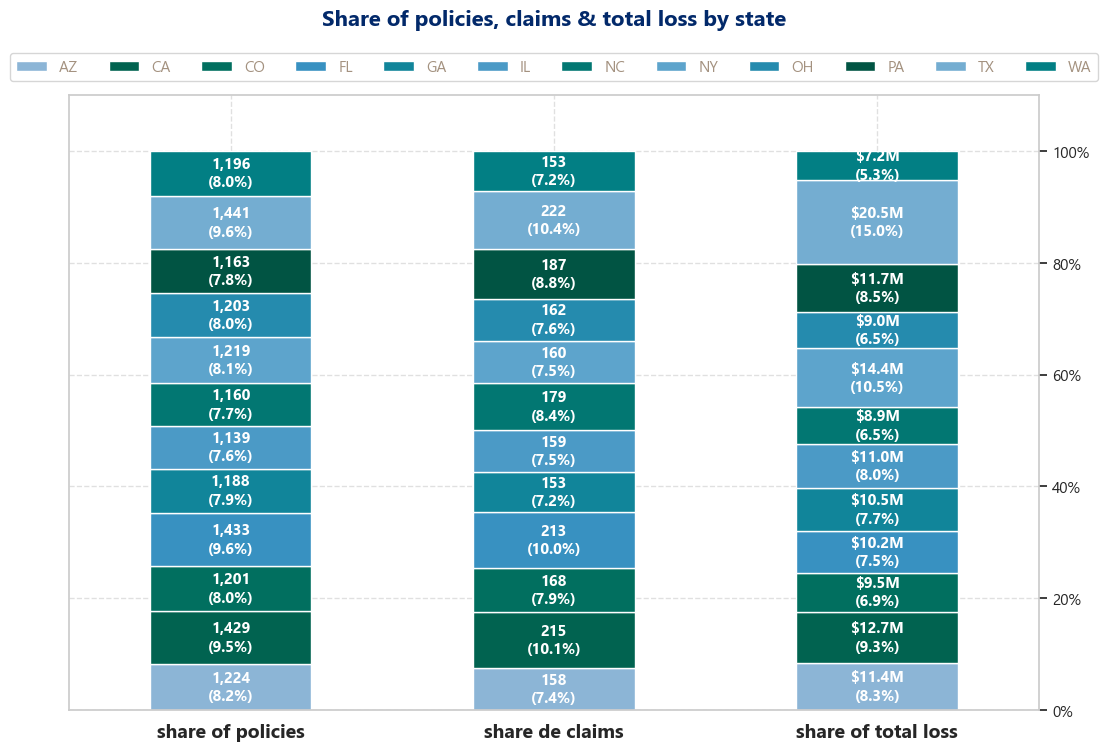

In [891]:
features = ['business_type', 'state']
#generated with Gemini, modified by me to match the desing of the other plots
for feature in features:
    plt.figure(figsize=(20, 40))
    rows_pct = df_train_auto_policies[feature].value_counts(normalize=True) * 100
    amount_sum = df_train_auto_policies.groupby(feature)['total_loss_amount'].sum()
    amount_pct = (amount_sum / amount_sum.sum()) * 100
    claims_sum = df_train_auto_policies.groupby(feature)['claim_count'].sum()
    claims_pct = (claims_sum / claims_sum.sum()) * 100

    summary_df = pd.DataFrame({
        'share of policies': rows_pct,
        'share de claims': claims_pct,
        'share of total loss': amount_pct
    }).T 

    rows_net = df_train_auto_policies[feature].value_counts()
    summary_net = pd.DataFrame({
        'share of policies': rows_net,
        'share de claims': claims_sum,
        'share of total loss': amount_sum
    }).T

    ax = summary_df.plot(
        kind='bar', 
        stacked=True, 
        figsize=(12, 8), 
        color=category_colors,
        width=0.5
    )
    ax.yaxis.tick_right()

    def format_net_value(value, metric_name):
        if 'loss' in metric_name:  
            if value >= 1e6: return f"${value/1e6:.1f}M"
            if value >= 1e3: return f"${value/1e3:.0f}K"
            return f"${value:.0f}"
        return f"{int(value):,}" 

    categories = summary_df.columns

    for i, container in enumerate(ax.containers):
        category_name = categories[i]
        labels = []
        
        for row_idx, rect in enumerate(container):
            pct_value = rect.get_height()
            if pct_value > 3:  
                metric_name = summary_df.index[row_idx]
                net_value = summary_net.loc[metric_name, category_name]
                
                formatted_net = format_net_value(net_value, metric_name)
                labels.append(f'{formatted_net}\n({pct_value:.1f}%)')
            else:
                labels.append('')
                
        ax.bar_label(container, labels=labels, label_type='center', fontsize=11, weight='bold', color='white')

    ax.grid(True, linestyle="--", alpha=0.6)

    plt.xlabel('')
    plt.ylabel('')
    plt.xticks(
        rotation=0, 
        fontsize=14,
        fontweight='bold',
    )
    plt.ylim(0, 110)

    ax.yaxis.set_major_formatter('{x:1.0f}%')

    plt.legend(bbox_to_anchor=(0.5, 1.01), loc="lower center", ncols=df_train_auto_policies[feature].nunique())
    plt.title(f"Share of policies, claims & total loss by {feature}", y=1.08, fontsize=16, pad=15, fontweight='bold', color='#02296A')

    plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
    plt.show()

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  amount_sum = df_train_auto_policies.groupby(feature)['total_loss_amount'].sum()
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  claims_sum = df_train_auto_policies.groupby(feature)['claim_count'].sum()


<Figure size 2000x4000 with 0 Axes>

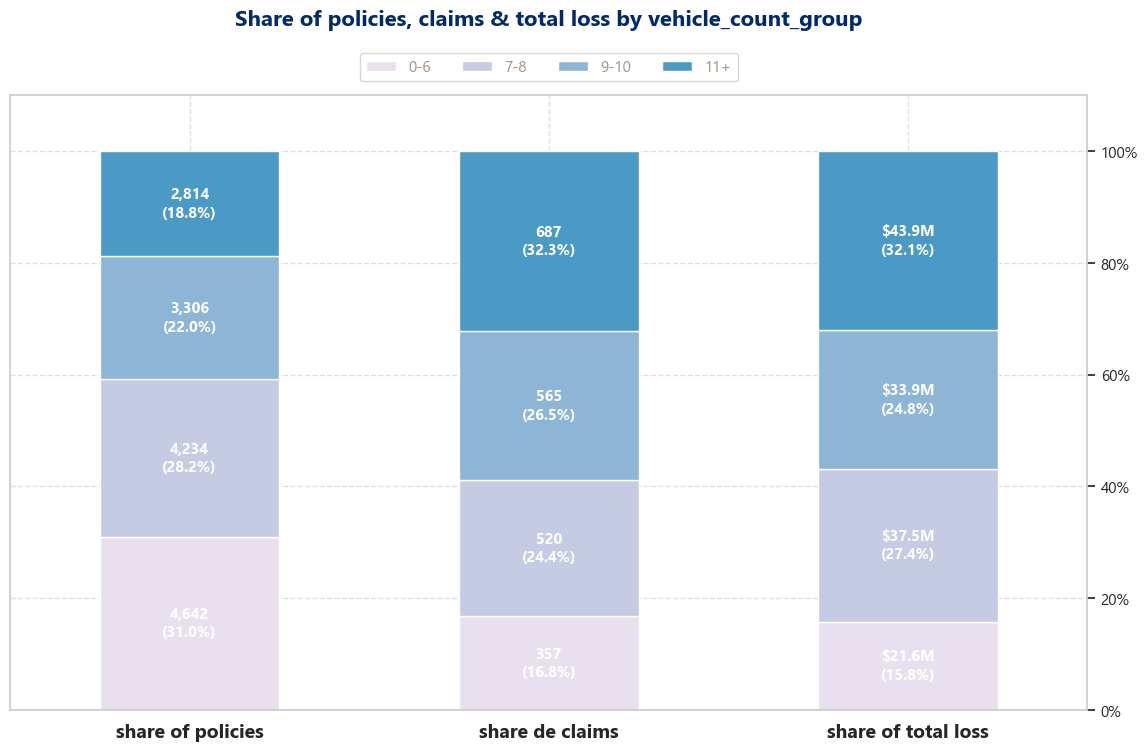

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  amount_sum = df_train_auto_policies.groupby(feature)['total_loss_amount'].sum()
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  claims_sum = df_train_auto_policies.groupby(feature)['claim_count'].sum()


<Figure size 2000x4000 with 0 Axes>

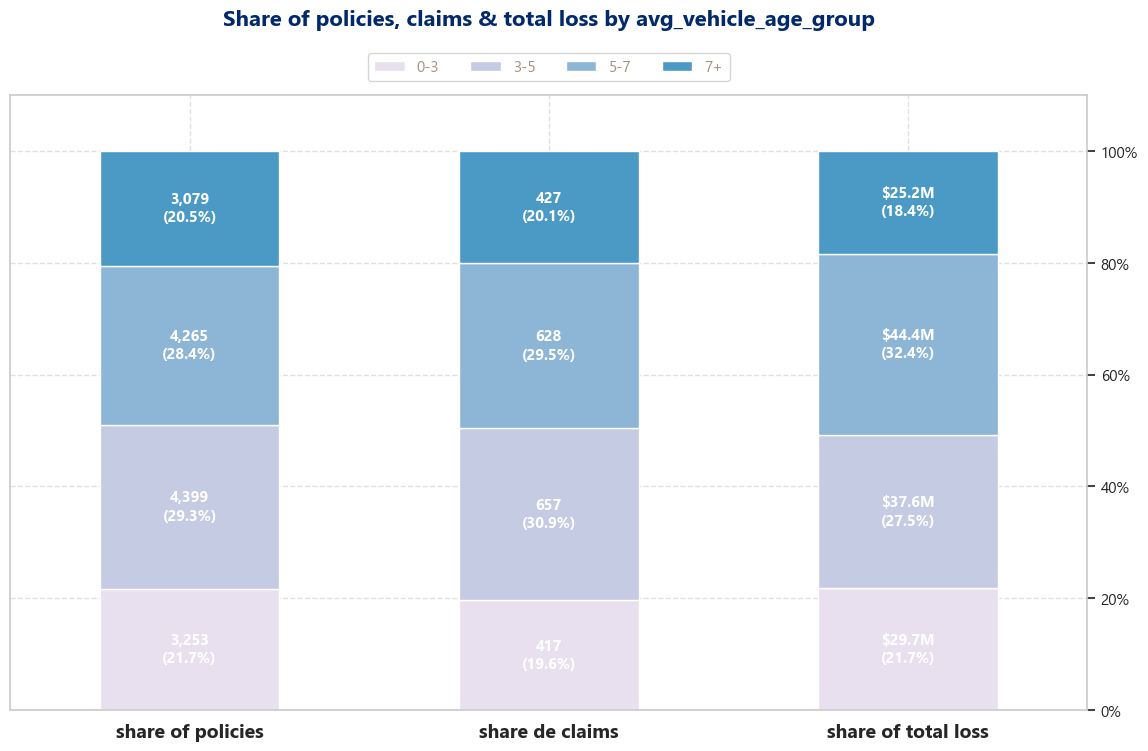

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  amount_sum = df_train_auto_policies.groupby(feature)['total_loss_amount'].sum()
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  claims_sum = df_train_auto_policies.groupby(feature)['claim_count'].sum()


<Figure size 2000x4000 with 0 Axes>

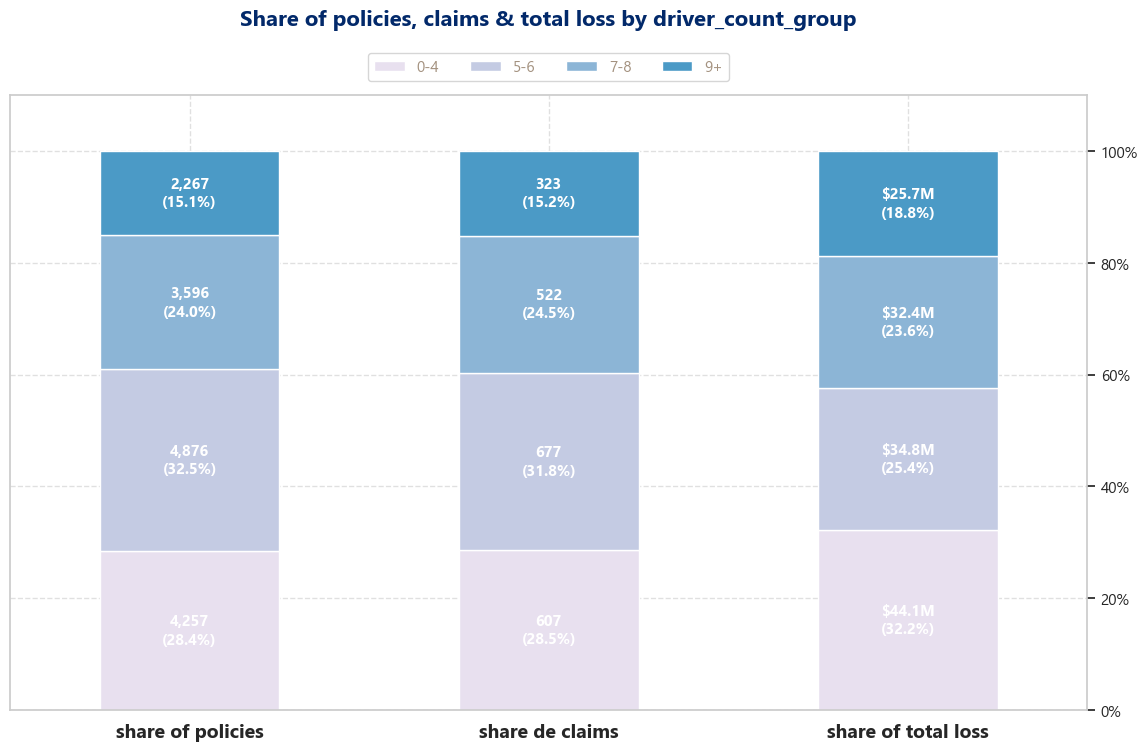

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  amount_sum = df_train_auto_policies.groupby(feature)['total_loss_amount'].sum()
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  claims_sum = df_train_auto_policies.groupby(feature)['claim_count'].sum()


<Figure size 2000x4000 with 0 Axes>

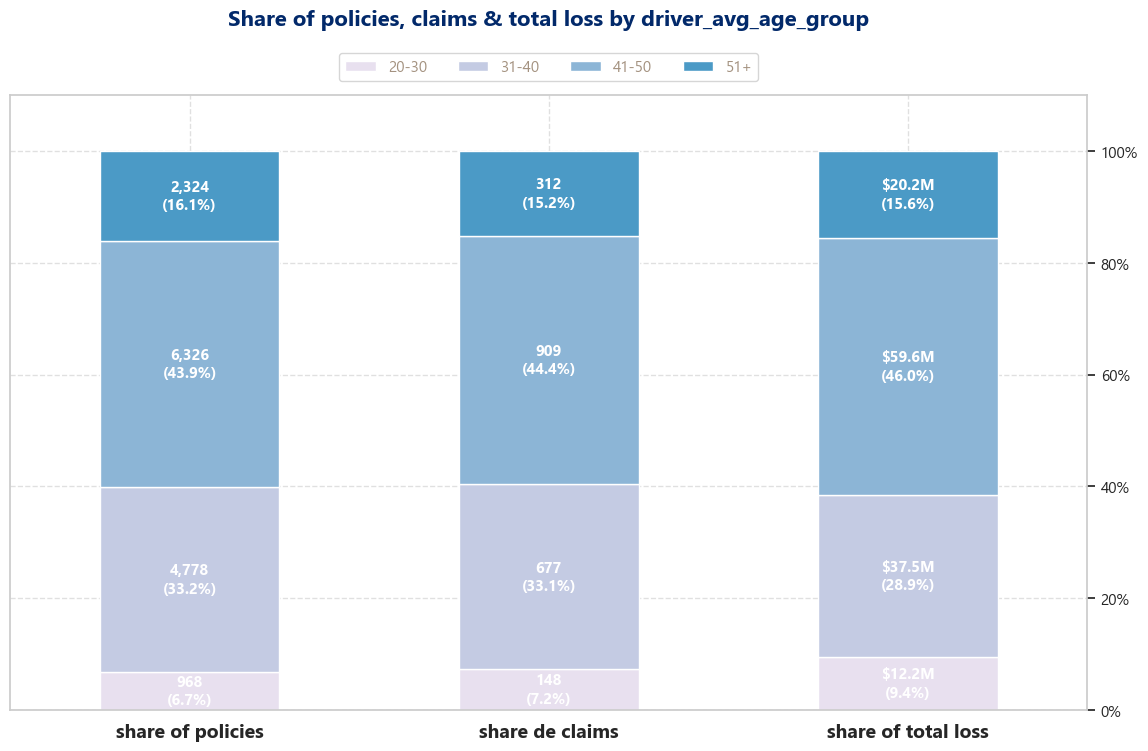

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  amount_sum = df_train_auto_policies.groupby(feature)['total_loss_amount'].sum()
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  claims_sum = df_train_auto_policies.groupby(feature)['claim_count'].sum()


<Figure size 2000x4000 with 0 Axes>

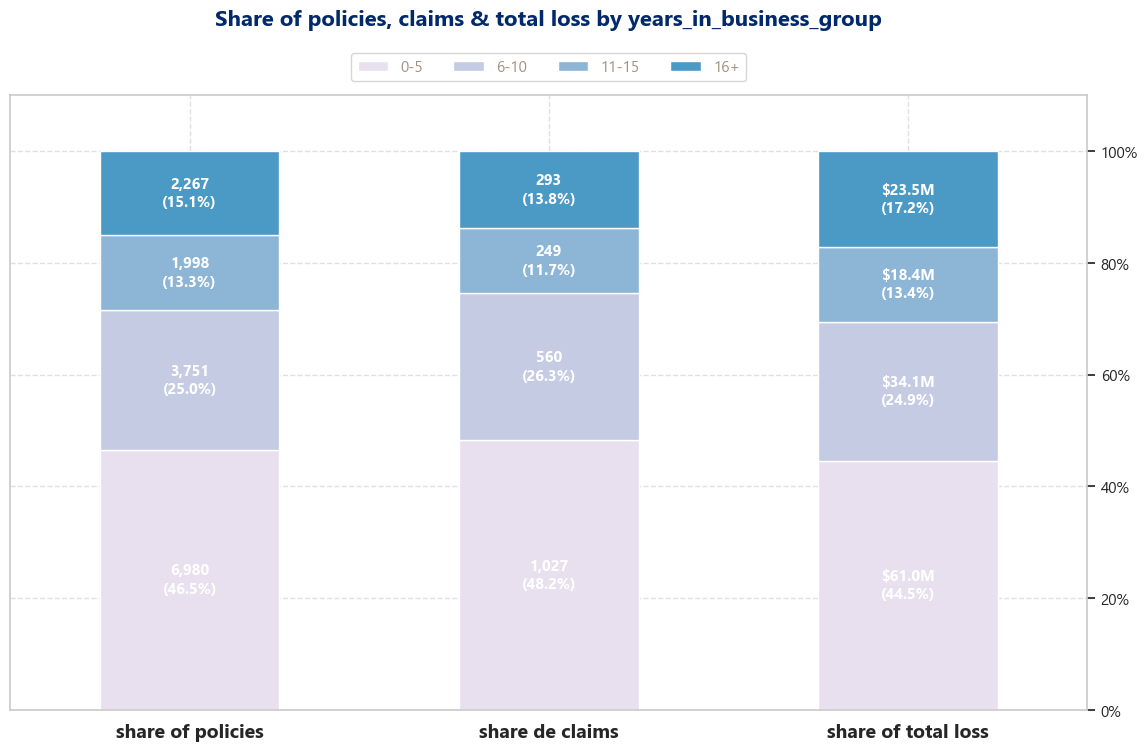

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  amount_sum = df_train_auto_policies.groupby(feature)['total_loss_amount'].sum()
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3632670470.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  claims_sum = df_train_auto_policies.groupby(feature)['claim_count'].sum()


<Figure size 2000x4000 with 0 Axes>

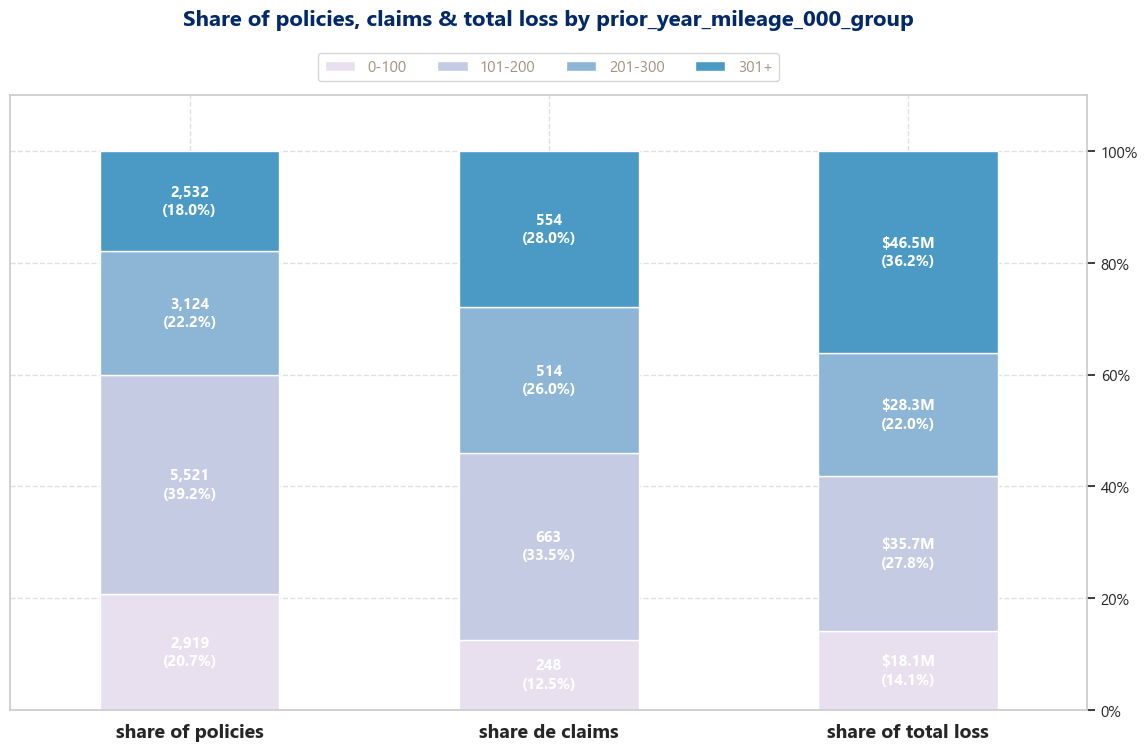

In [892]:
features = [ 'vehicle_count_group', 'avg_vehicle_age_group', 'driver_count_group', 'driver_avg_age_group', 'years_in_business_group', 'prior_year_mileage_000_group']
#generated with Gemini, modified by me to match the desing of the other plots
for feature in features:
    plt.figure(figsize=(20, 40))
    rows_pct = df_train_auto_policies[feature].value_counts(normalize=True) * 100
    amount_sum = df_train_auto_policies.groupby(feature)['total_loss_amount'].sum()
    amount_pct = (amount_sum / amount_sum.sum()) * 100
    claims_sum = df_train_auto_policies.groupby(feature)['claim_count'].sum()
    claims_pct = (claims_sum / claims_sum.sum()) * 100

    summary_df = pd.DataFrame({
        'share of policies': rows_pct,
        'share de claims': claims_pct,
        'share of total loss': amount_pct
    }).T 

    rows_net = df_train_auto_policies[feature].value_counts()
    summary_net = pd.DataFrame({
        'share of policies': rows_net,
        'share de claims': claims_sum,
        'share of total loss': amount_sum
    }).T

    ax = summary_df.plot(
        kind='bar', 
        stacked=True, 
        figsize=(12, 8), 
        color=sns.color_palette("PuBuGn"),
        width=0.5
    )
    ax.yaxis.tick_right()

    def format_net_value(value, metric_name):
        if 'loss' in metric_name:  
            if value >= 1e6: return f"${value/1e6:.1f}M"
            if value >= 1e3: return f"${value/1e3:.0f}K"
            return f"${value:.0f}"
        return f"{int(value):,}" 

    categories = summary_df.columns

    for i, container in enumerate(ax.containers):
        category_name = categories[i]
        labels = []
        
        for row_idx, rect in enumerate(container):
            pct_value = rect.get_height()
            if pct_value > 3:  
                metric_name = summary_df.index[row_idx]
                net_value = summary_net.loc[metric_name, category_name]
                
                formatted_net = format_net_value(net_value, metric_name)
                labels.append(f'{formatted_net}\n({pct_value:.1f}%)')
            else:
                labels.append('')
                
        ax.bar_label(container, labels=labels, label_type='center', fontsize=11, weight='bold', color='white')

    ax.grid(True, linestyle="--", alpha=0.6)

    plt.xlabel('')
    plt.ylabel('')
    plt.xticks(
        rotation=0, 
        fontsize=14,
        fontweight='bold',
    )
    plt.ylim(0, 110)

    ax.yaxis.set_major_formatter('{x:1.0f}%')

    plt.legend(bbox_to_anchor=(0.5, 1.01), loc="lower center", ncols=df_train_auto_policies[feature].nunique())
    plt.title(f"Share of policies, claims & total loss by {feature}", y=1.08, fontsize=16, pad=15, fontweight='bold', color='#02296A')

    plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
    plt.show()

In [893]:
def weighted_average(dataframe, value, weight):
    val = dataframe[value]
    #print(val.sum())
    wt = dataframe[weight]
    #print(wt.sum())
    return (val * wt).sum() / wt.sum()


In [894]:
df_grouped = df_train_auto_policies[['coverage_type', 'claim_count', 'policy_id']].groupby(['coverage_type', 'claim_count']).count().reset_index()[['coverage_type', 'claim_count', 'policy_id']]
print(df_grouped)
df_weighted = df_grouped.groupby('coverage_type').apply(weighted_average, 
                                     'claim_count', 'policy_id').reset_index().rename(columns={0: 'weighted_avg_claim_count'})
print(df_weighted)



   coverage_type  claim_count  policy_id
0             AL            0       6818
1             AL            1        616
2             AL            2         58
3             AL            3          5
4             AL            4          1
5            APD            0       6326
6            APD            1        998
7            APD            2        150
8            APD            3         20
9            APD            4          2
10           APD            5          1
11           APD            7          1
  coverage_type  weighted_avg_claim_count
0            AL              0.1001600427
1           APD              0.1837823420


C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3474942352.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_weighted = df_grouped.groupby('coverage_type').apply(weighted_average,


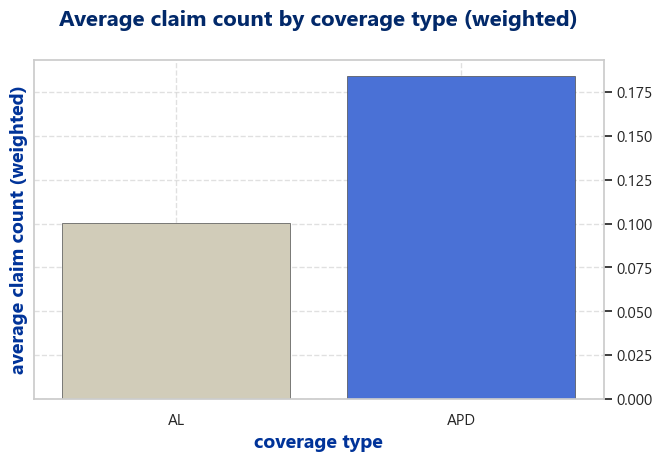

In [895]:

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    df_weighted,
    x="coverage_type", y="weighted_avg_claim_count", hue="coverage_type",
    palette=category_colors,
    edgecolor=".3",
    linewidth=.5,
)

ax.yaxis.tick_right()
ax.grid(True, linestyle="--", alpha = 0.6)
plt.xlabel('coverage type',fontsize=14,fontweight='bold', color='#003399')
plt.ylabel('average claim count (weighted)',fontsize=14,fontweight='bold', color='#003399')
plt.title('Average claim count by coverage type (weighted)', y=1.04, fontsize=16, pad=15, fontweight='bold', color='#02296A')

plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
plt.show()

In [896]:
df_weighted_loss = df_claims.groupby('coverage_type').apply(weighted_average, 
                                     'avg_loss', 'claim_count').reset_index().rename(columns={0: 'weighted_avg_loss'})
print(df_weighted_loss)

  coverage_type  weighted_avg_loss
0            AL  170246.8281624501
1           APD    6619.2609651669


C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\3694552496.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_weighted_loss = df_claims.groupby('coverage_type').apply(weighted_average,


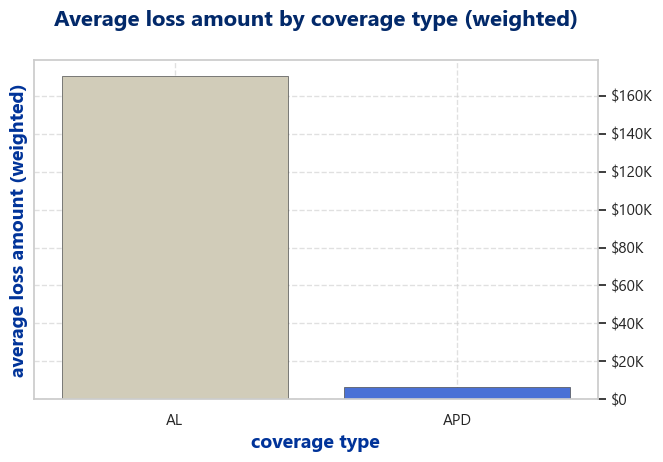

In [897]:

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    df_weighted_loss,
    x="coverage_type", y="weighted_avg_loss", hue="coverage_type",
    palette=category_colors,
    edgecolor=".3",
    linewidth=.5,
)
ax.get_yaxis().set_major_formatter(
    FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
)
ax.yaxis.tick_right()
ax.grid(True, linestyle="--", alpha = 0.6)
plt.xlabel('coverage type',fontsize=14,fontweight='bold', color='#003399')
plt.ylabel('average loss amount (weighted)',fontsize=14,fontweight='bold', color='#003399')
plt.title('Average loss amount by coverage type (weighted)', y=1.04, fontsize=16, pad=15, fontweight='bold', color='#02296A')

plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
plt.show()

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\214803229.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\214803229.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_weighted_loss = df_claims.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\214803229.

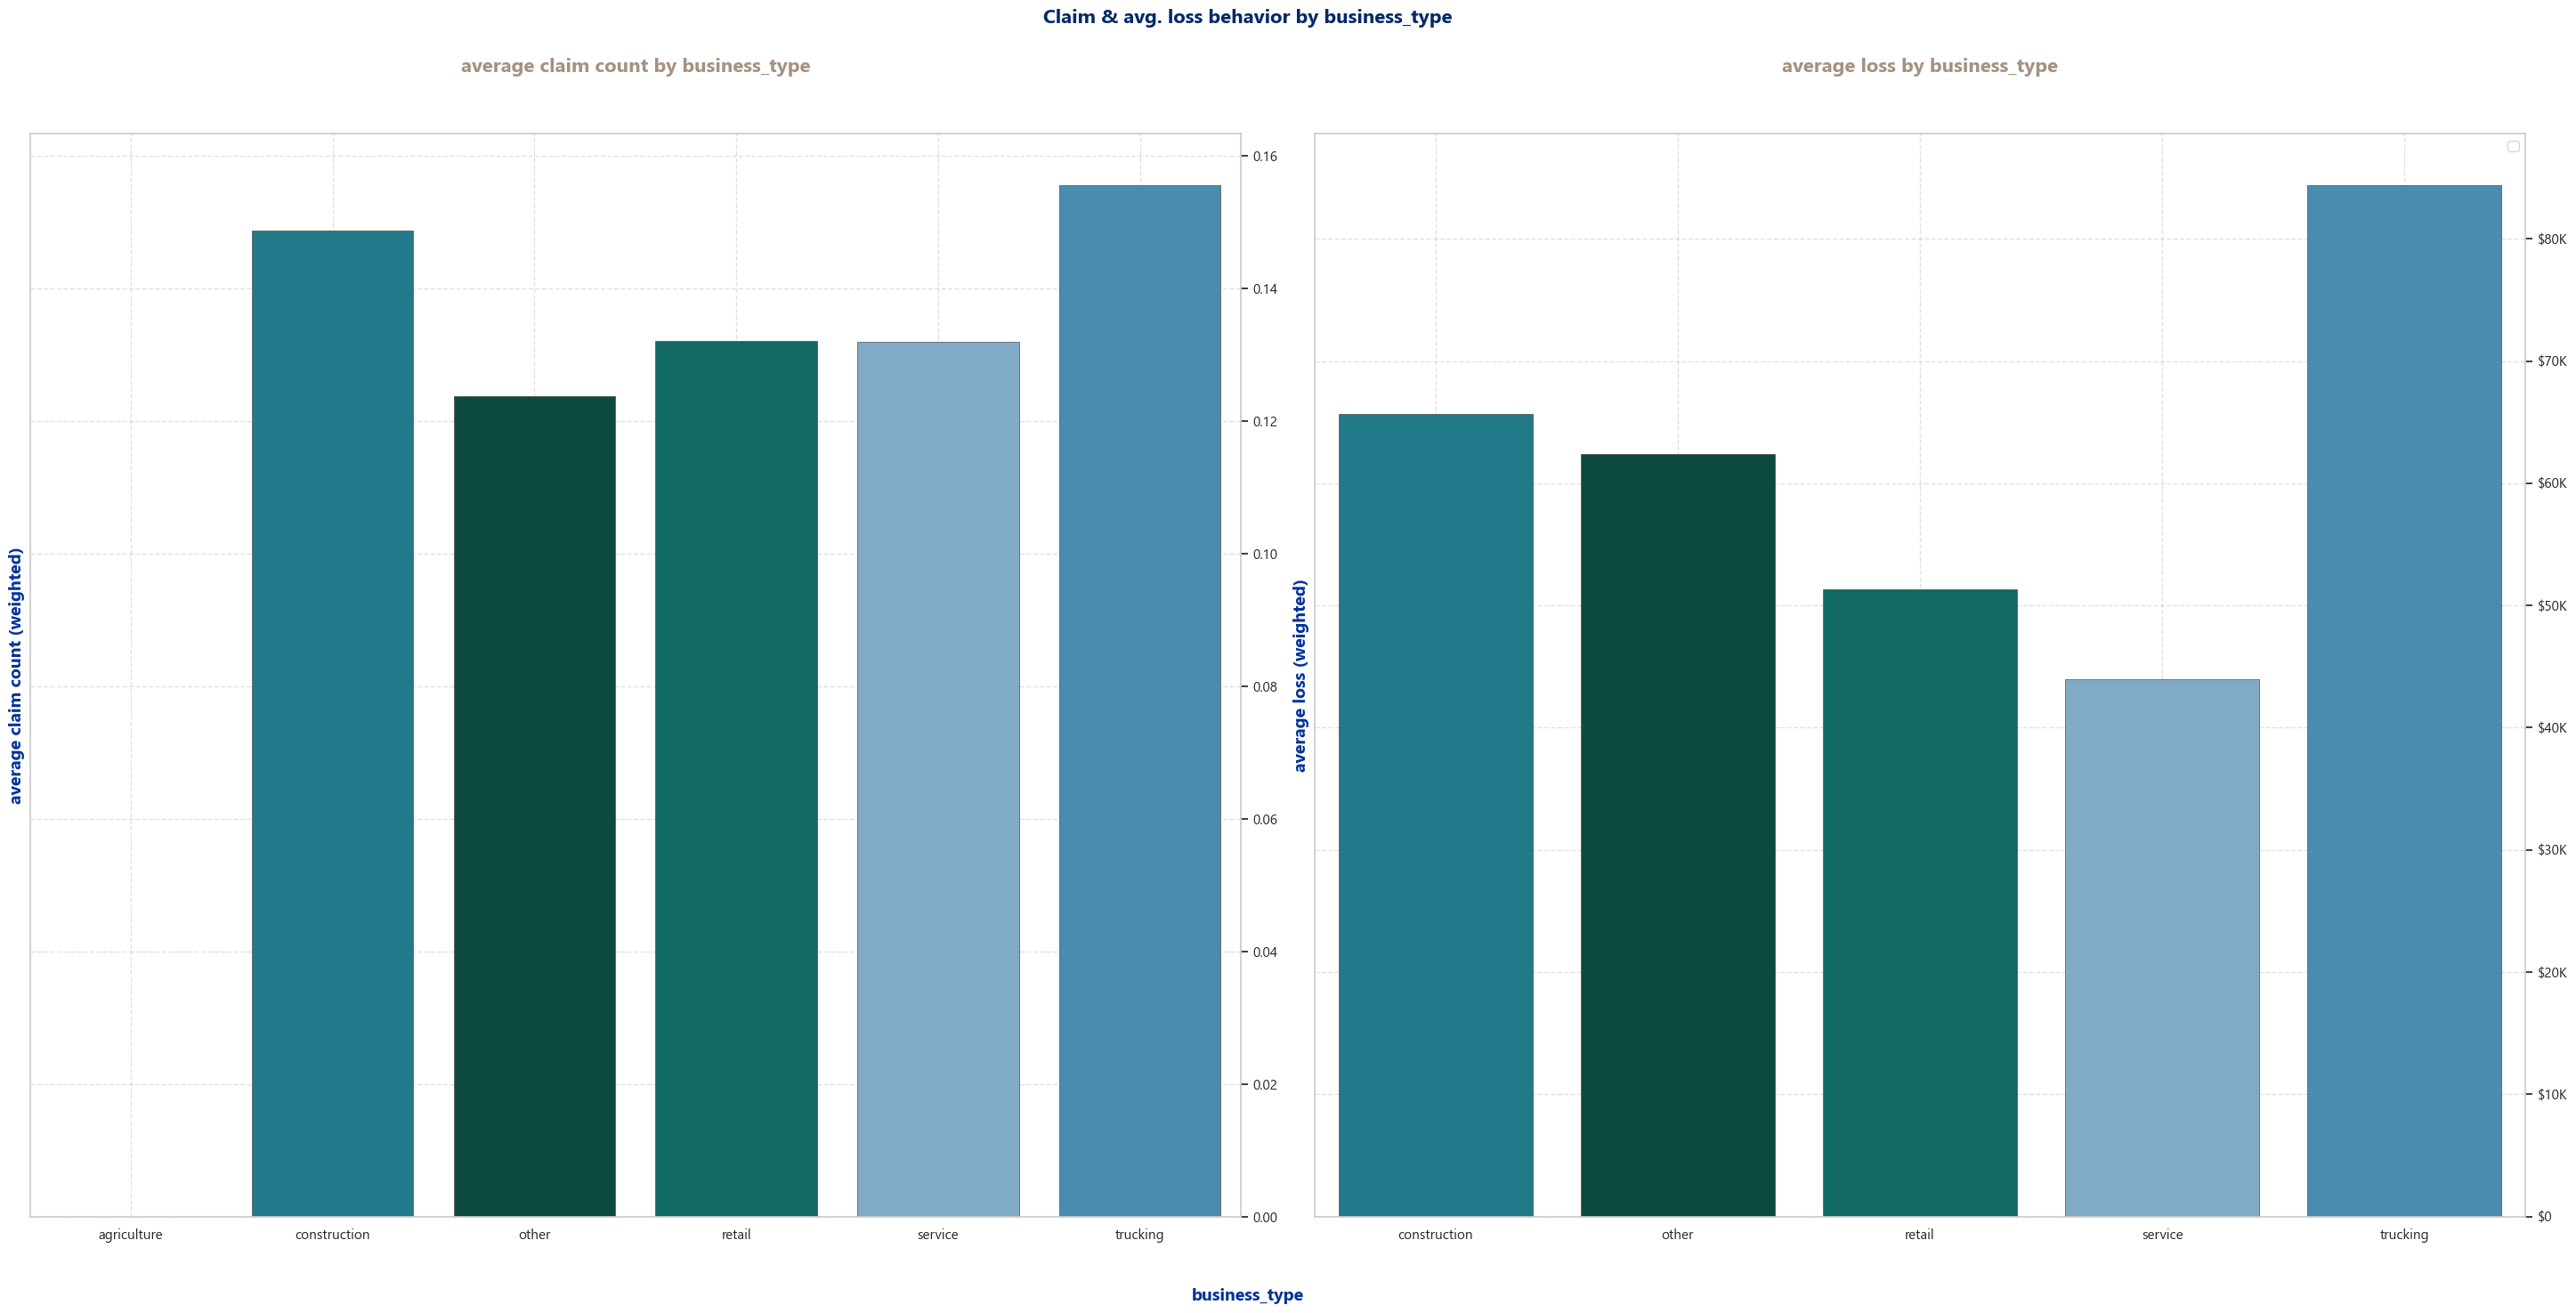

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\214803229.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\214803229.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_weighted_loss = df_claims.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\214803229.

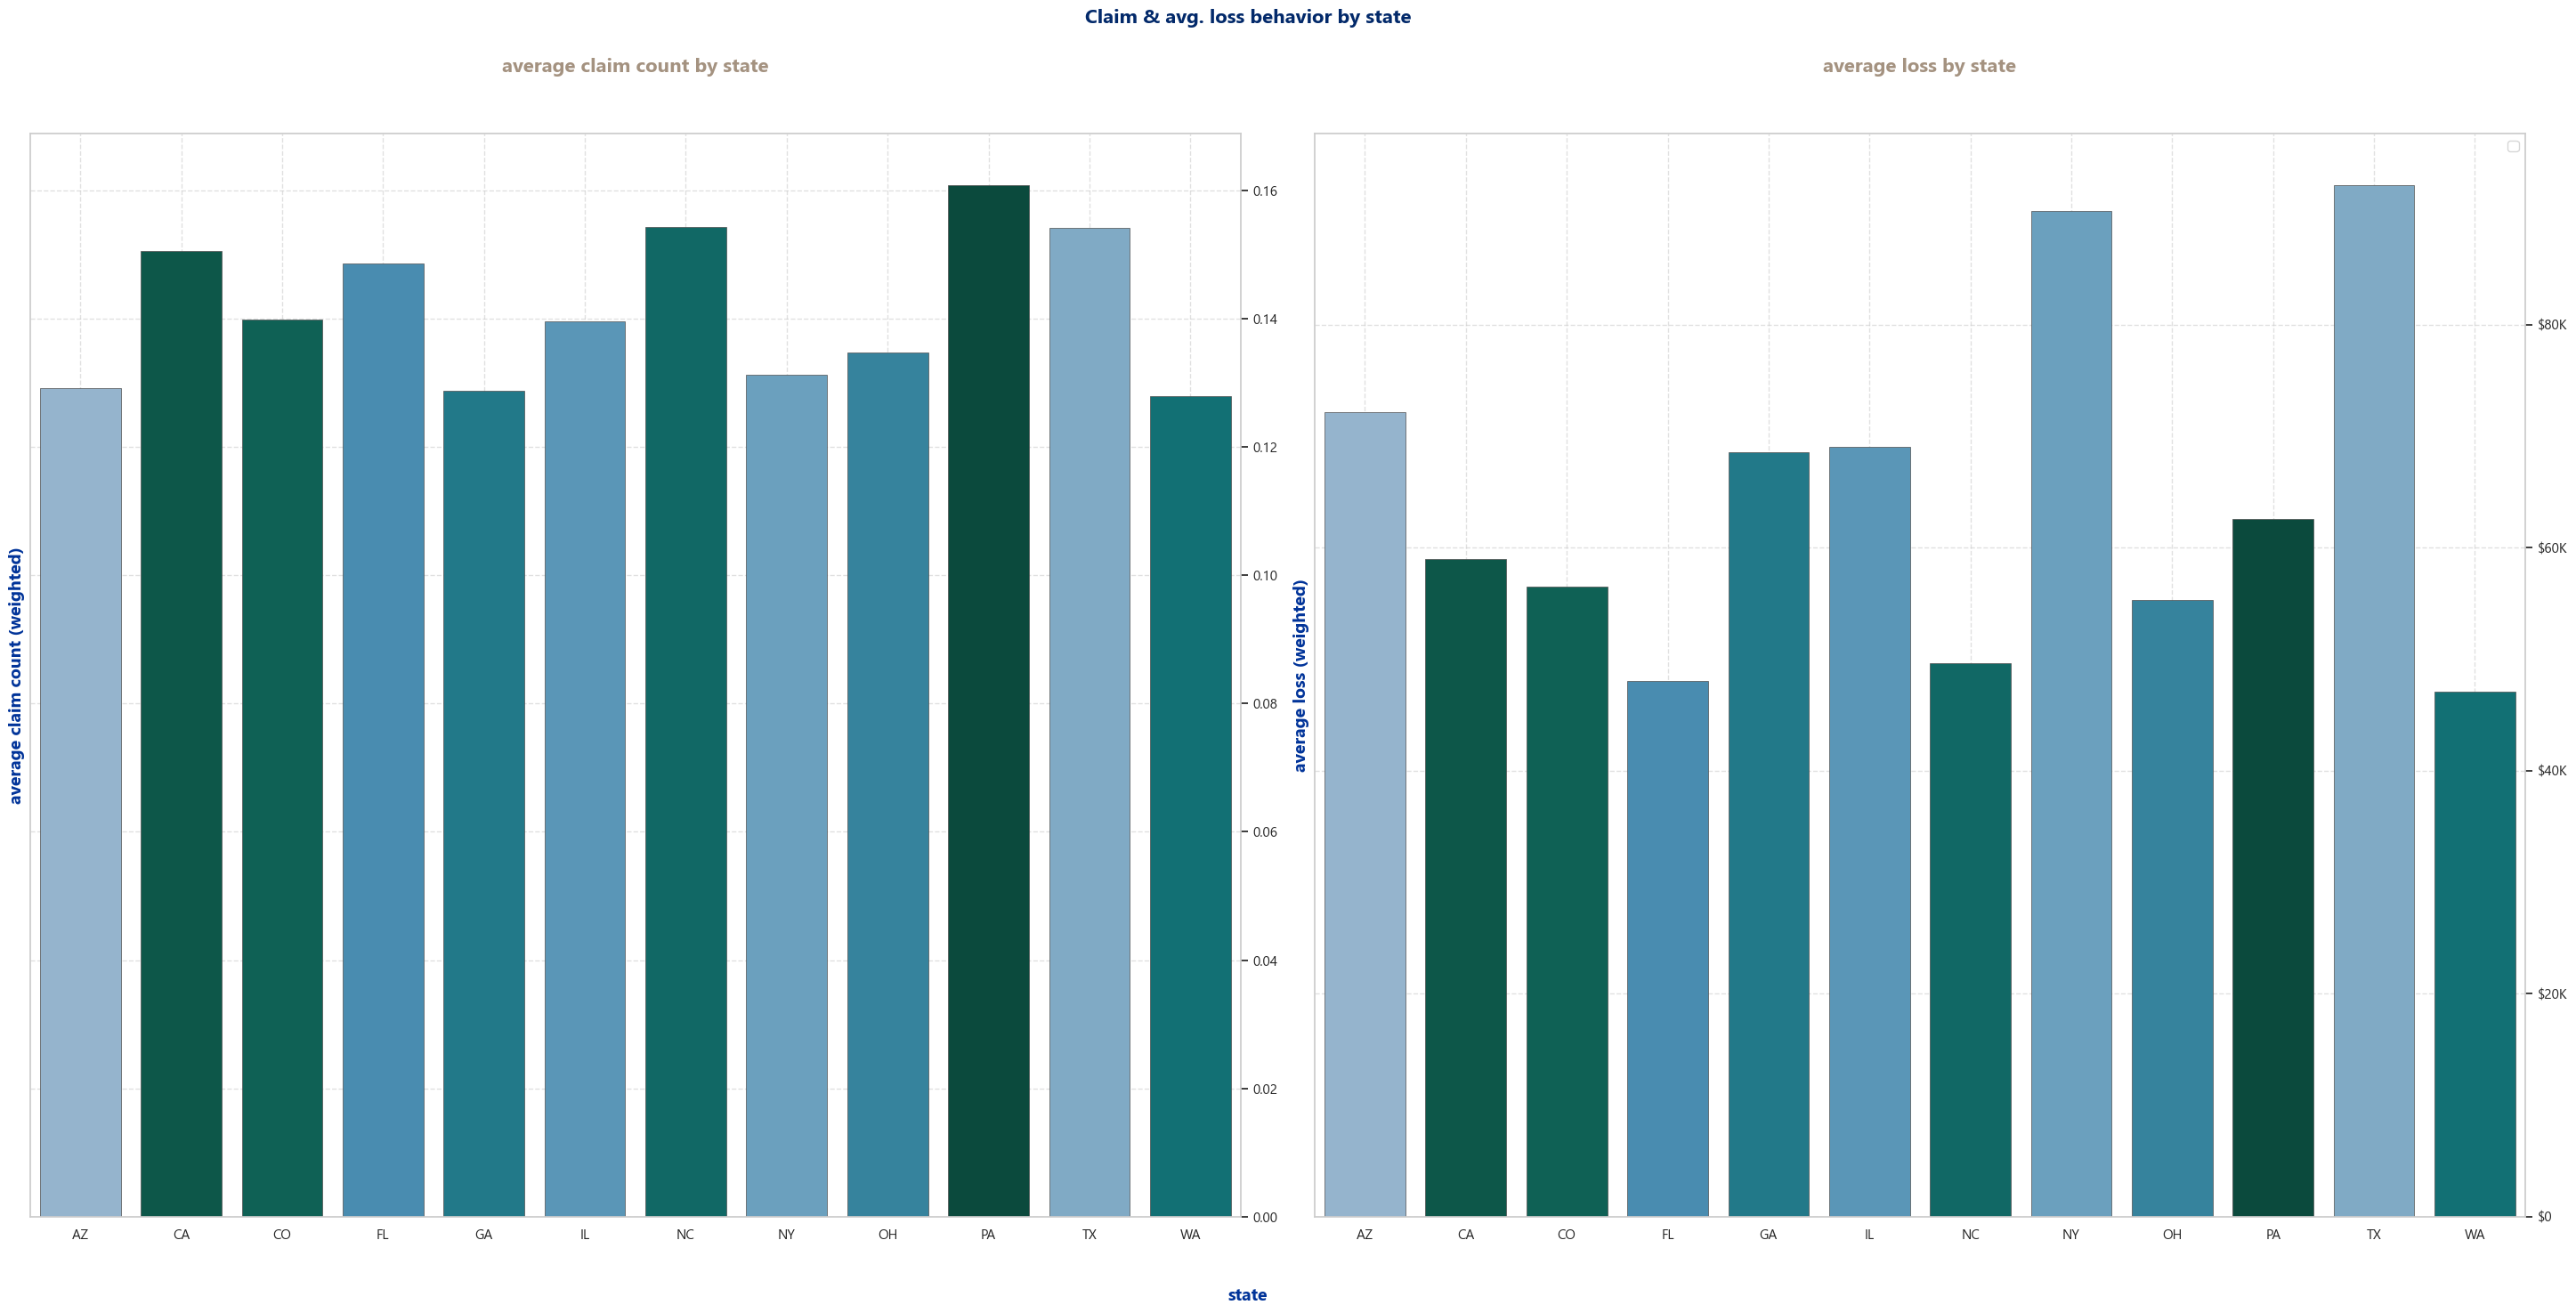

In [898]:
features_weighted = ['business_type', 'state' ]
for feature in features_weighted:
    df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
    df_weighted = df_grouped.groupby(feature).apply(weighted_average, 
                                     'claim_count', 'policy_id').reset_index().rename(columns={0: 'weighted_avg_claim_count'})

    df_weighted_loss = df_claims.groupby(feature).apply(weighted_average, 
                                     'avg_loss', 'claim_count').reset_index().rename(columns={0: 'weighted_avg_loss'})

    fig, ax = plt.subplots(1, 2, figsize=(30, 15))


    sns.barplot(
        df_weighted,
        x=feature, y="weighted_avg_claim_count", hue=feature,
        palette=category_colors,
        edgecolor=".3", 
        linewidth=.5,
        ax=ax[0]
    )

    ax[0].yaxis.tick_right()
    ax[0].grid(True, linestyle="--", alpha = 0.6)
    ax[0].set_xlabel('')
    ax[0].set_ylabel('average claim count (weighted)',fontsize=14,fontweight='bold', color='#003399')
    ax[0].set_title(f"average claim count by {feature}", y=1.04, fontsize=16, pad=15, fontweight='bold', color = '#A49280')
    ax[0].grid(True, linestyle="--", alpha = 0.6)
    ax[0].yaxis.tick_right()

    sns.barplot(
        df_weighted_loss,
        x=feature, y="weighted_avg_loss", hue=feature,
        palette=category_colors,
        edgecolor=".3", 
        linewidth=.5,
        ax=ax[1]
    )

    ax[1].yaxis.tick_right()
    ax[1].grid(True, linestyle="--", alpha = 0.6)
    ax[1].set_xlabel('')
    ax[1].set_ylabel('average loss (weighted)',fontsize=14,fontweight='bold', color='#003399')
    ax[1].set_title(f"average loss by {feature}", y=1.04, fontsize=16, pad=15, fontweight='bold', color = '#A49280')
    ax[1].grid(True, linestyle="--", alpha = 0.6)
    ax[1].yaxis.tick_right()
    ax[1].get_yaxis().set_major_formatter(
    FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}'))

    fig.suptitle(f"Claim & avg. loss behavior by {feature}", fontsize=16, fontweight='bold', color = '#02296A')
    fig.supxlabel(feature, fontsize=14 ,fontweight='bold', color = '#003399')


    plt.legend()
    plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
    plt.show()

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

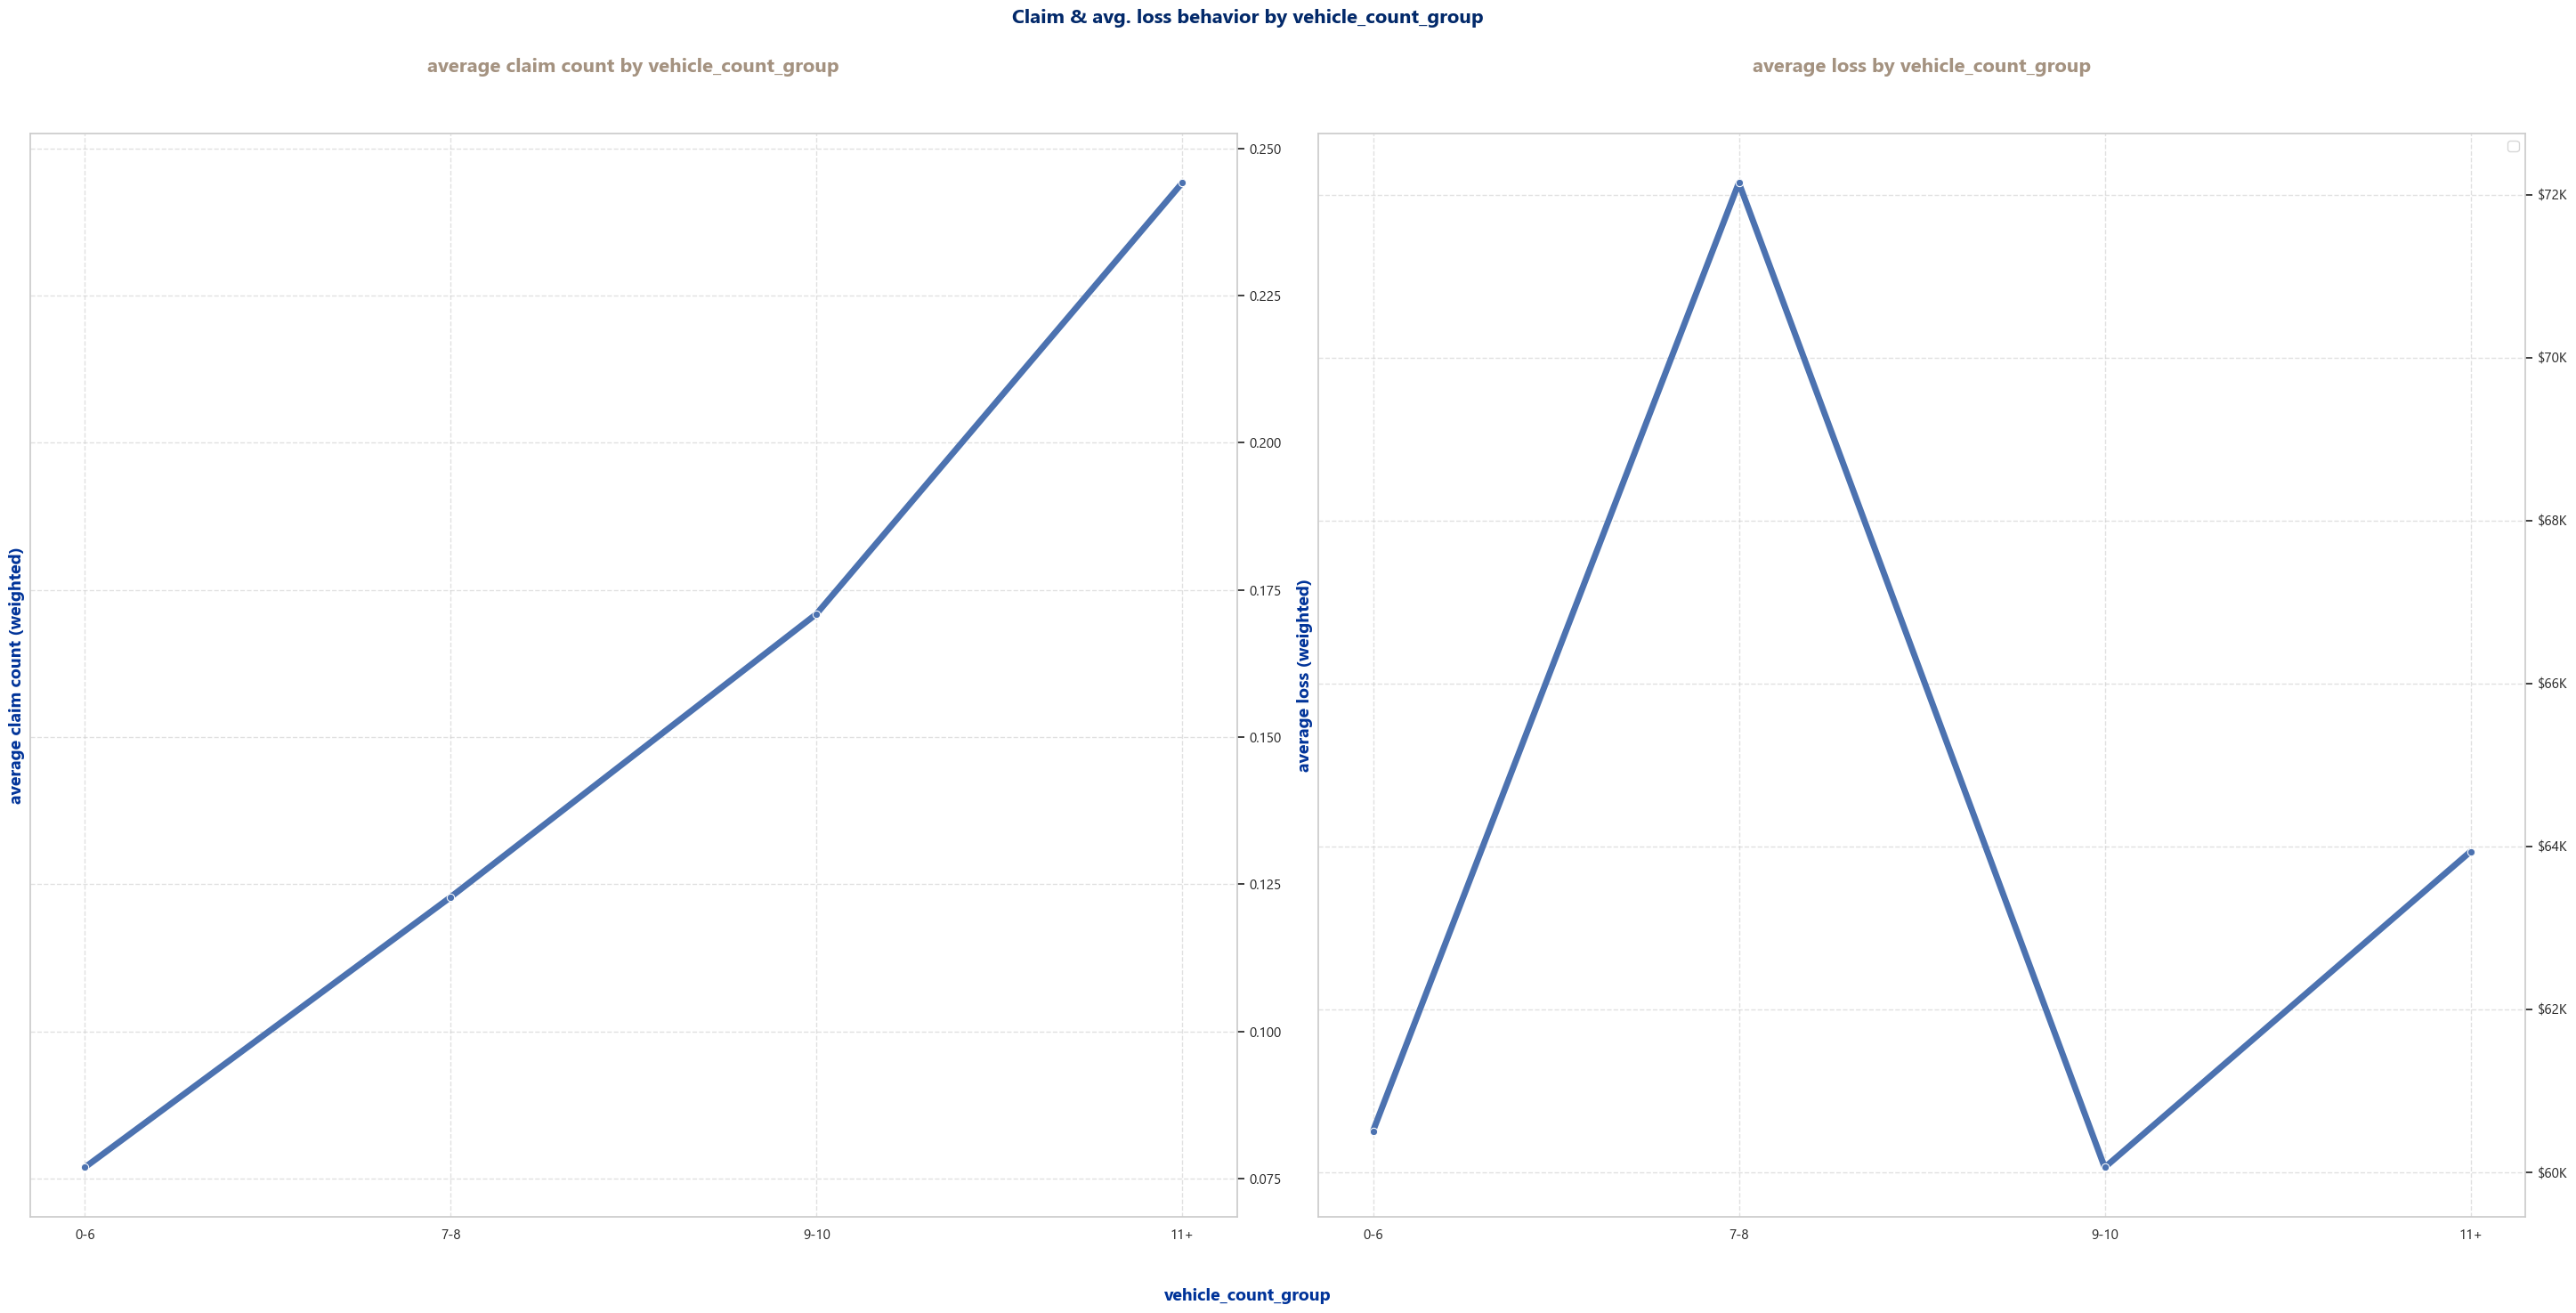

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

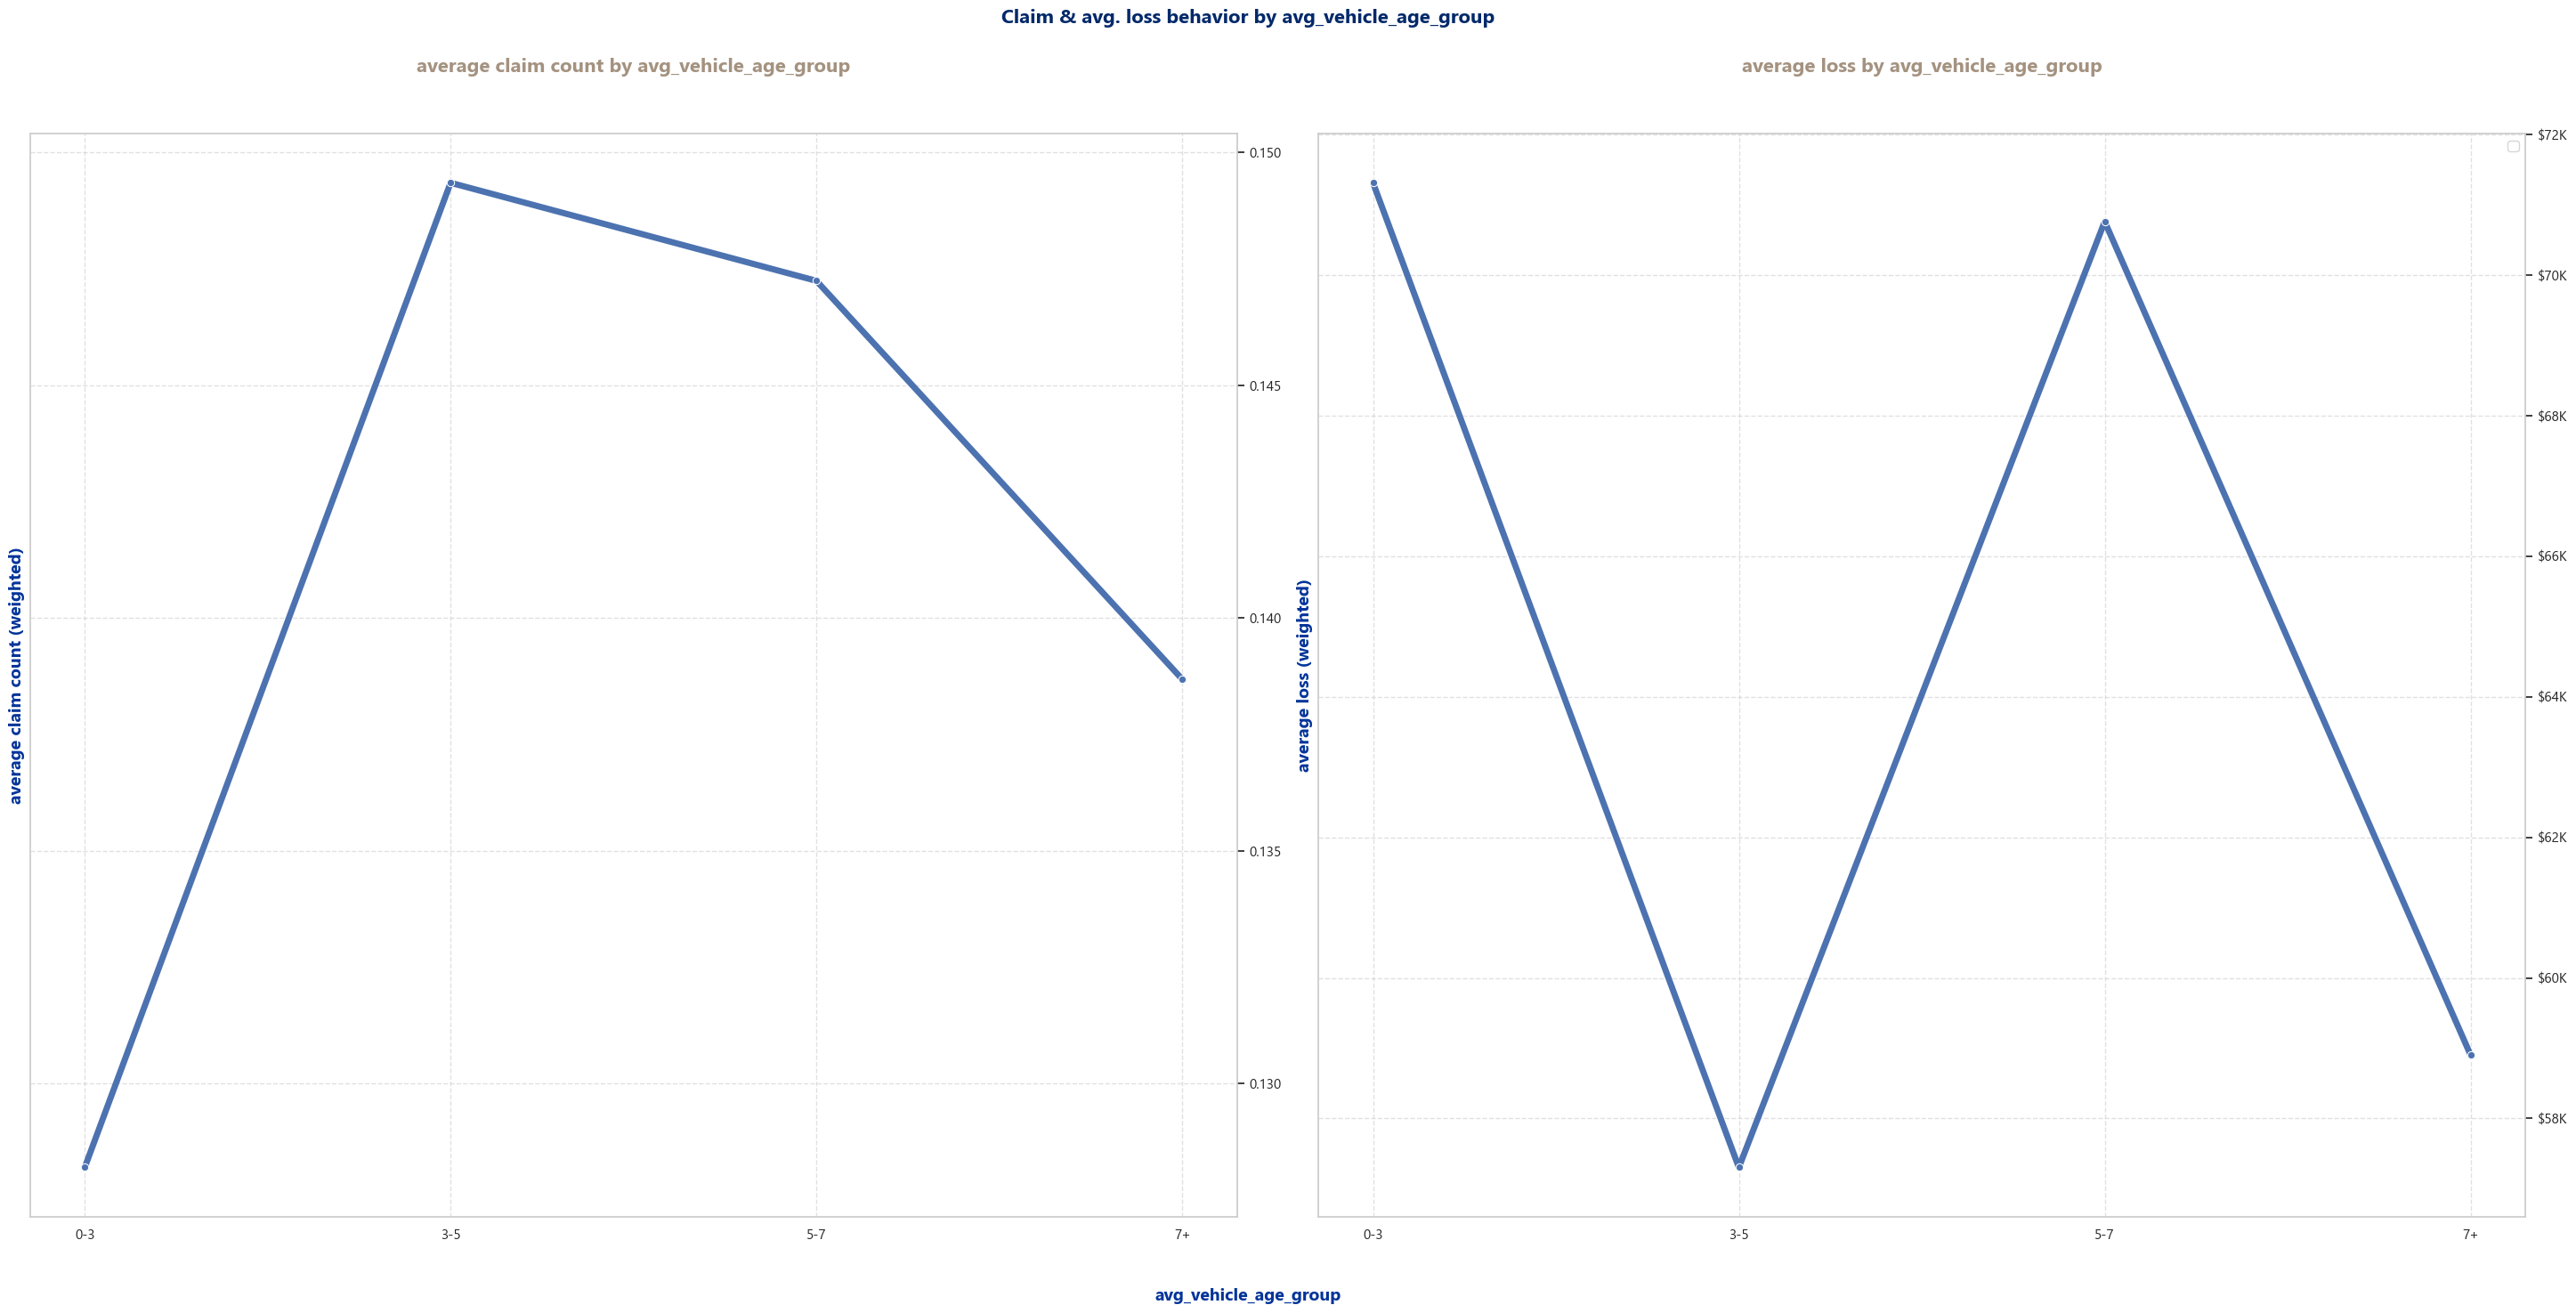

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

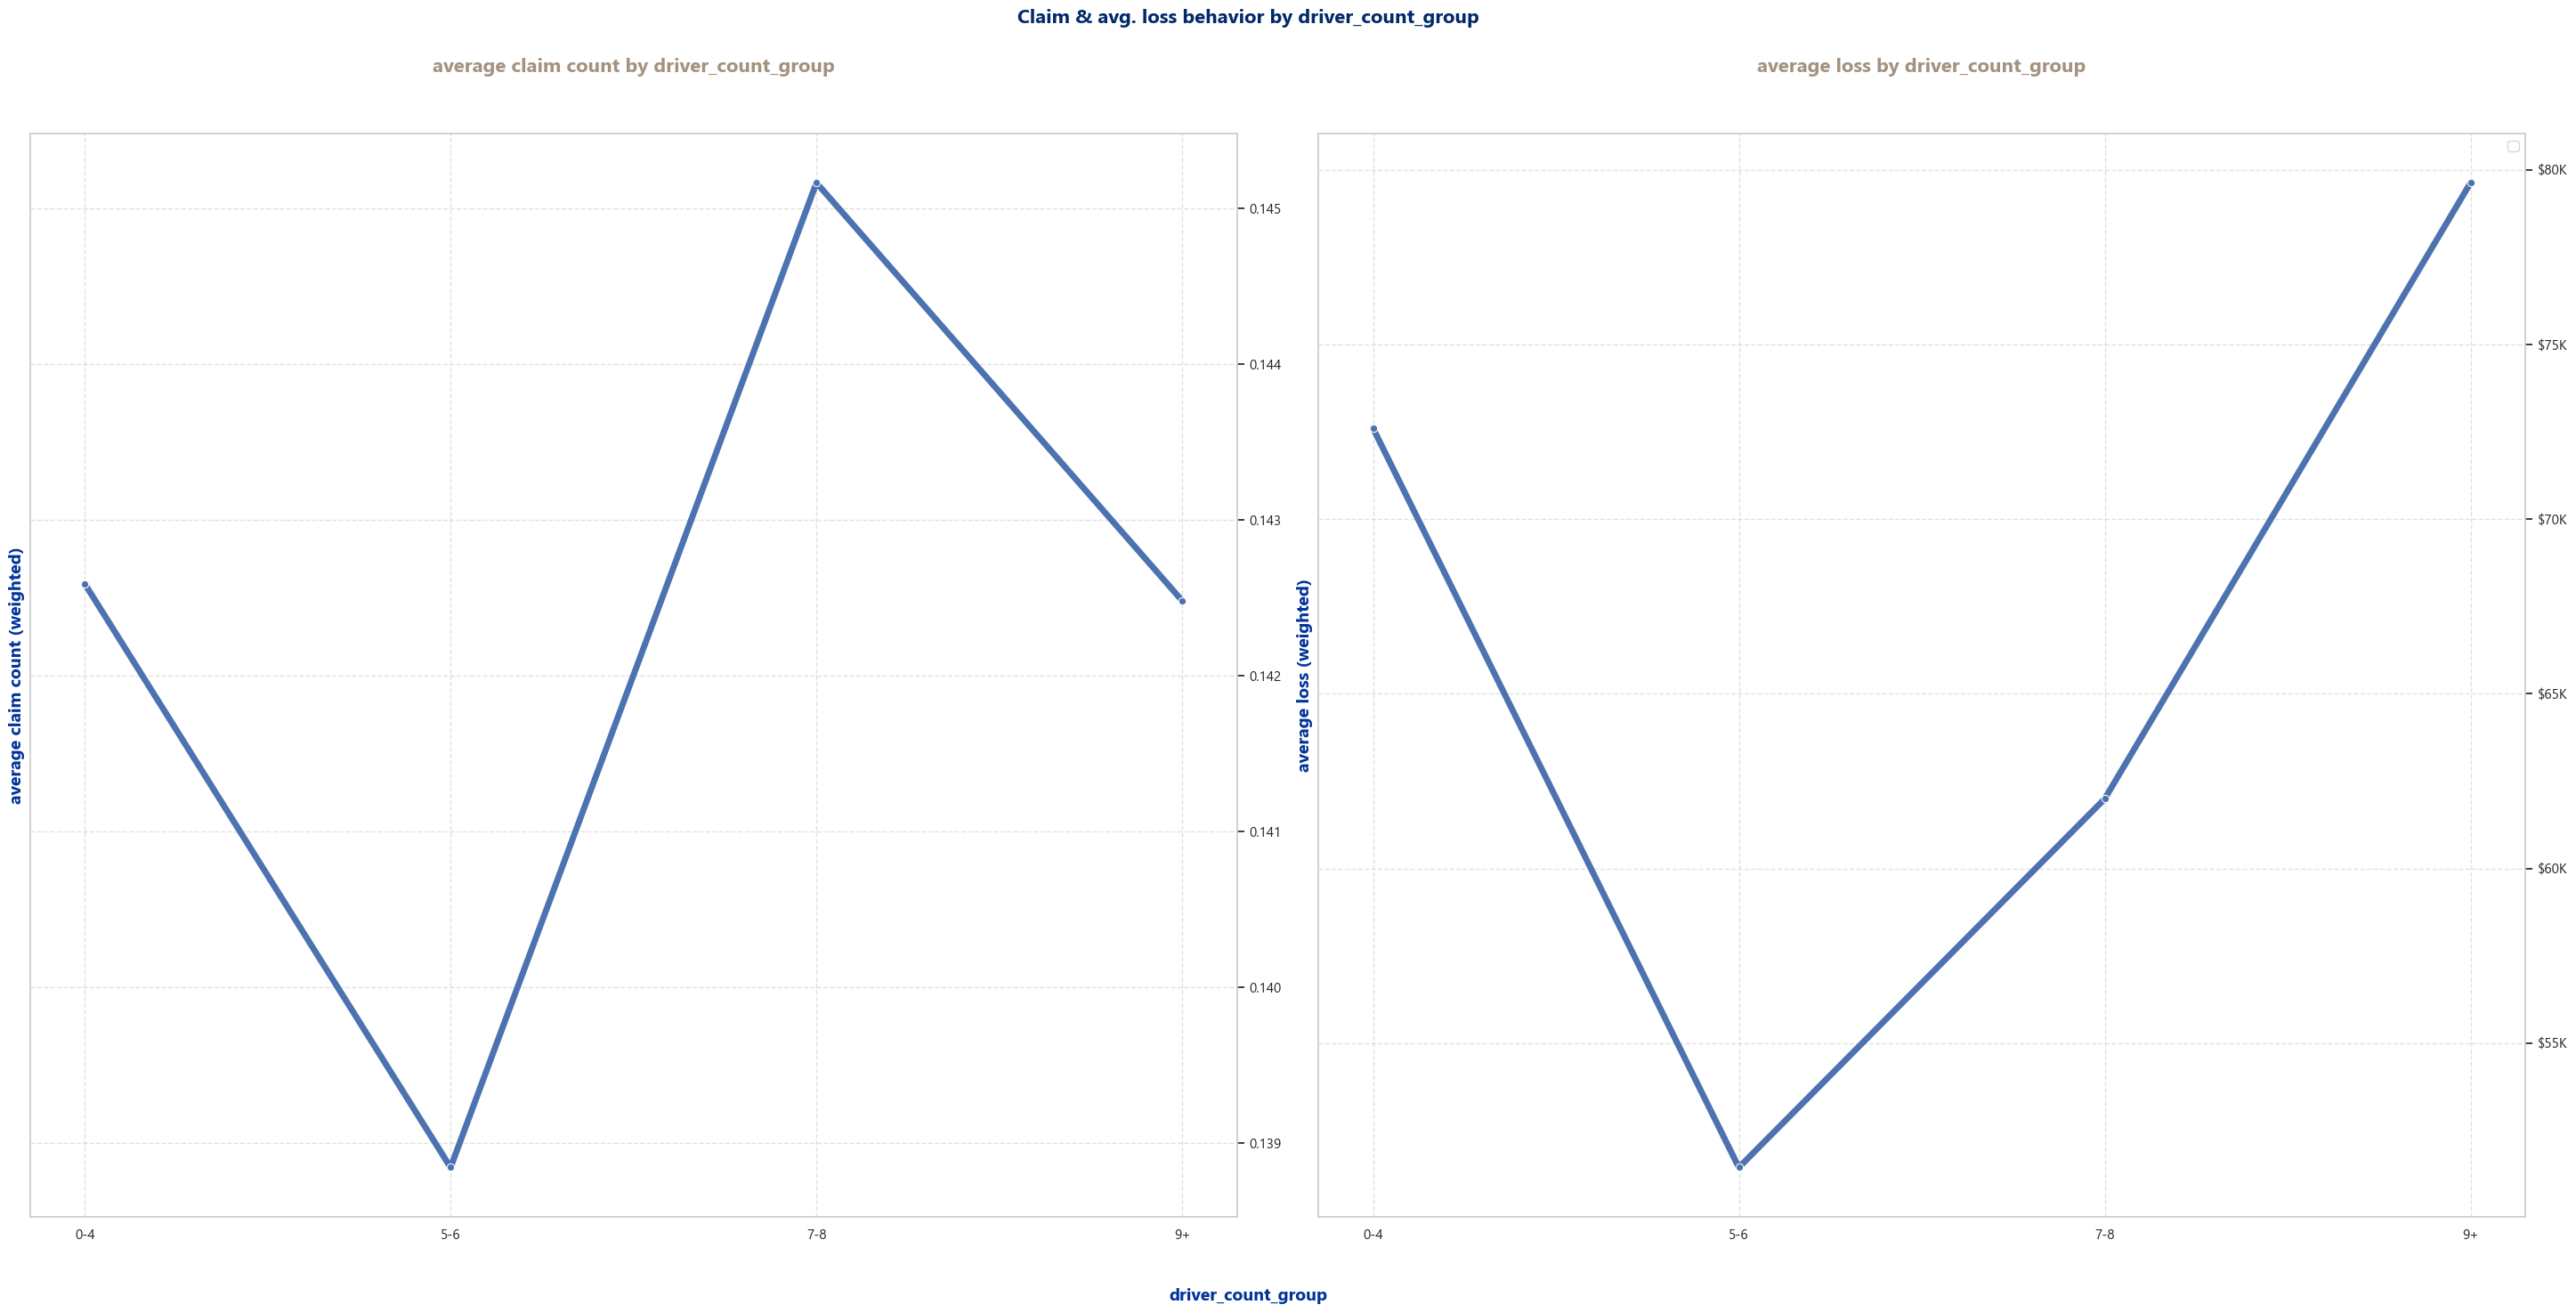

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

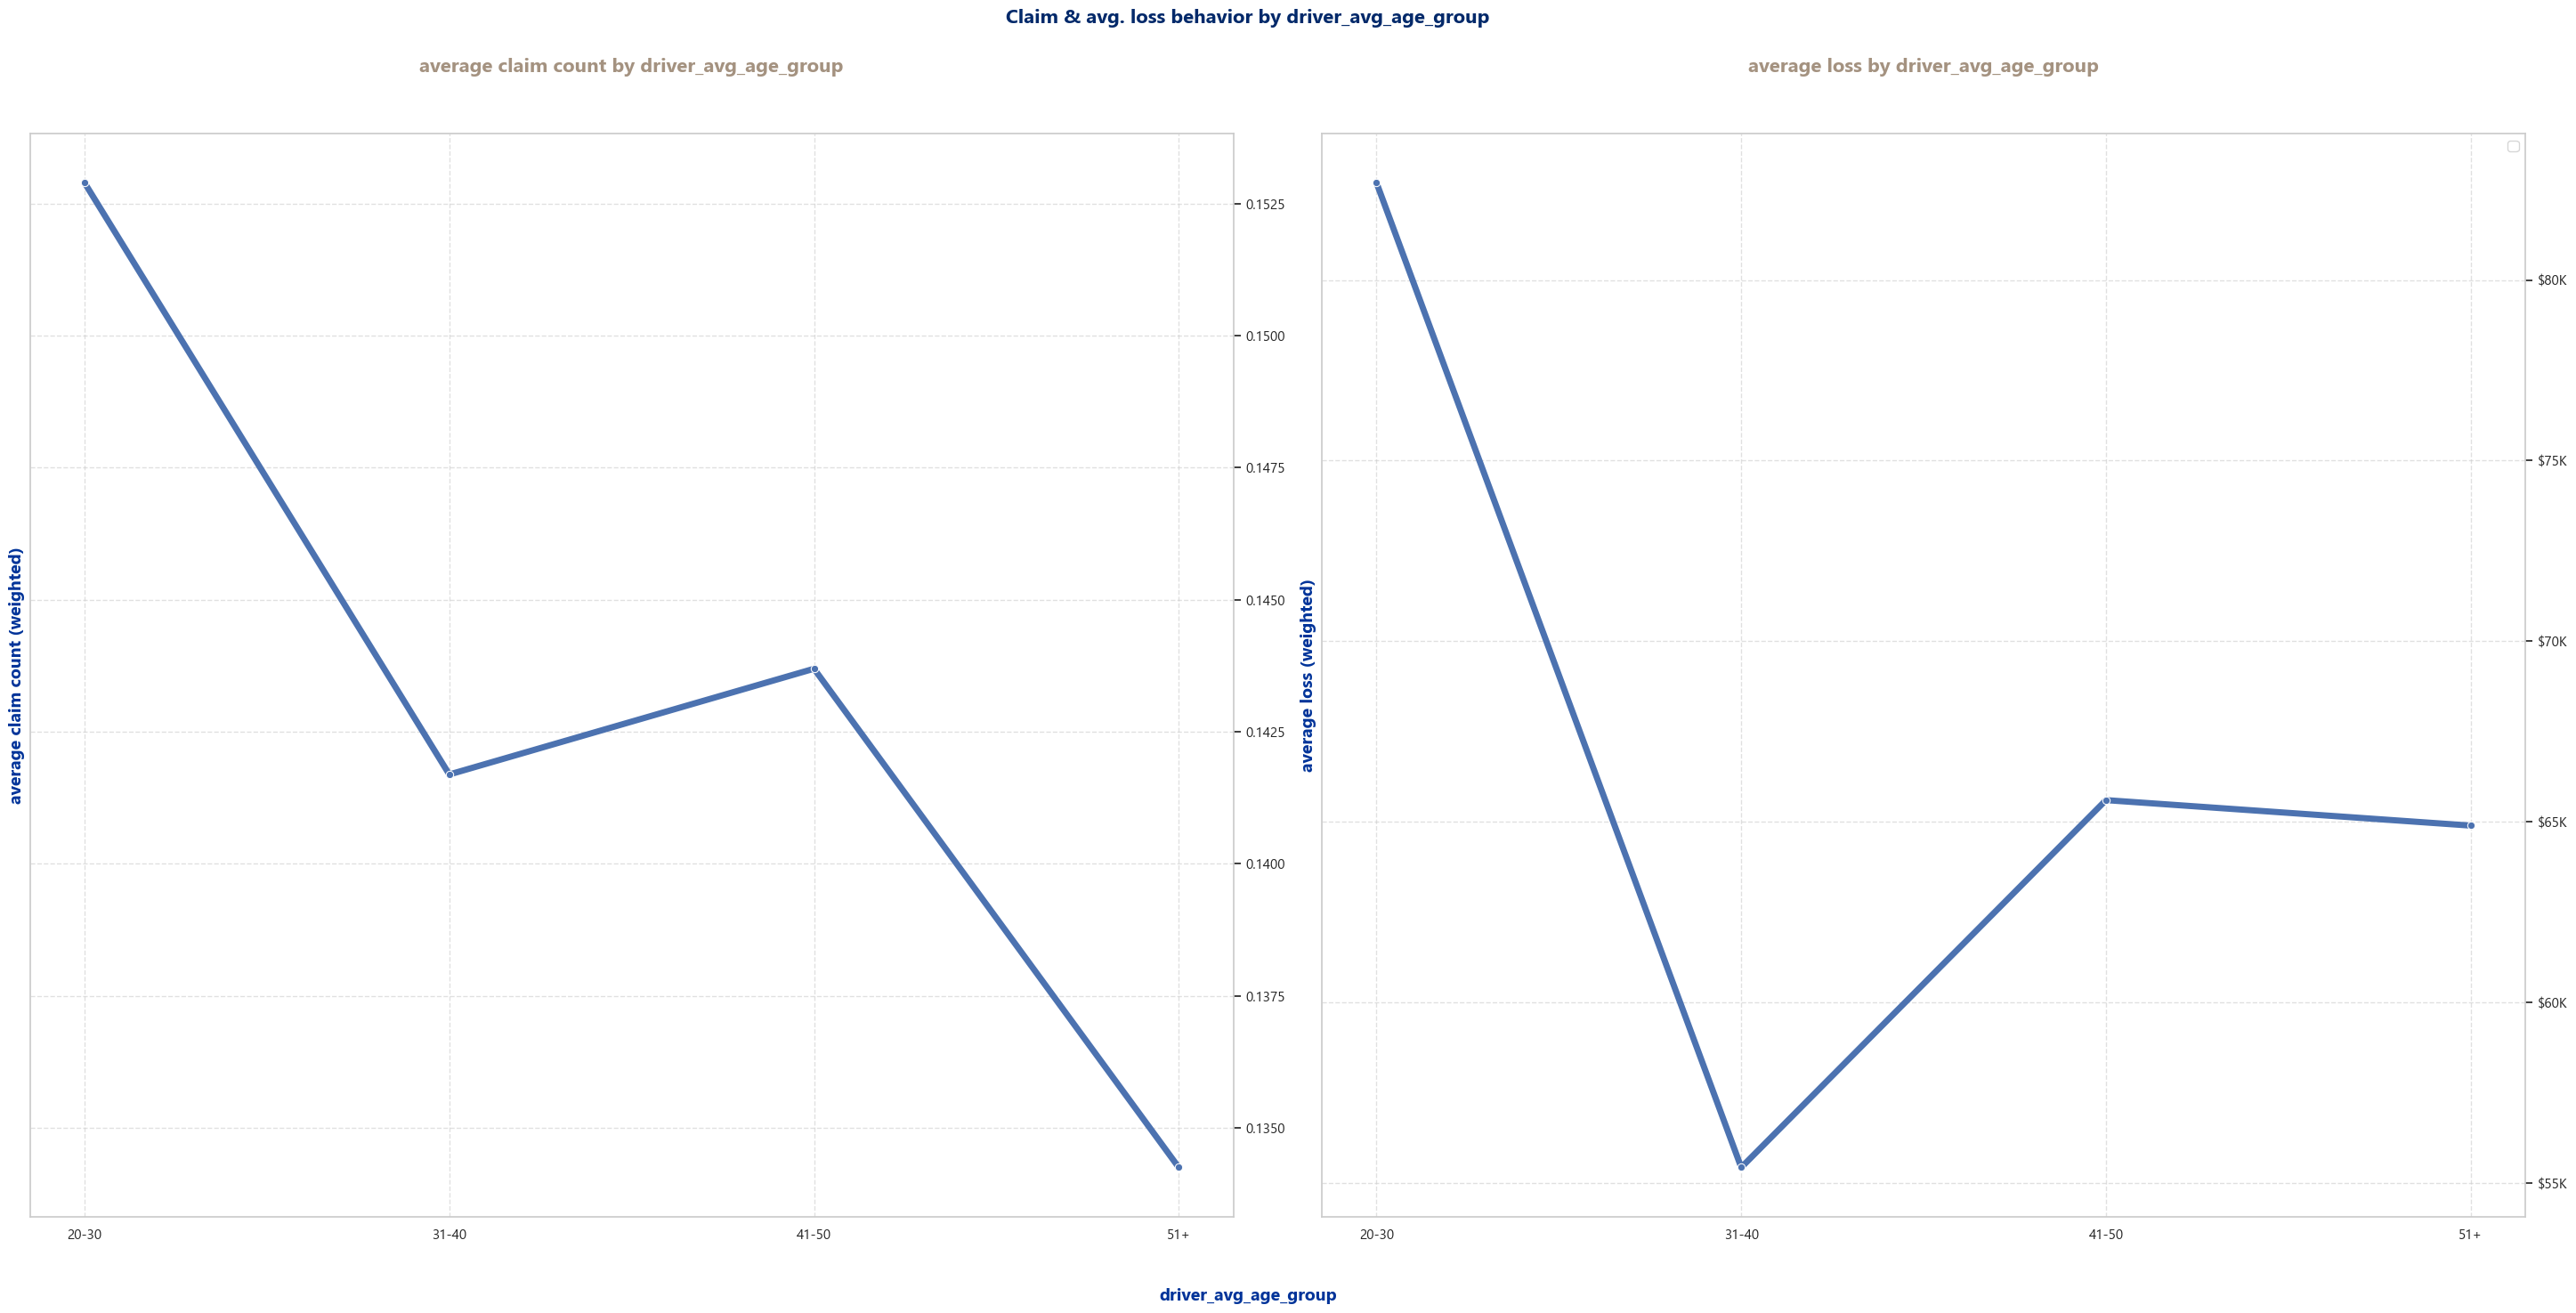

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

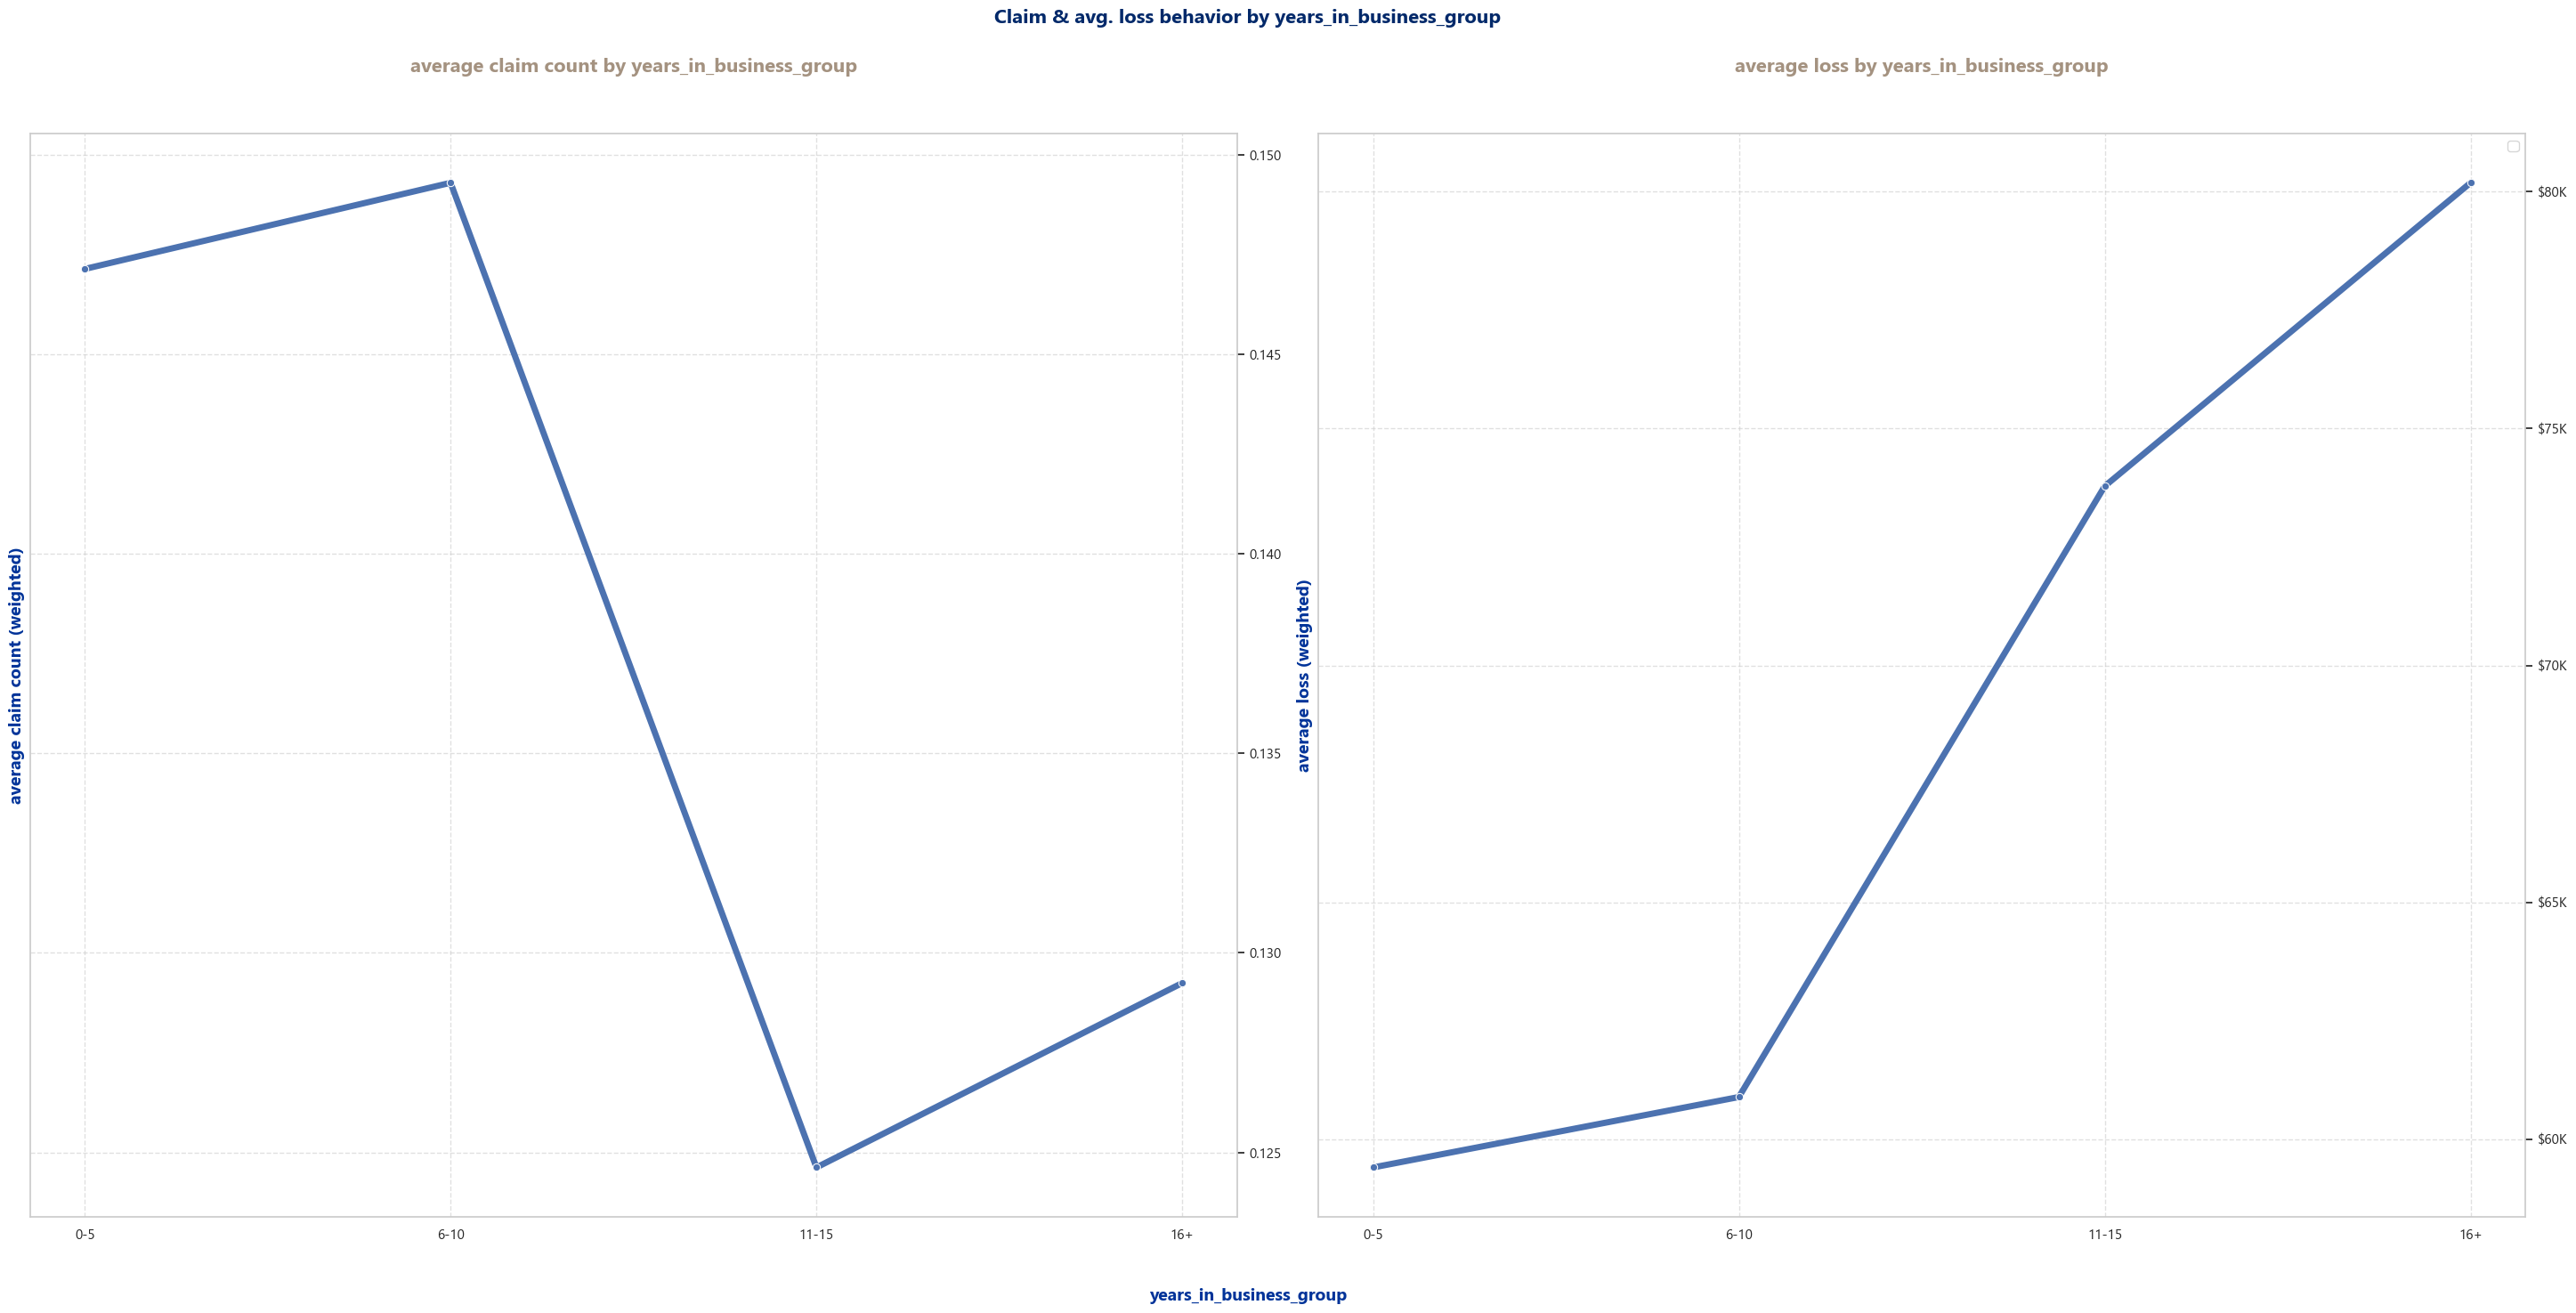

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

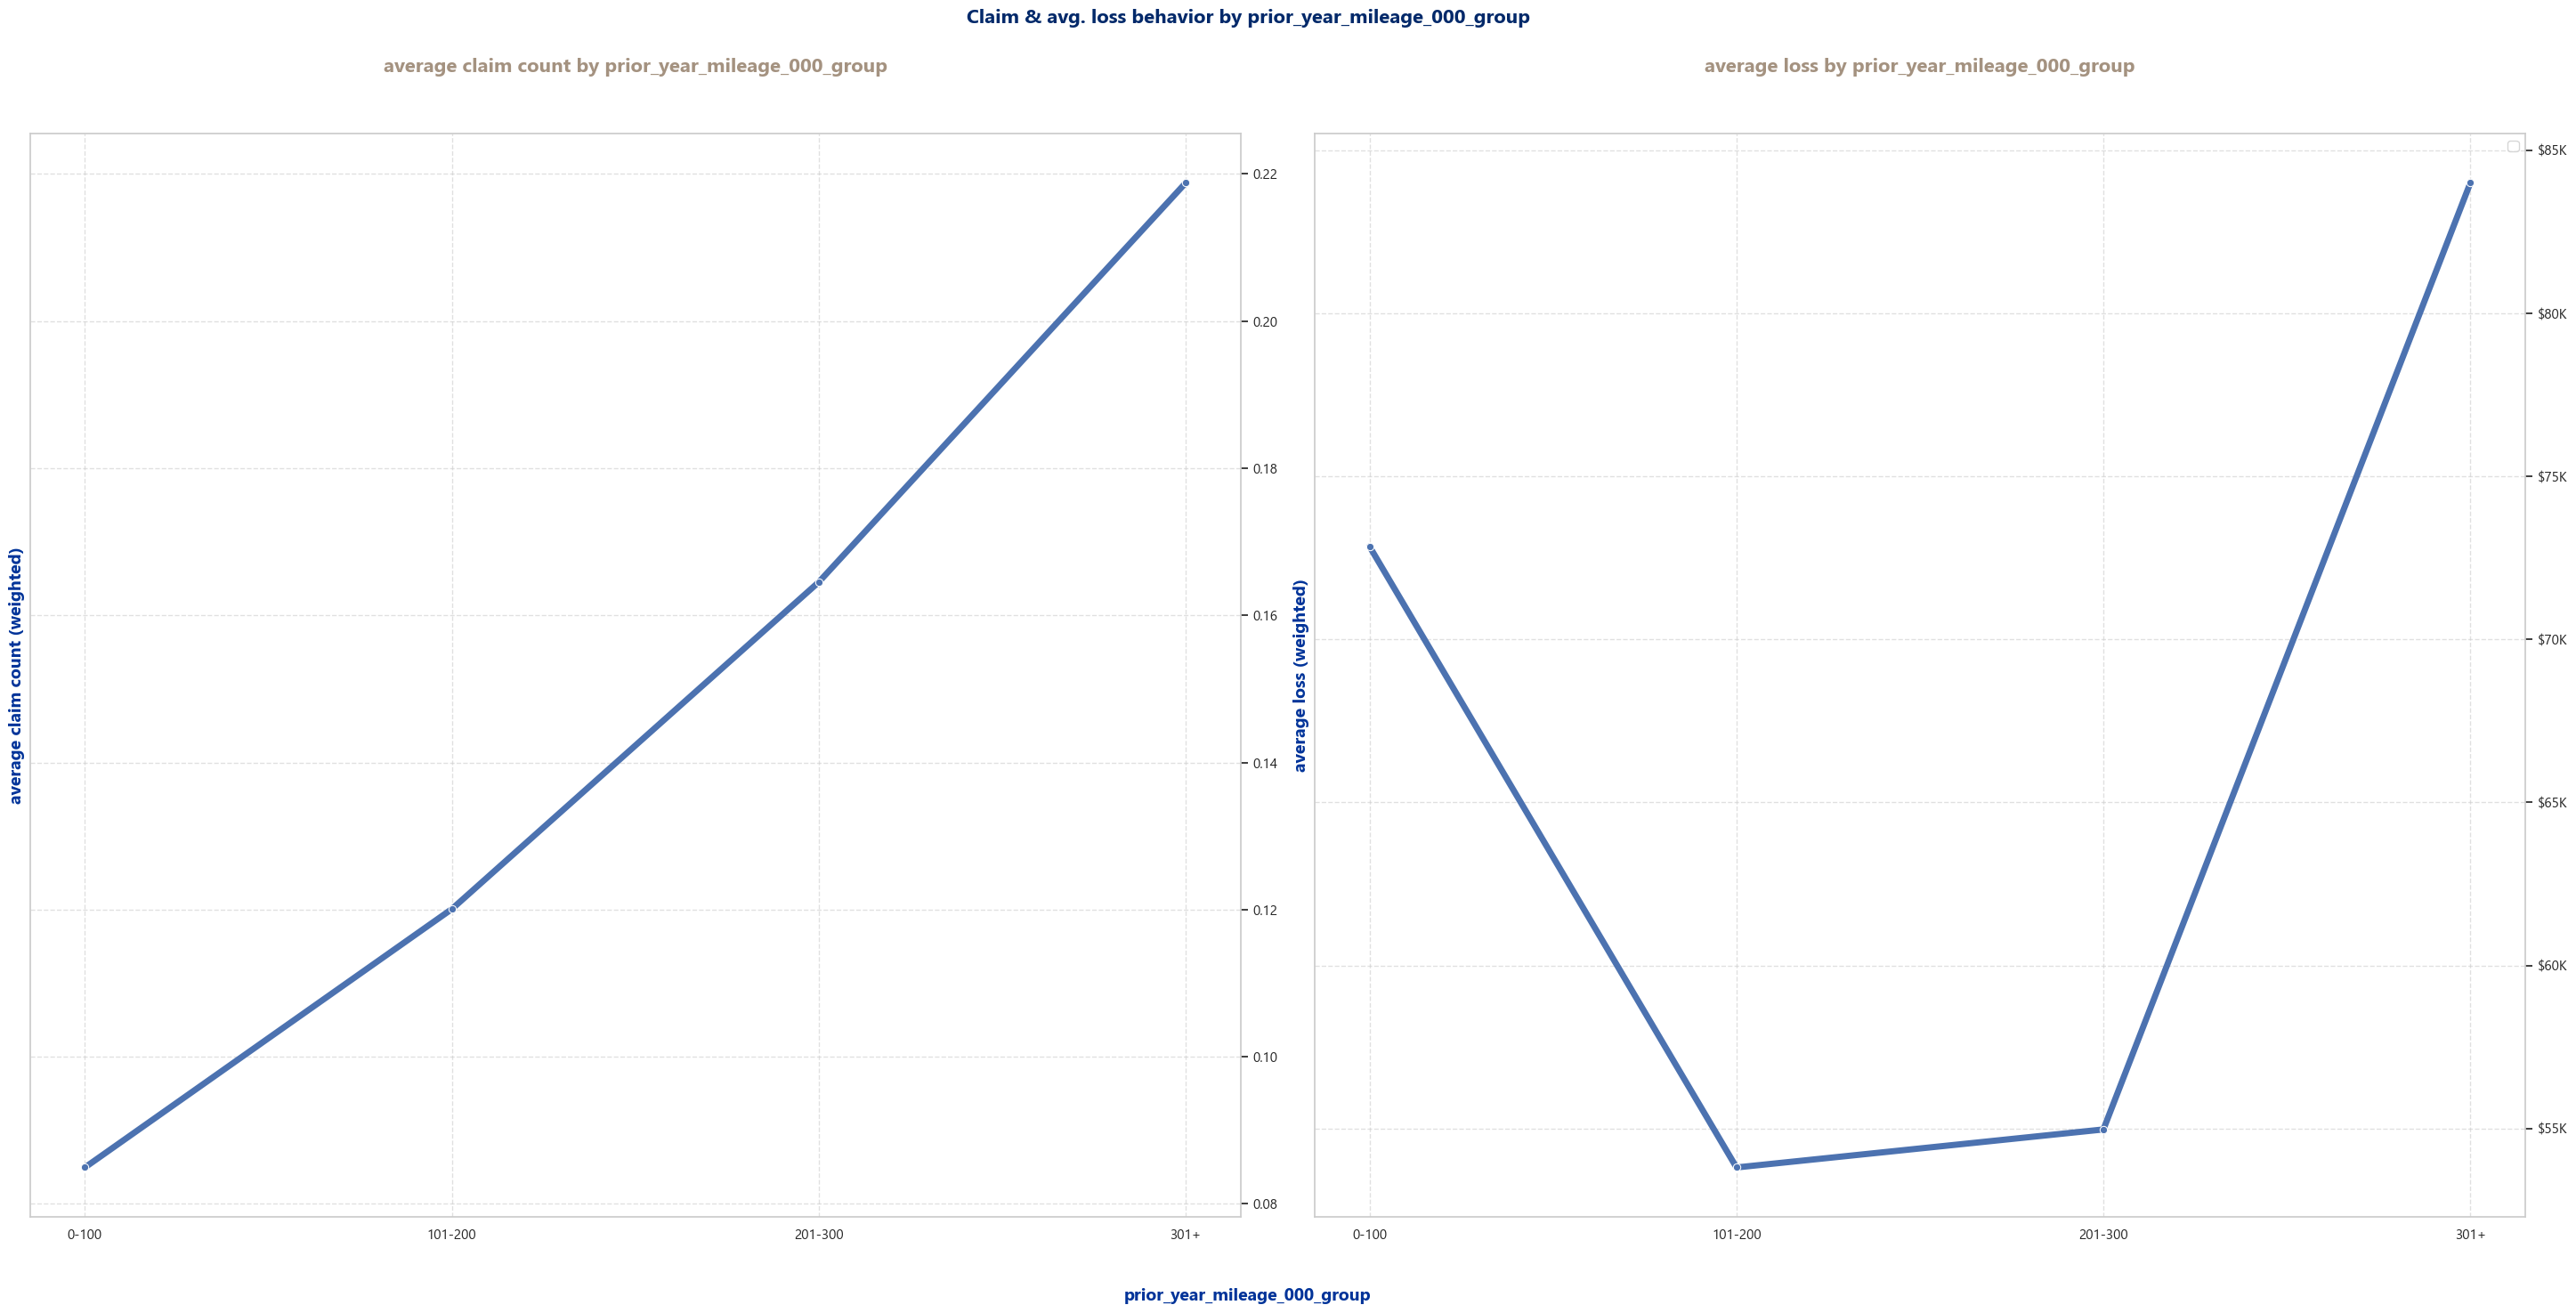

In [899]:
features_weighted = ['vehicle_count_group', 'avg_vehicle_age_group', 'driver_count_group', 'driver_avg_age_group', 'years_in_business_group', 'prior_year_mileage_000_group']
for feature in features_weighted:
    df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
    df_weighted = df_grouped.groupby(feature).apply(weighted_average, 
                                     'claim_count', 'policy_id').reset_index().rename(columns={0: 'weighted_avg_claim_count'})

    df_weighted_loss = df_claims.groupby(feature).apply(weighted_average, 
                                     'avg_loss', 'claim_count').reset_index().rename(columns={0: 'weighted_avg_loss'})

    fig, ax = plt.subplots(1, 2, figsize=(30, 15))


    sns.lineplot(
        df_weighted,
        x=feature, y="weighted_avg_claim_count",
        linewidth=5,
        ax=ax[0],
        marker="o"
    )

    ax[0].yaxis.tick_right()
    ax[0].grid(True, linestyle="--", alpha = 0.6)
    ax[0].set_xlabel('')
    ax[0].set_ylabel('average claim count (weighted)',fontsize=14,fontweight='bold', color='#003399')
    ax[0].set_title(f"average claim count by {feature}", y=1.04, fontsize=16, pad=15, fontweight='bold', color = '#A49280')
    ax[0].grid(True, linestyle="--", alpha = 0.6)
    ax[0].yaxis.tick_right()

    sns.lineplot(
        df_weighted_loss,
        x=feature, y="weighted_avg_loss",
        linewidth=5,
        ax=ax[1],
        marker="o"
    )

    ax[1].yaxis.tick_right()
    ax[1].grid(True, linestyle="--", alpha = 0.6)
    ax[1].set_xlabel('')
    ax[1].set_ylabel('average loss (weighted)',fontsize=14,fontweight='bold', color='#003399')
    ax[1].set_title(f"average loss by {feature}", y=1.04, fontsize=16, pad=15, fontweight='bold', color = '#A49280')
    ax[1].grid(True, linestyle="--", alpha = 0.6)
    ax[1].yaxis.tick_right()
    ax[1].get_yaxis().set_major_formatter(
    FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}'))

    fig.suptitle(f"Claim & avg. loss behavior by {feature}", fontsize=16, fontweight='bold', color = '#02296A')
    fig.supxlabel(feature, fontsize=14 ,fontweight='bold', color = '#003399')


    plt.legend()
    plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
    plt.show()

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

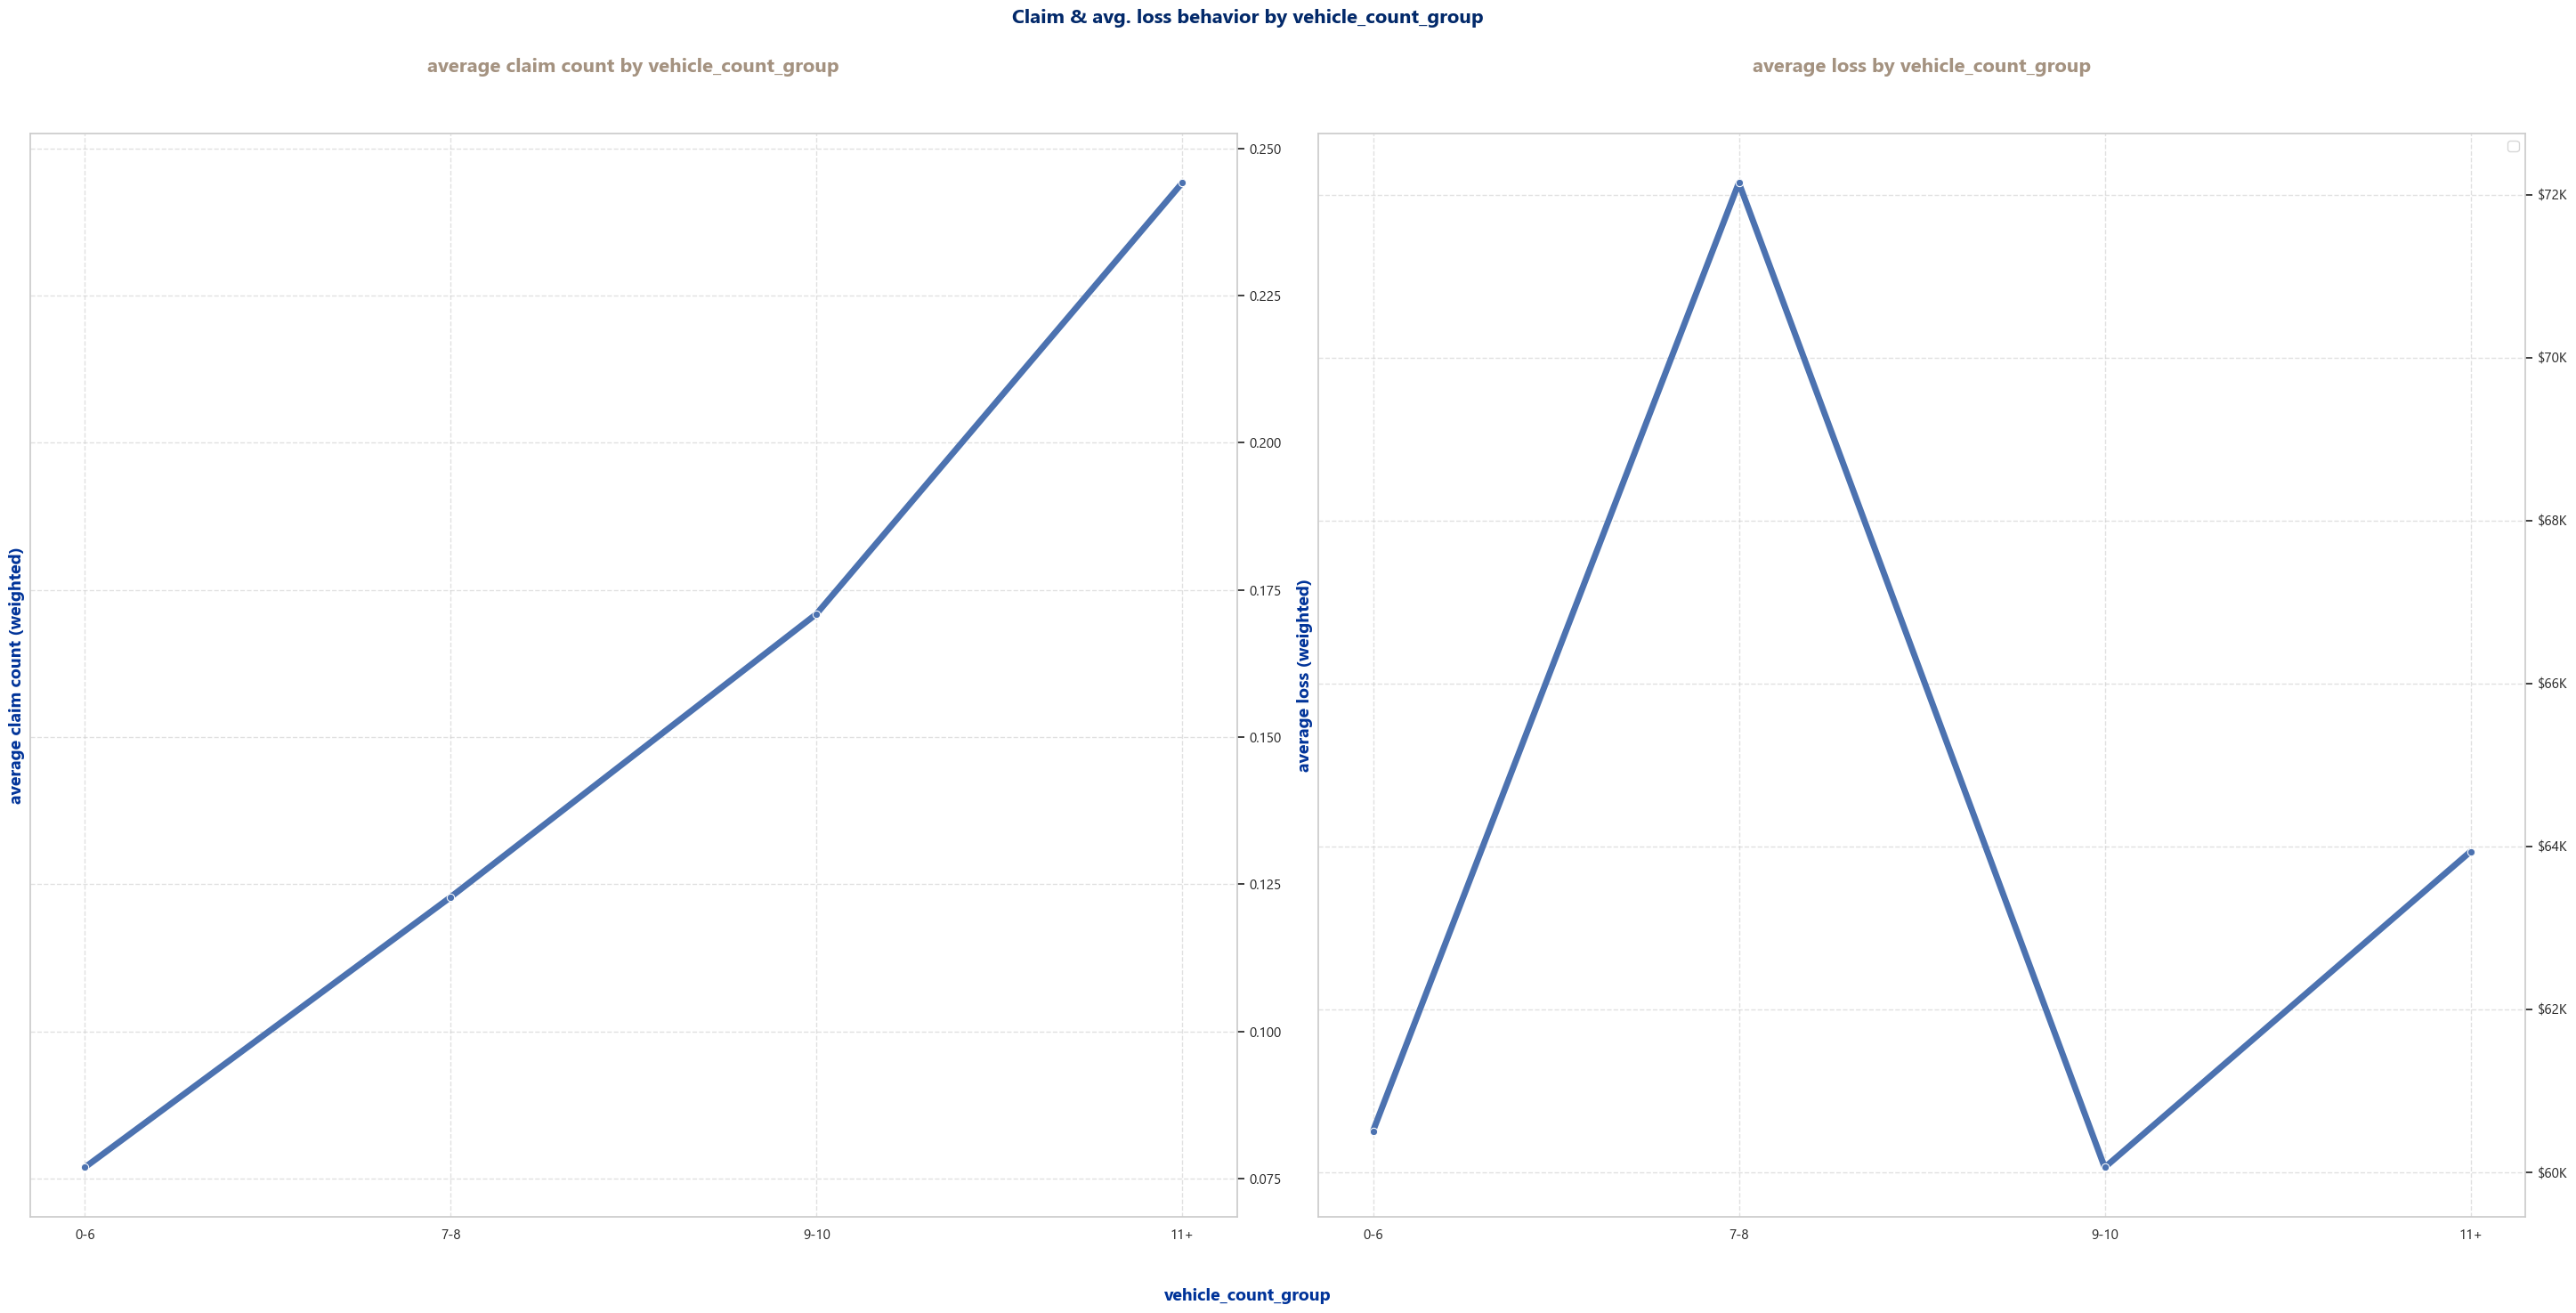

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

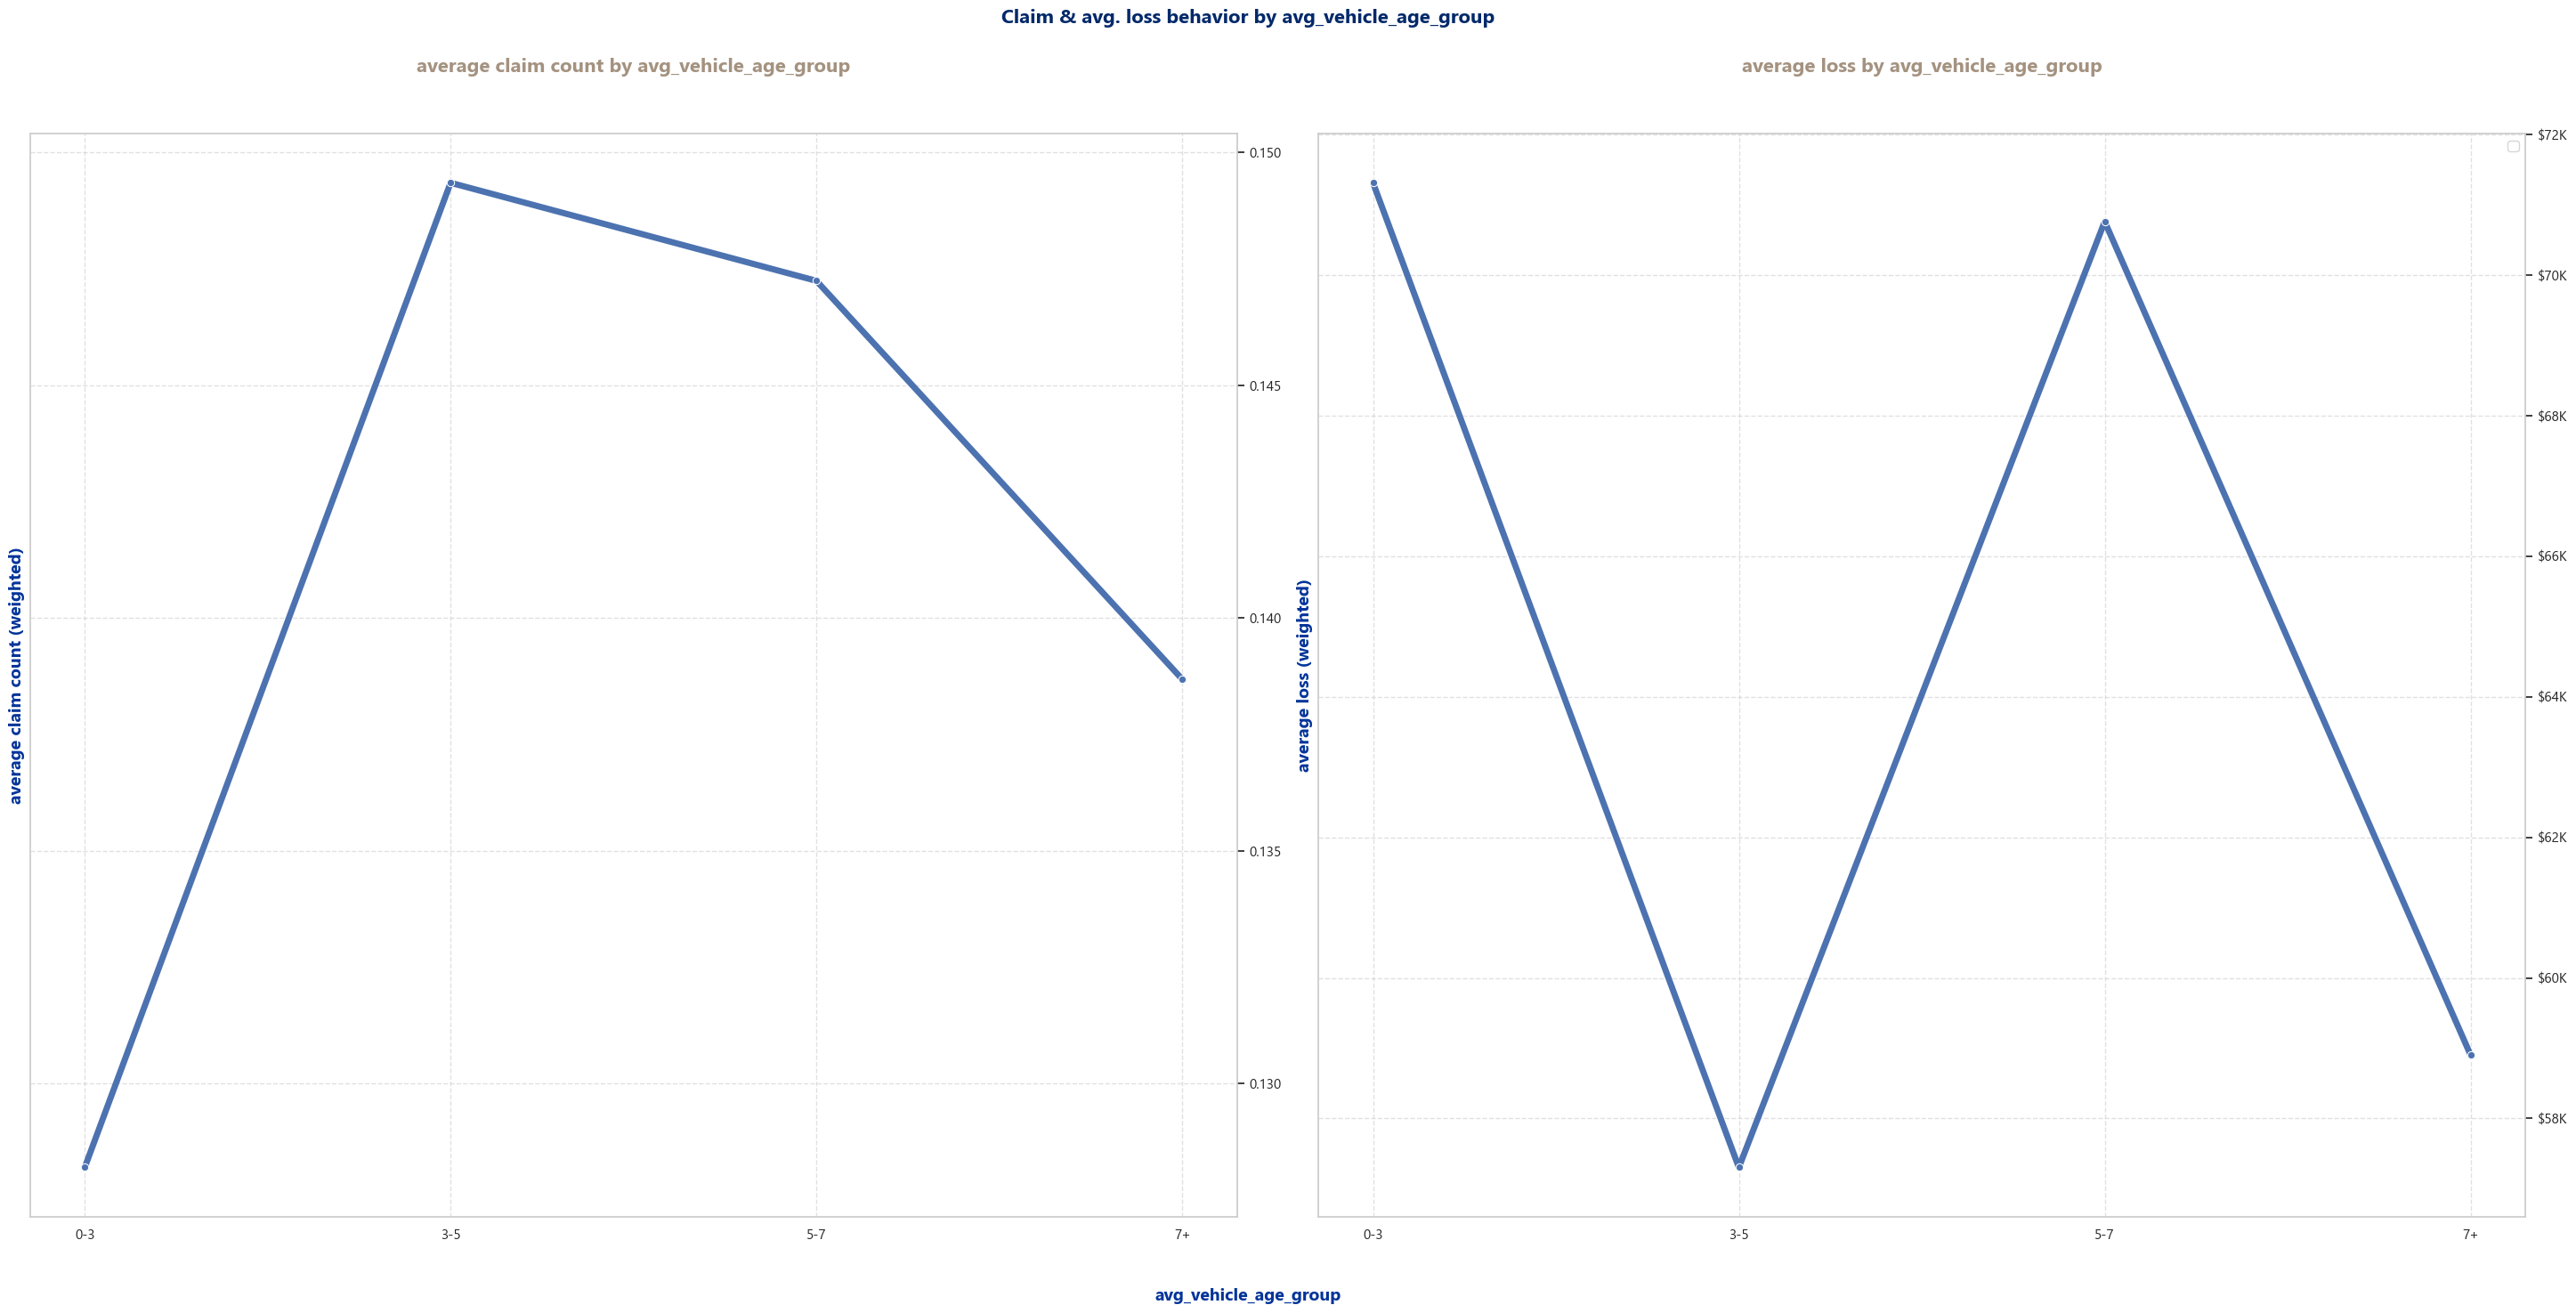

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

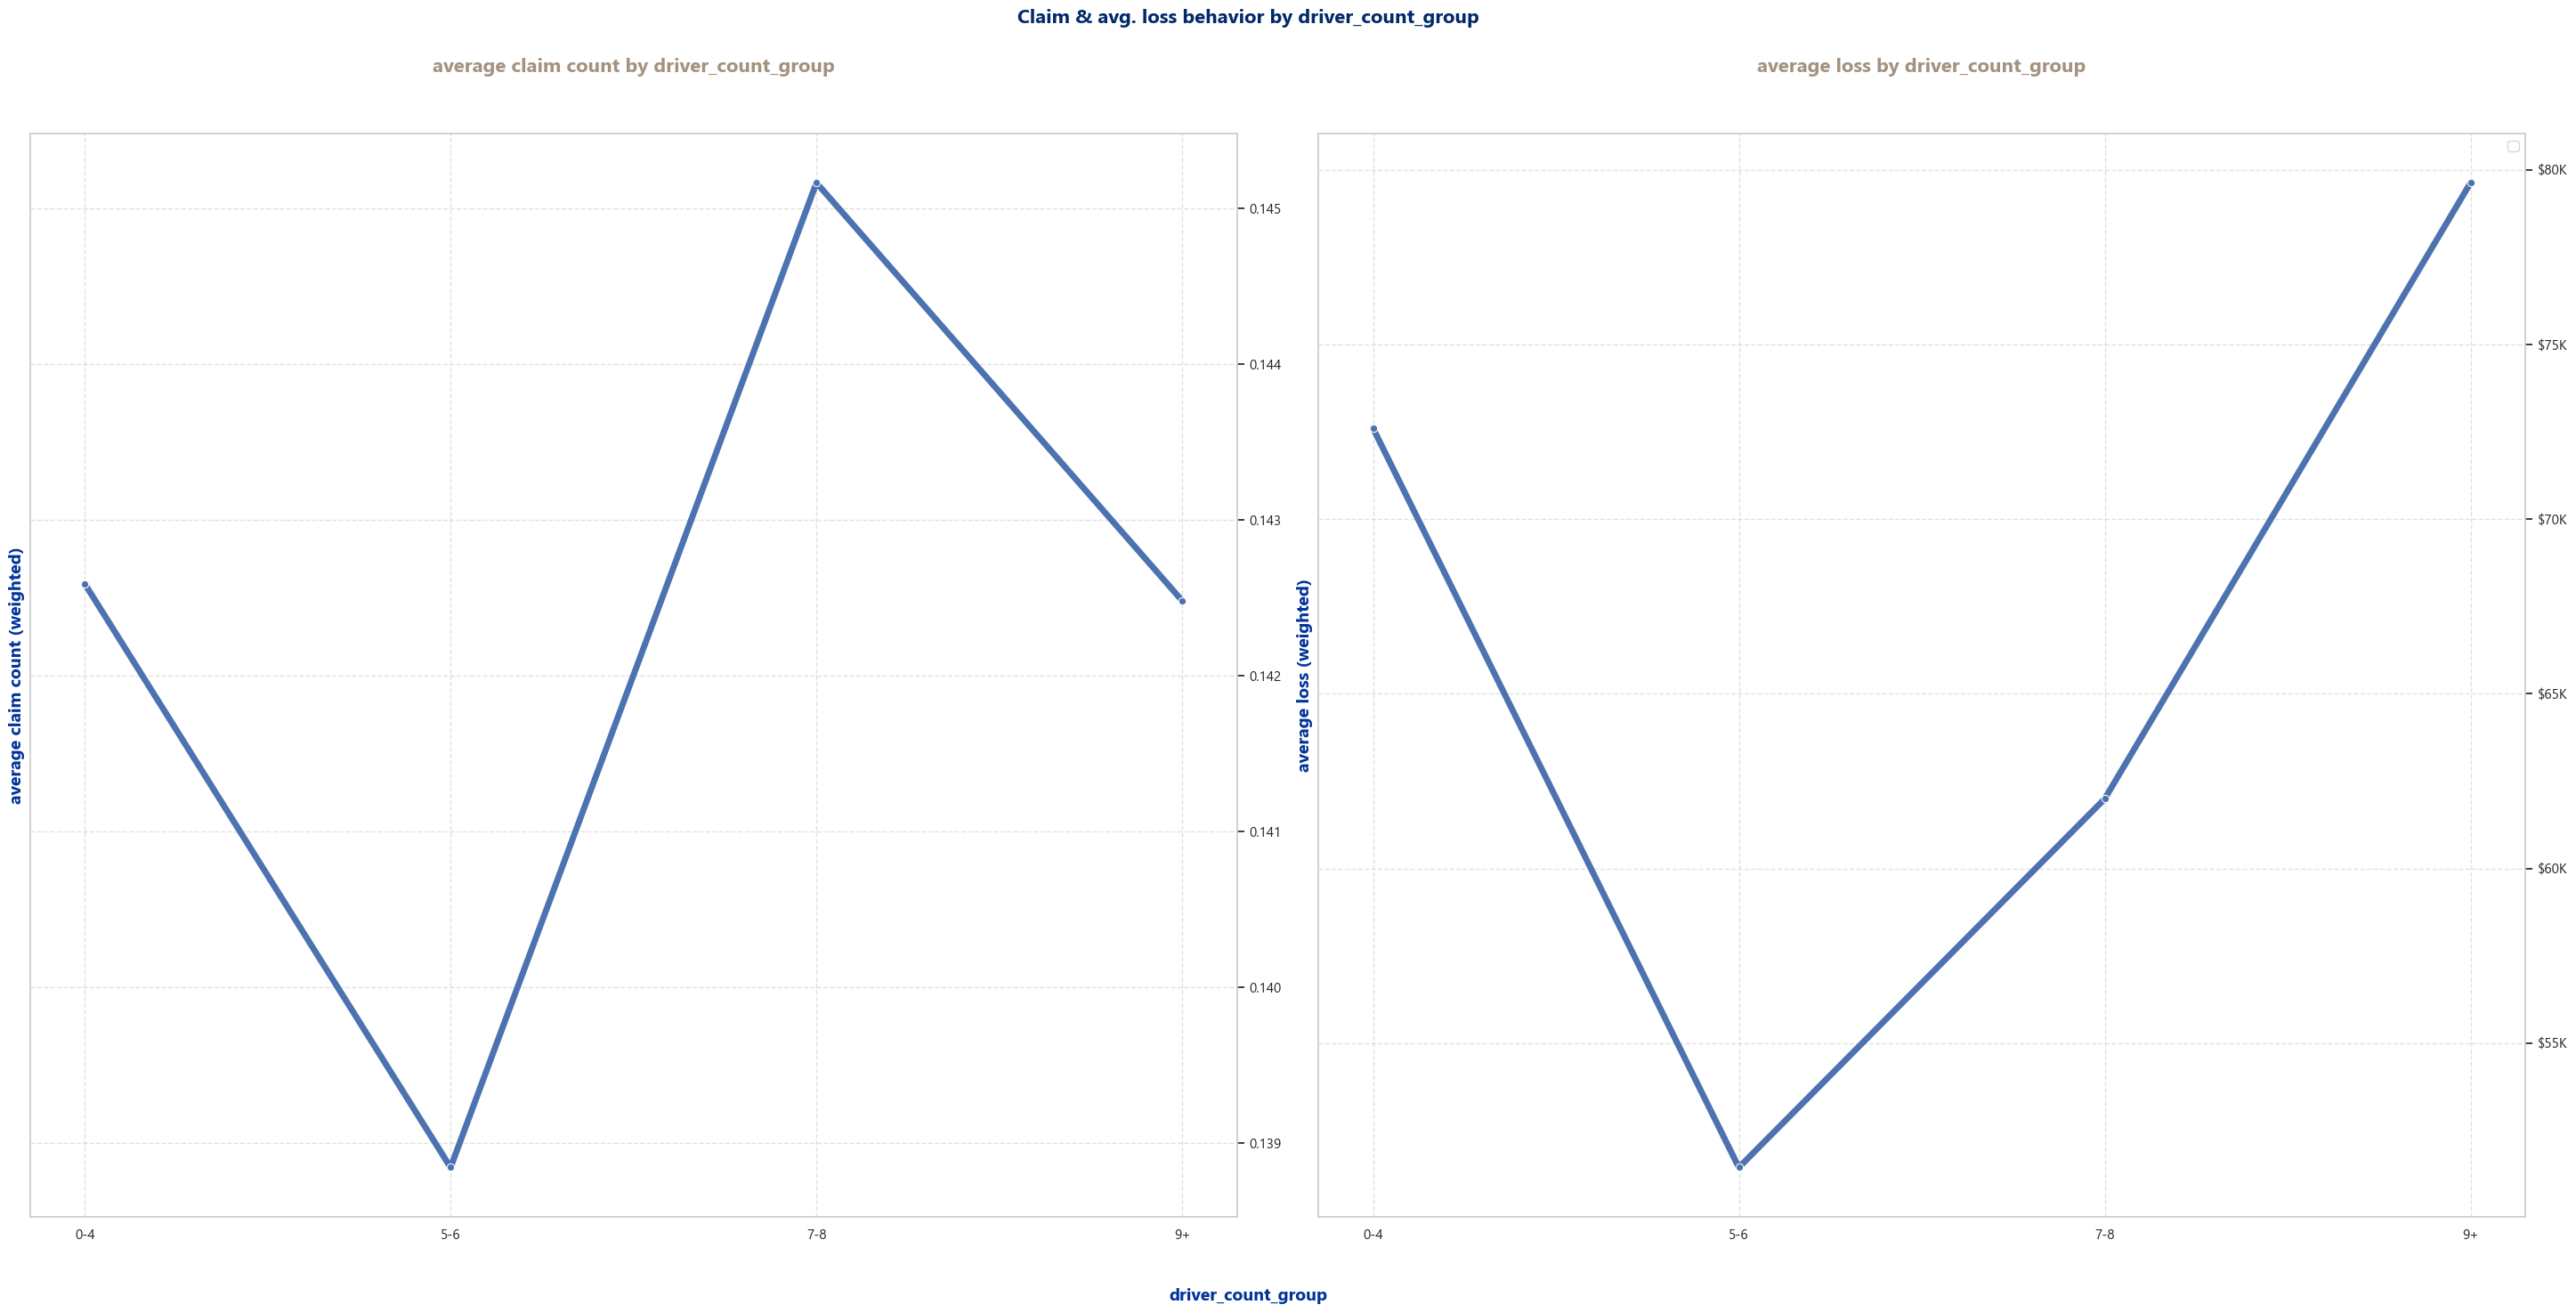

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

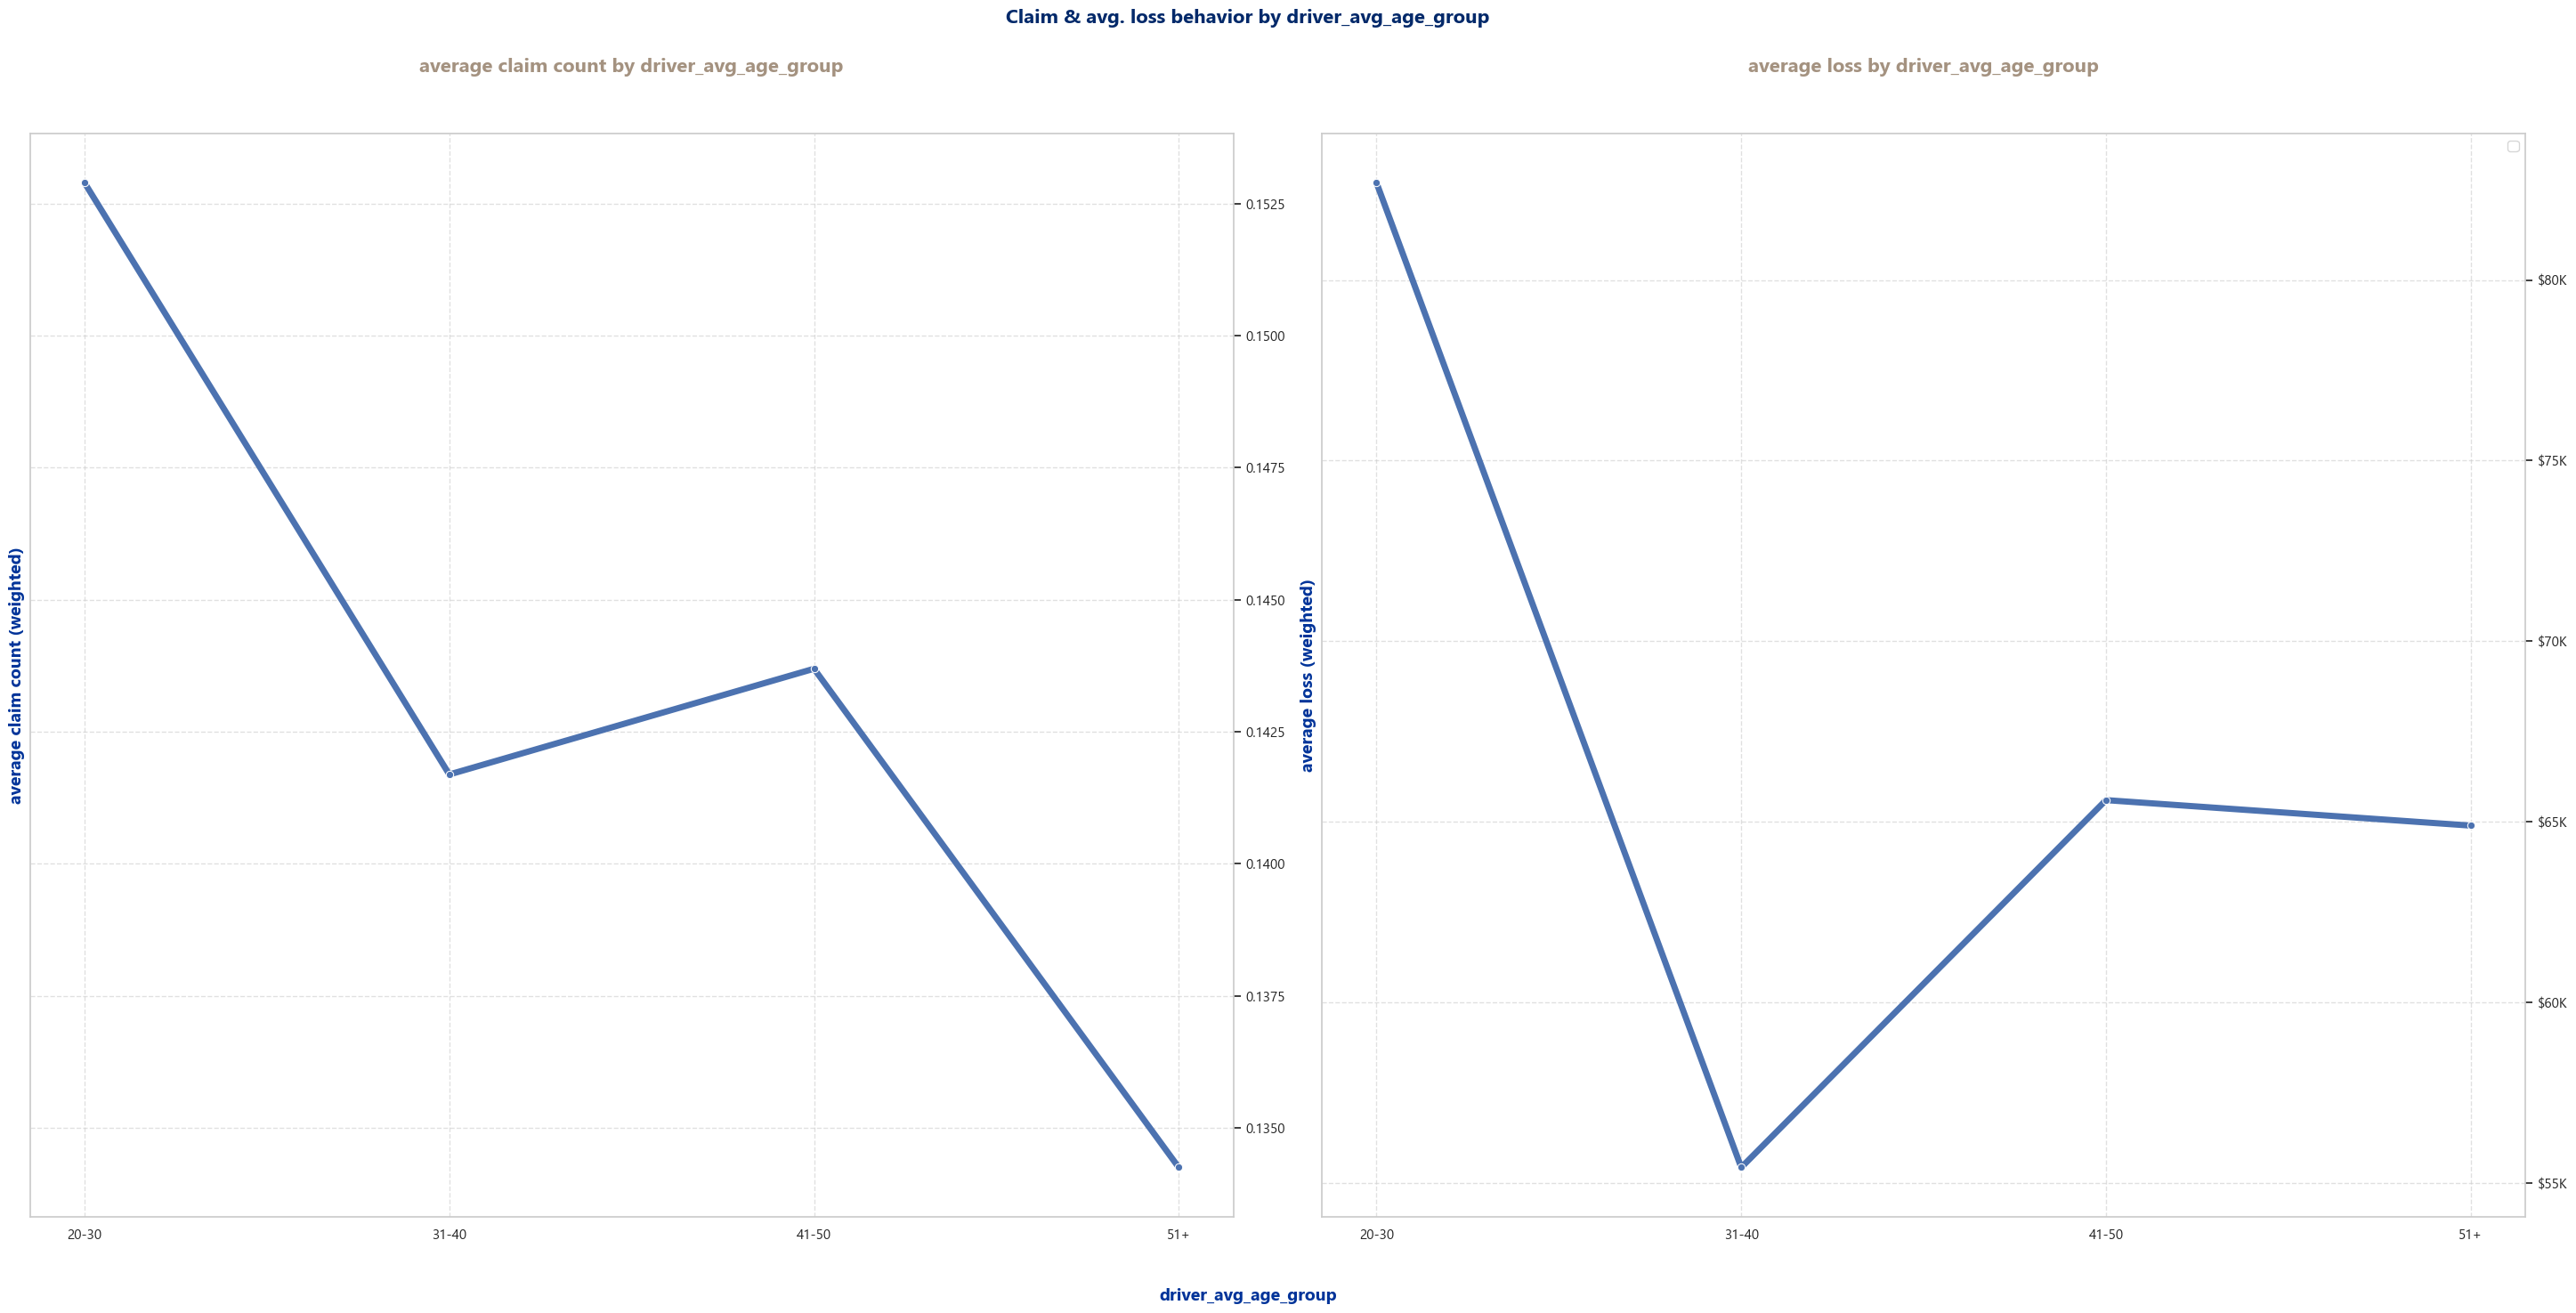

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

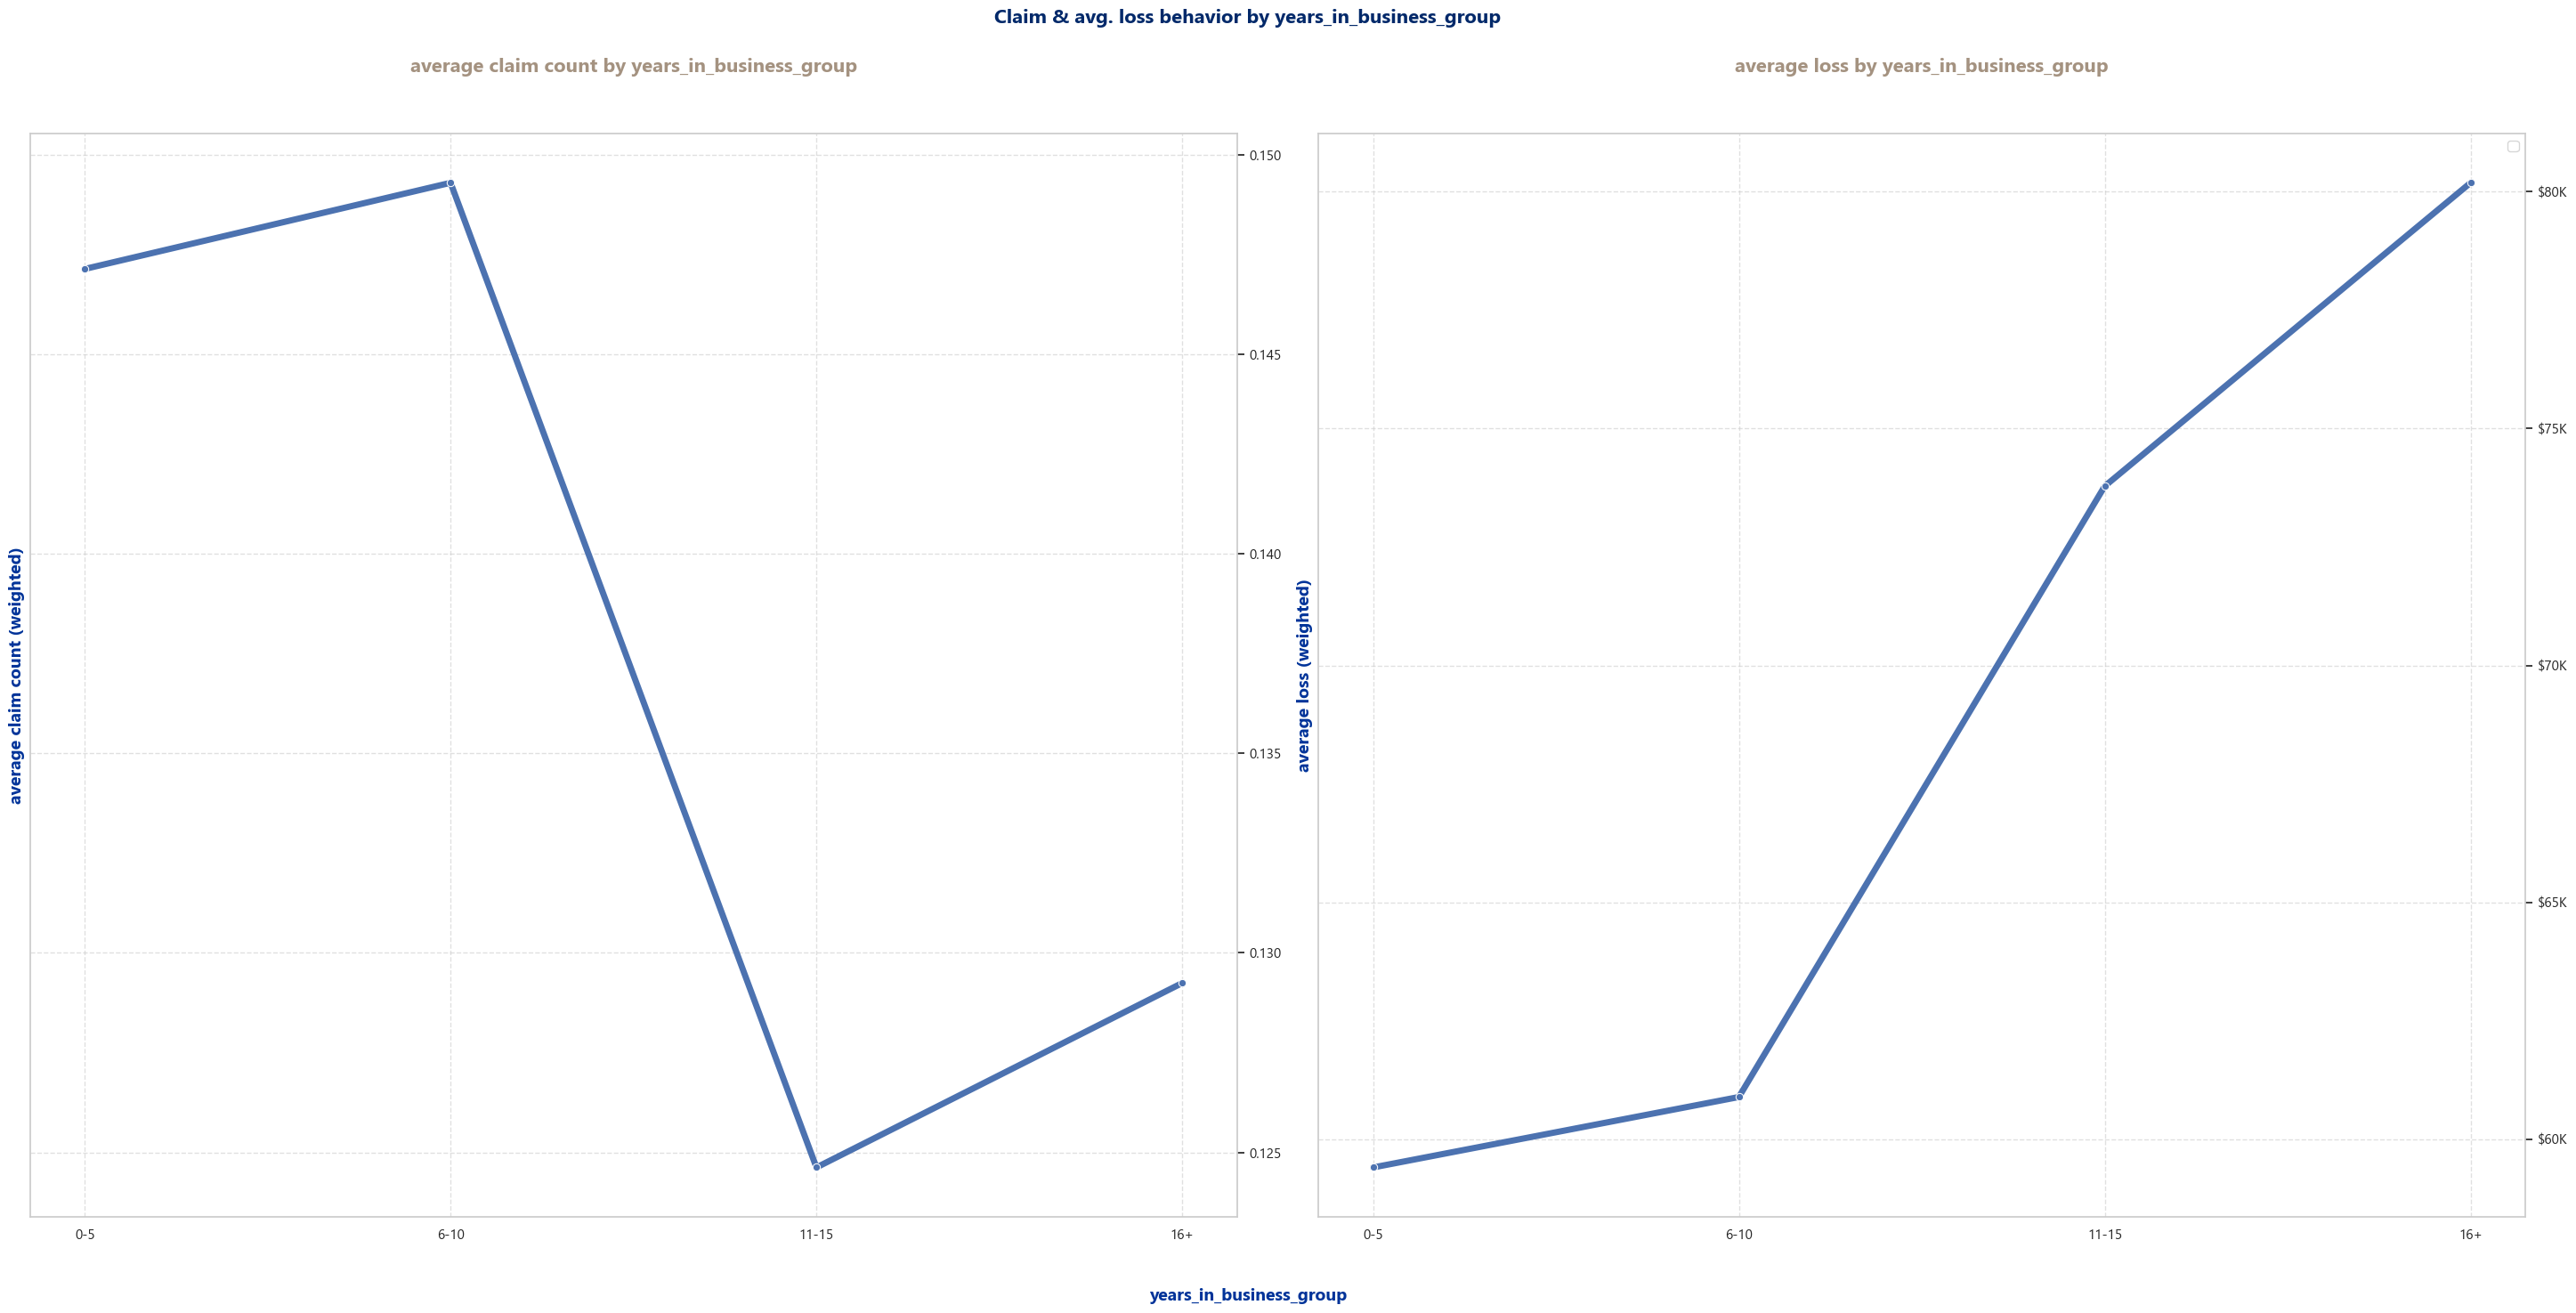

C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_weighted = df_grouped.groupby(feature).apply(weighted_average,
C:\Users\saul1\AppData\Local\Temp\ipykernel_22800\2269410944.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior i

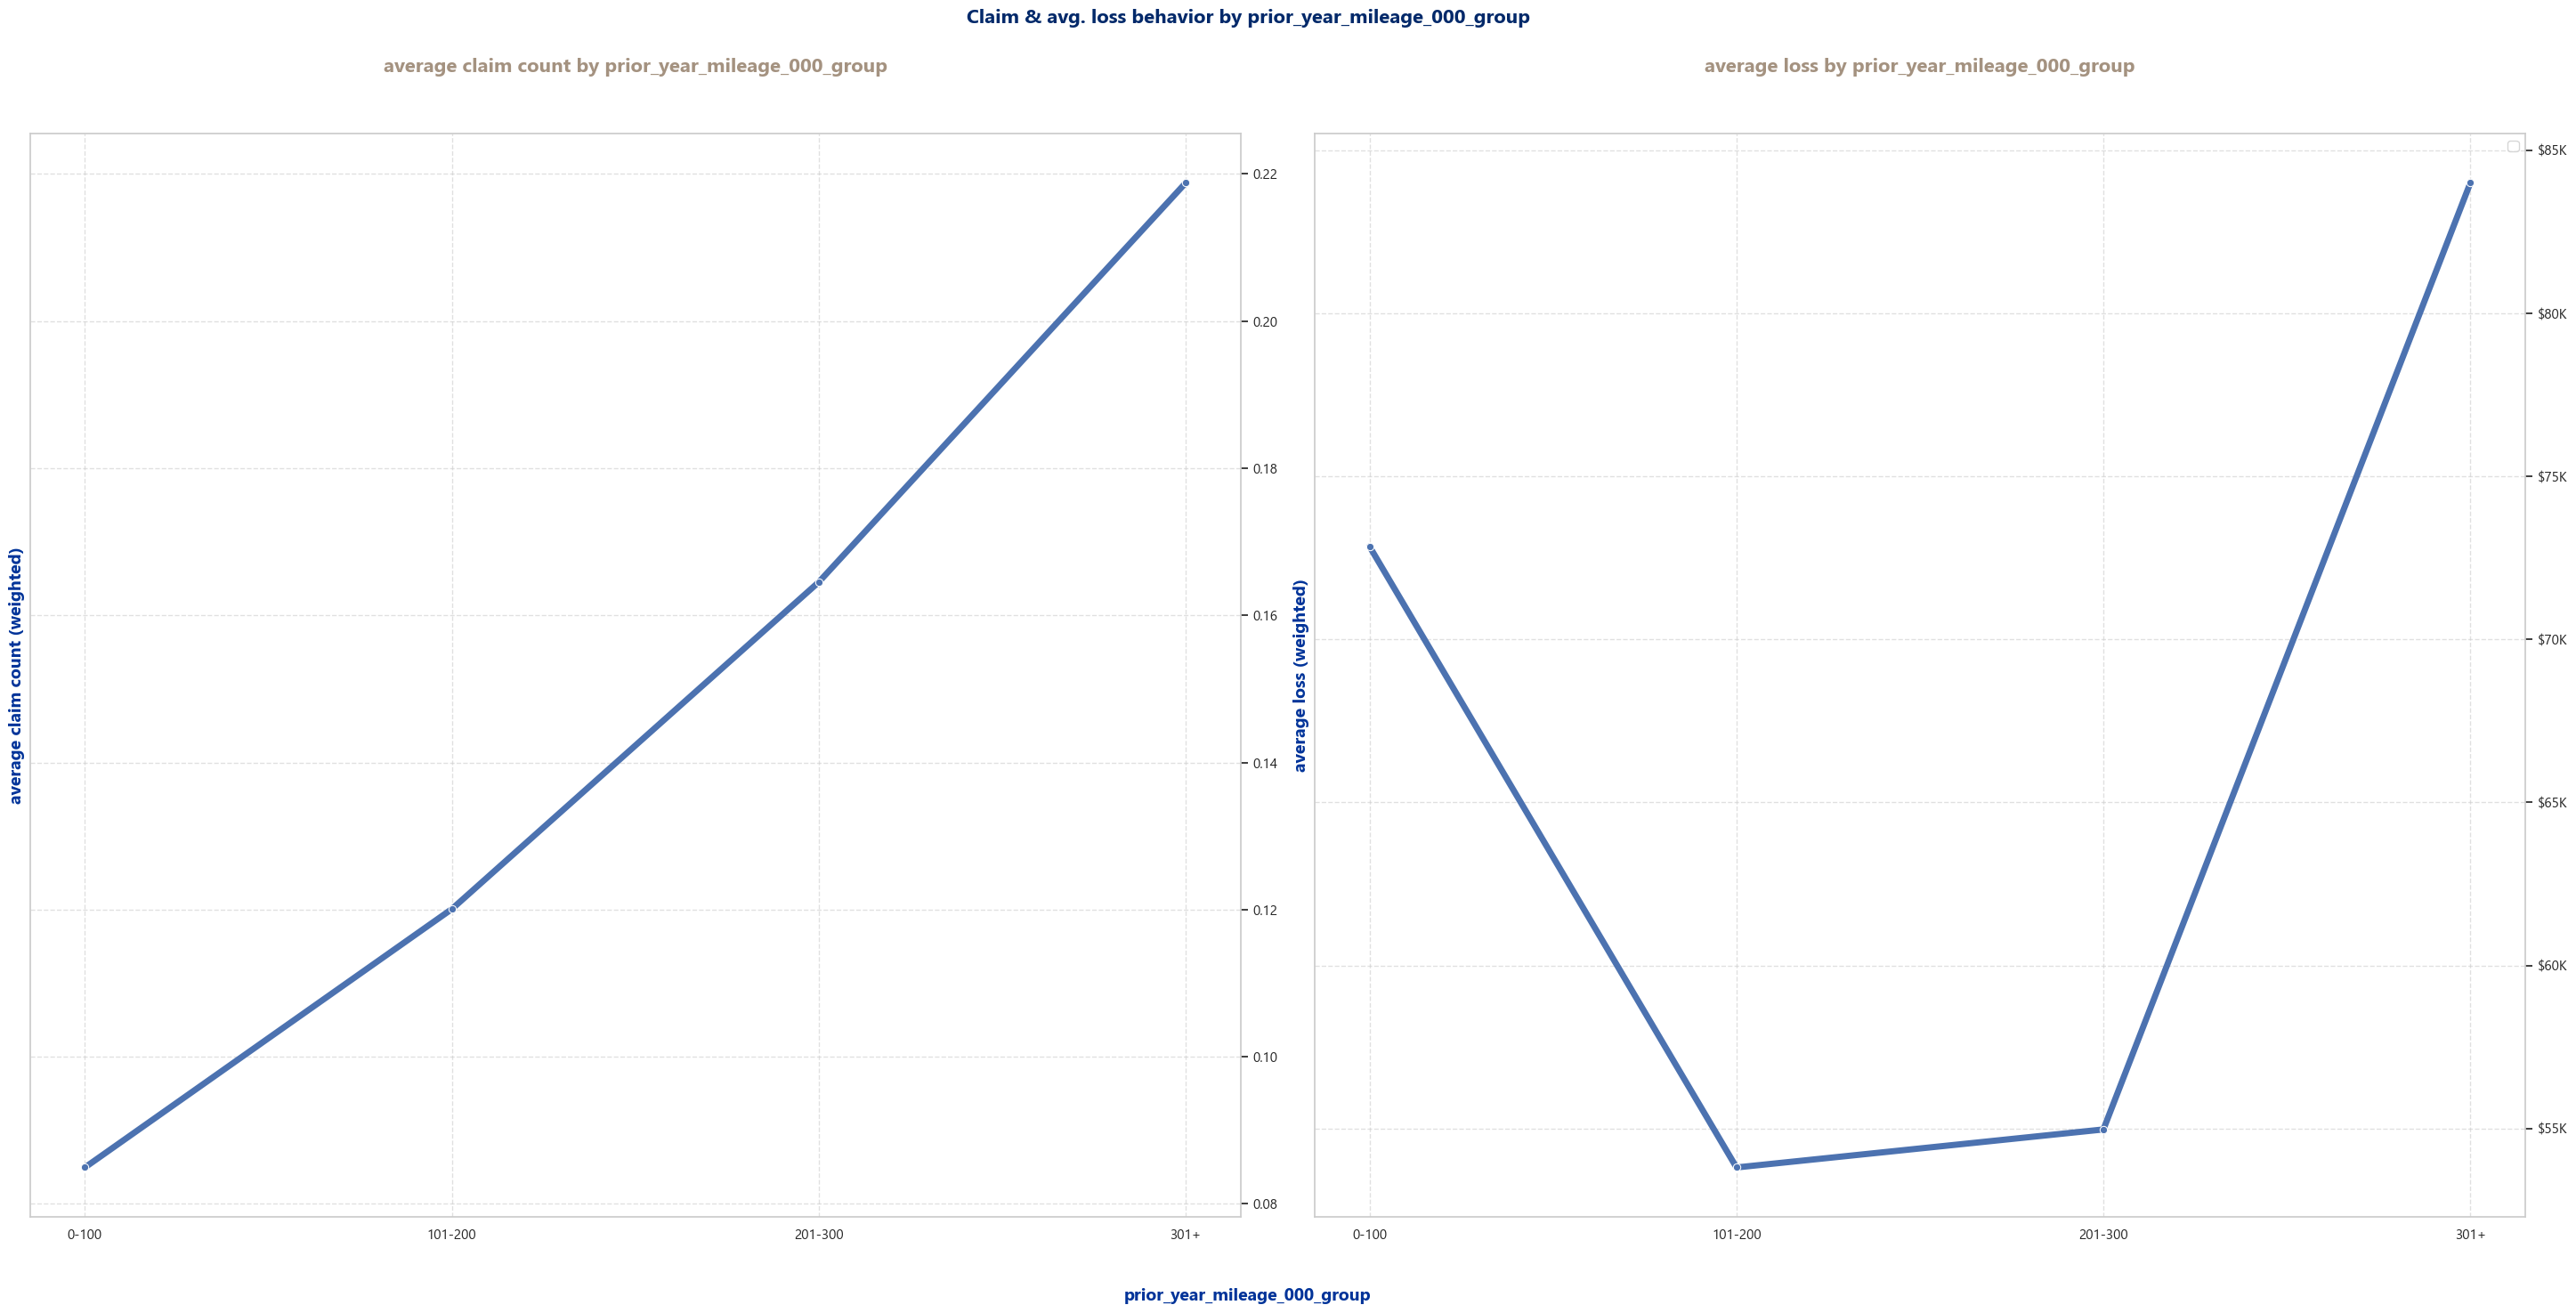

In [900]:
features_weighted = ['vehicle_count_group', 'avg_vehicle_age_group', 'driver_count_group', 'driver_avg_age_group', 'years_in_business_group', 'prior_year_mileage_000_group']
for feature in features_weighted:
    df_grouped = df_train_auto_policies[[feature, 'claim_count', 'policy_id']].groupby([feature, 'claim_count']).count().reset_index()[[feature, 'claim_count', 'policy_id']]
    df_weighted = df_grouped.groupby(feature).apply(weighted_average, 
                                     'claim_count', 'policy_id').reset_index().rename(columns={0: 'weighted_avg_claim_count'})

    df_weighted_loss = df_claims.groupby(feature).apply(weighted_average, 
                                     'avg_loss', 'claim_count').reset_index().rename(columns={0: 'weighted_avg_loss'})

    fig, ax = plt.subplots(1, 2, figsize=(30, 15))


    sns.lineplot(
        df_weighted,
        x=feature, y="weighted_avg_claim_count",
        linewidth=5,
        ax=ax[0],
        marker="o"
    )

    ax[0].yaxis.tick_right()
    ax[0].grid(True, linestyle="--", alpha = 0.6)
    ax[0].set_xlabel('')
    ax[0].set_ylabel('average claim count (weighted)',fontsize=14,fontweight='bold', color='#003399')
    ax[0].set_title(f"average claim count by {feature}", y=1.04, fontsize=16, pad=15, fontweight='bold', color = '#A49280')
    ax[0].grid(True, linestyle="--", alpha = 0.6)
    ax[0].yaxis.tick_right()

    sns.lineplot(
        df_weighted_loss,
        x=feature, y="weighted_avg_loss",
        linewidth=5,
        ax=ax[1],
        marker="o"
    )

    ax[1].yaxis.tick_right()
    ax[1].grid(True, linestyle="--", alpha = 0.6)
    ax[1].set_xlabel('')
    ax[1].set_ylabel('average loss (weighted)',fontsize=14,fontweight='bold', color='#003399')
    ax[1].set_title(f"average loss by {feature}", y=1.04, fontsize=16, pad=15, fontweight='bold', color = '#A49280')
    ax[1].grid(True, linestyle="--", alpha = 0.6)
    ax[1].yaxis.tick_right()
    ax[1].get_yaxis().set_major_formatter(
    FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}'))

    fig.suptitle(f"Claim & avg. loss behavior by {feature}", fontsize=16, fontweight='bold', color = '#02296A')
    fig.supxlabel(feature, fontsize=14 ,fontweight='bold', color = '#003399')


    plt.legend()
    plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
    plt.show()

In [901]:
# Now for the analysis for choosing the best model, we will check:
# A correlation matrix to formalize the relationships between the features and the target variables
# VIF to check for multicollinearity between the features
# Box-Tidwell test to check if our data is apropriate for a logistic regression model
# First we will divide our data and save the random state for reproducibility, we will use 80% of the data for training and 20% for testing
feat_cols = [
    "coverage_type",
    "vehicle_count", "vehicle_avg_age", "driver_count", "driver_avg_age",
    "years_in_business", "prior_year_mileage_000",
    "business_type", "state",
    "prior_apd_claim_count", "prior_al_claim_count", "prior_loss_amount",
    "risk_score_external", "num_heavy_vehicles", "policy_expiration_date_year_month_numeric"
]
targets = ["had_claim_binary", "claim_count", "avg_loss"]


X = df_train_auto_policies[feat_cols]
y = df_train_auto_policies[targets]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y['had_claim_binary'])

train_data = pd.concat([X_train, y_train], axis=1)



In [902]:
#first we will encode our data, this step will be saved to the pipeline for the logistic regression model

state_category = ['AZ','TX','NY','IL','FL','OH','GA','WA','NC','CO','CA','PA','infrequent']

coverage_encoder = OneHotEncoder(handle_unknown='infrequent_if_exist',drop='first').fit(train_data[['coverage_type']])
state_encoder = OneHotEncoder(handle_unknown='infrequent_if_exist',drop='first').fit(train_data[['state']])
business_encoder = OneHotEncoder(handle_unknown='infrequent_if_exist',drop='first').fit(train_data[['business_type']])

arr_coverage = coverage_encoder.fit_transform(train_data[['coverage_type']])
arr_state = state_encoder.fit_transform(train_data[['state']])
arr_business = business_encoder.fit_transform(train_data[['business_type']])

ohe_coverage_df = pd.DataFrame(arr_coverage.toarray(), columns=coverage_encoder.get_feature_names_out(['coverage_type']))
ohe_state_df = pd.DataFrame(arr_state.toarray(), columns=state_encoder.get_feature_names_out(['state']))
ohe_business_df = pd.DataFrame(arr_business.toarray(), columns=business_encoder.get_feature_names_out(['business_type']))

train_data = pd.concat([train_data, ohe_coverage_df], axis=1).drop(['coverage_type'], axis=1)
train_data = pd.concat([train_data, ohe_state_df], axis=1).drop(['state'], axis=1)
train_data = pd.concat([train_data, ohe_business_df], axis=1).drop(['business_type'], axis=1)



train_data.columns

Index(['vehicle_count', 'vehicle_avg_age', 'driver_count', 'driver_avg_age',
       'years_in_business', 'prior_year_mileage_000', 'prior_apd_claim_count',
       'prior_al_claim_count', 'prior_loss_amount', 'risk_score_external',
       'num_heavy_vehicles', 'policy_expiration_date_year_month_numeric',
       'had_claim_binary', 'claim_count', 'avg_loss', 'coverage_type_APD',
       'state_CA', 'state_CO', 'state_FL', 'state_GA', 'state_IL', 'state_NC',
       'state_NY', 'state_OH', 'state_PA', 'state_TX', 'state_WA',
       'business_type_construction', 'business_type_other',
       'business_type_retail', 'business_type_service',
       'business_type_trucking'],
      dtype='object')

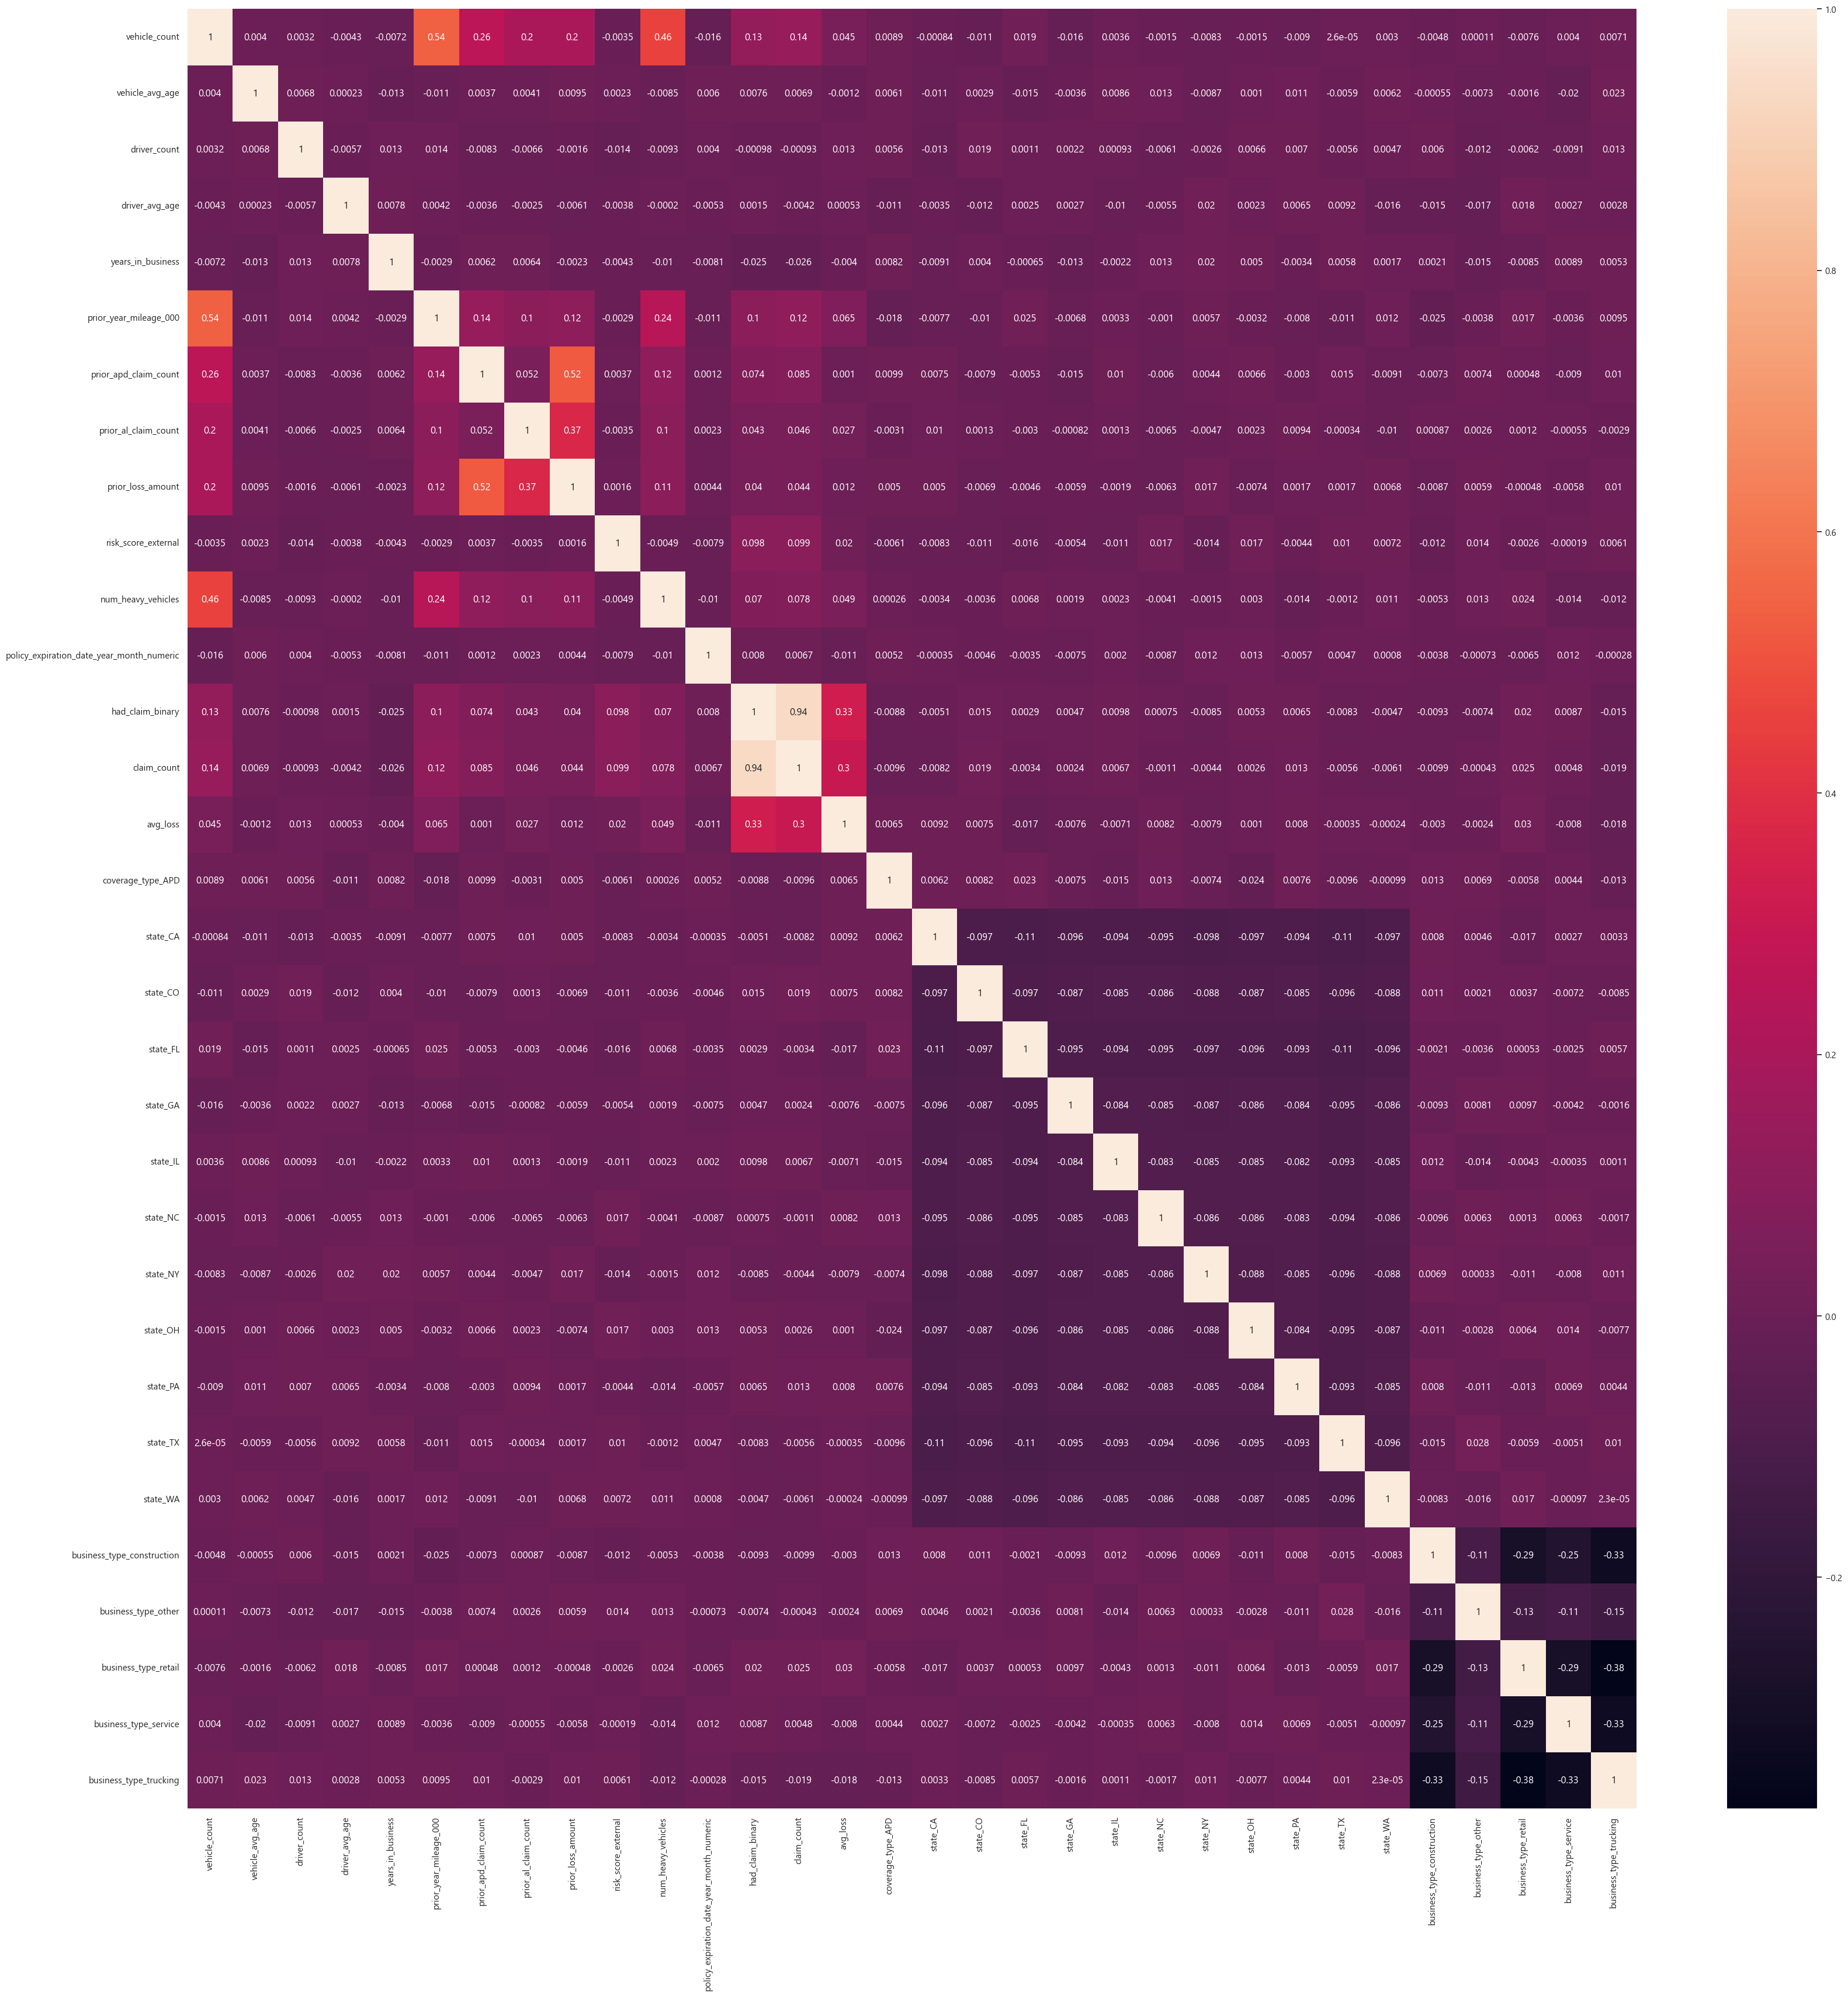

In [903]:
# correlation heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(train_data.corr(), annot=True)
plt.show()

In [904]:
# calculating VIF for each feature, very computationally expensive
cleaned_train_data = train_data.drop(['had_claim_binary', 'claim_count', 'avg_loss'], axis=1)
cleaned_train_data = cleaned_train_data.fillna(0)  # Fill NaN values with 0 or any other appropriate value
vif_data = pd.DataFrame()
vif_data["feature"] = cleaned_train_data.columns

vif_data["VIF"] = [variance_inflation_factor(cleaned_train_data.values, i)
                          for i in range(len(cleaned_train_data.columns))]
print(vif_data)

                                      feature          VIF
0                               vehicle_count 3.9647001737
1                             vehicle_avg_age 1.7147992375
2                                driver_count 2.0300414349
3                              driver_avg_age 3.1440591856
4                           years_in_business 1.1874597243
5                      prior_year_mileage_000 1.7369235140
6                       prior_apd_claim_count 1.5562941524
7                        prior_al_claim_count 1.2643817454
8                           prior_loss_amount 1.6152085712
9                         risk_score_external 1.4108309983
10                         num_heavy_vehicles 1.6100228709
11  policy_expiration_date_year_month_numeric 6.8606966114
12                          coverage_type_APD 1.1698365856
13                                   state_CA 2.0212852116
14                                   state_CO 1.8611309225
15                                   state_FL 2.01500849

In [905]:
#the results seem to be ok, we will keep the features as they are, we will check the box-tidwell test next but before that 
# lets see if we have enough data for the logistic regression model

train_data.groupby('had_claim_binary').count()

#(28*10/(1482/(1482+10514))) = 2,276.42, we have enough data for the logistic regression model, we will check the box-tidwell test next

,vehicle_count,vehicle_avg_age,driver_count,driver_avg_age,years_in_business,prior_year_mileage_000,prior_apd_claim_count,prior_al_claim_count,prior_loss_amount,risk_score_external,...,state_NY,state_OH,state_PA,state_TX,state_WA,business_type_construction,business_type_other,business_type_retail,business_type_service,business_type_trucking
had_claim_binary,,,,,,,,,,,,,,,,,,,,,
0.0000000000,10514,10514,10514,10111,10514,9892,10514,10514,9684,9993,...,8383,8383,8383,8383,8383,8383,8383,8383,8383,8383
1.0000000000,1482,1482,1482,1417,1482,1381,1482,1482,1355,1409,...,1210,1210,1210,1210,1210,1210,1210,1210,1210,1210


In [906]:
# box tidewell test, only for continuous variables (generated by Gemini)
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Copiar datos y definir variables
df_bt = train_data.copy()
continuous_vars = ['vehicle_avg_age', 'driver_avg_age', 'years_in_business', 'prior_year_mileage_000', 'prior_loss_amount', 'risk_score_external']

# !!! REEMPLAZA 'is_claim' POR EL NOMBRE REAL DE TU VARIABLE OBJETIVO (DEBE SER BINARIA: 0 O 1) !!!
target_var = 'had_claim_binary' 

# 2. Crear los términos de interacción x * ln(x) evadiendo valores <= 0
list_logx = []
for col in continuous_vars:
    logx_name = f"{col}_logx"
    # Reemplazamos 0 por NaN para evitar que np.log falle o devuelva -infinito
    df_bt[logx_name] = df_bt[col] * np.log(df_bt[col].replace(0, np.nan))
    list_logx.append(logx_name)

# 3. Construir la fórmula correcta
# El test de Box-Tidwell requiere incluir TODAS las variables y SUS interacciones en un mismo modelo
all_features = continuous_vars + list_logx
bt_formula = f"{target_var} ~ " + " + ".join(all_features)

print("Fórmula generada para el test:")
print(bt_formula, "\n")

# 4. Ajustar el modelo GLM Binomial (Regresión Logística)
bt_model = smf.glm(
    bt_formula, data=df_bt, family=sm.families.Binomial()
).fit()

# 5. Imprimir los p-values de los términos de interacción
# Si el p-value de un término '_logx' es < 0.05, esa variable NO es lineal respecto al logit
print("P-values de las interacciones Box-Tidwell:")
print(bt_model.pvalues[list_logx])

Fórmula generada para el test:
had_claim_binary ~ vehicle_avg_age + driver_avg_age + years_in_business + prior_year_mileage_000 + prior_loss_amount + risk_score_external + vehicle_avg_age_logx + driver_avg_age_logx + years_in_business_logx + prior_year_mileage_000_logx + prior_loss_amount_logx + risk_score_external_logx 

P-values de las interacciones Box-Tidwell:
vehicle_avg_age_logx          0.4304223863
driver_avg_age_logx           0.0205961362
years_in_business_logx        0.0759051743
prior_year_mileage_000_logx   0.4582077144
prior_loss_amount_logx        0.5766282695
risk_score_external_logx      0.9338207395
dtype: float64


In [907]:
#driver avg age doesn't pass the test and years in business comes very close,
#  however we will continue as is to get a better idea of how the data will fare with the corrected LogR

In [ ]:
train_data

Index(['vehicle_count', 'vehicle_avg_age', 'driver_count', 'driver_avg_age',
       'years_in_business', 'prior_year_mileage_000', 'prior_apd_claim_count',
       'prior_al_claim_count', 'prior_loss_amount', 'risk_score_external',
       'num_heavy_vehicles', 'policy_expiration_date_year_month_numeric',
       'coverage_type_APD', 'state_CA', 'state_CO', 'state_FL', 'state_GA',
       'state_IL', 'state_NC', 'state_NY', 'state_OH', 'state_PA', 'state_TX',
       'state_WA', 'business_type_construction', 'business_type_other',
       'business_type_retail', 'business_type_service',
       'business_type_trucking'],
      dtype='object')